# Assignment 16 --- Comparative evaluation of RNN-, LSTM- and GRU-based video indexing models

**Md. Shoaib Abdullah Khan · ID: 2010976135**

Videos of clean and dirty places are indexed as **Clean** or **Dirty** by three recurrent models that read the same
sequence of ResNet-50 frame features: a vanilla **RNN**, an **LSTM** and a **GRU**. Two non-recurrent baselines show what
temporal modelling adds: a **single-frame** classifier and an order-free **mean-pooling** classifier.

| Assignment task | Where |
|---|---|
| 1. Video dataset collection, labels, train / validation / test split | §1 |
| 2. Frame extraction at a fixed rate, resizing, normalisation, pretrained CNN features, feature sequences | §2 |
| 3. RNN, LSTM and GRU indexing models | §3 |
| 4. Training, accuracy / precision / recall / F1 / confusion matrices, inference time, parameters | §4, §5, §7 |
| 4. Effect of sequence length and frame-sampling rate | §6 |
| 5. Comparison: performance, temporal information, complexity, parameters, robustness | §7, §8, §9, §12 |
| 5. Misclassified videos; temporal vs. single-frame classification | §8, §10 |
| 6. Video index, search interface, retrieval, timestamps of dirty places | §11 |
| Deliverables and comparative table | §12 |

**Dirty = positive class** for precision, recall and F1. A *video-level* decision indexes a whole video; a *timestamp*
decision says when inside a video a dirty place is visible (§11). The two are evaluated separately.

## 0. Environment

In [1]:
# %pip install -q torch torchvision scikit-learn pandas matplotlib opencv-python imageio-ffmpeg "gradio<6"

In [2]:
import os, sys, json, time, math, random, warnings, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch, cv2
import matplotlib, matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
FIG, RES = ROOT / "outputs" / "figures", ROOT / "outputs" / "results"
for p in (FIG, RES, ROOT / "annotations"):
    p.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8f8d86", "legend.frameon": False, "lines.linewidth": 2})
CELLS, BASELINES = ["RNN", "LSTM", "GRU"], ["MLP-frame", "MLP-mean"]
ALL = CELLS + BASELINES
COL = {"RNN": "#2a78d6", "LSTM": "#eb6834", "GRU": "#1baf7a", "MLP-frame": "#8f8d86", "MLP-mean": "#52514e",
       "RNN-448": "#2a78d6"}
LS = {"MLP-frame": "--", "MLP-mean": ":", "RNN-448": "-."}
CLASS_COL = ["#2a78d6", "#eb6834"]          # Clean, Dirty
NICE = {"RNN": "RNN", "LSTM": "LSTM", "GRU": "GRU", "MLP-frame": "single frame", "MLP-mean": "mean pooling"}

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    # a copy without the "Figure N." title for the LaTeX report, which numbers its figures itself
    titles = [t for t in [fig._suptitle] + [ax.title for ax in fig.axes] if t is not None and t.get_text().startswith("Figure")]
    for t in titles: t.set_visible(False)
    (FIG / "report").mkdir(exist_ok=True)
    fig.savefig(FIG / "report" / f"{name}.png", bbox_inches="tight", facecolor="white")
    for t in titles: t.set_visible(True)
    plt.show()

def save(df, name, index=False):
    df.to_csv(RES / f"{name}.csv", index=index, encoding="utf-8-sig")      # BOM so that "±" opens correctly in Excel
    return df

def pm(x, d=3):
    x = np.asarray(x, float)
    return f"{np.nanmean(x):.{d}f} ± {np.nanstd(x):.{d}f}" if len(x) > 1 else f"{x[0]:.{d}f}"

print("torch", torch.__version__, "| CUDA", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print("opencv", cv2.__version__)

torch 2.7.1+cu128 | CUDA True NVIDIA GeForce RTX 5070 Ti
opencv 4.13.0


## 1. Video dataset

The videos are in `data/clean` (label **Clean**) and `data/garbage` (label **Dirty**); the folder is the label.
`vi_data.py` builds the catalogue, removes byte-identical copies (MD5), groups clips from the same outing, splits the data,
decodes frames, applies the test-time image changes of §9 and extracts the CNN features of §2.

In [3]:
%%writefile vi_data.py
"""Video catalogue, grouped split, frame decoding, frame perturbations and ResNet-50 frame features.

Every expensive step writes to `outputs/` and is skipped when its output already exists."""
import hashlib, json, math, random, subprocess
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import torch
from PIL import Image

ROOT = Path(__file__).resolve().parent
DATA = ROOT / "data"
OUT = ROOT / "outputs"
FRAMES = OUT / "frames"            # decoded frames, BASE_FPS, short side 320 px, JPEG
FEATS = OUT / "features"           # ResNet-50 features per video (original + horizontally flipped frame)
PREVIEWS = OUT / "previews"        # small H.264 copies for the retrieval interface
BASE_FPS = 8                       # every sampling rate used later (0.5 ... 8 fps) is a subsample of this grid
SHORT = 320
CLASSES = ["Clean", "Dirty"]
FOLDER_LABEL = {"clean": 0, "garbage": 1, "dirty": 1}
VIDEO_EXT = {".mp4", ".mov", ".avi", ".mkv", ".m4v"}

# Capture sessions of the clean phone videos (same day = same outing; those videos must stay in the same split).
# Each stock dirty clip comes from a different source and forms its own group.
SESSIONS = {"VID_20211030": "C-2021-10-30", "VID_20220831": "C-2022-08-31", "VID_20250526": "C-2025-05-26",
            "VID_20250114": "C-2025-01-beach", "VID_20250115": "C-2025-01-beach"}

# Visual description of every clip (written after watching them). capture: handheld / vehicle / static / drone.
SCENES = {
    "VID_20211030_081246_HSR_120.mp4": ("village path, trees", "sunny", "handheld walk"),
    "VID_20211030_091821.mp4": ("playground, slide tunnel", "sunny", "handheld walk"),
    "VID_20220510_125429_HSR_120.mp4": ("campus road, motorbike", "overcast", "static"),
    "VID_20220805_092010.mp4": ("river bank, greenery", "cloudy", "handheld pan"),
    "VID_20220831_143850.mp4": ("campus field, building", "sunny", "handheld pan"),
    "VID_20220831_144134_HSR_120.mp4": ("campus field, trees", "hazy sun", "handheld pan"),
    "VID_20240218_152823.mp4": ("sandy river bank", "backlit sun", "handheld walk"),
    "VID_20240322_164935.mp4": ("rural road, fields", "low evening sun", "vehicle"),
    "VID_20250105_093313.mp4": ("courtyard, person", "fog", "handheld"),
    "VID_20250114_102416.mp4": ("sea beach, people", "sunny", "handheld walk"),
    "VID_20250115_121605.mp4": ("sea beach from motorbike", "sunny", "vehicle"),
    "VID_20250526_143925.mp4": ("football field", "overcast", "handheld pan"),
    "VID_20250526_144159.mp4": ("football field", "overcast", "handheld pan"),
    "VID_20250526_144309.mp4": ("football field", "overcast", "handheld pan"),
    "VID_20250526_144331.mp4": ("football field", "overcast", "handheld pan"),
    "VID_20260611_154737.mp4": ("campus road, puddles", "rain", "handheld pan"),
    "VID_20260728_131314.mp4": ("campus road, wet", "rain", "handheld walk"),
    "12487565_1920_1080_30fps.mp4": ("burning roadside dump, smoke", "daylight", "static"),
    "2952132-uhd_4096_2160_24fps.mp4": ("litter on woodland floor", "daylight", "slider"),
    "3186589-uhd_3840_2160_30fps.mp4": ("landfill from above", "daylight", "drone"),
    "3695935-hd_1920_1080_24fps.mp4": ("dump with sticks", "bright", "static"),
    "3999624-uhd_3840_2160_24fps.mp4": ("litter at a drain grate", "daylight", "static"),
    "4279368-hd_1920_1080_30fps.mp4": ("pile of garbage bags", "daylight", "slow pan"),
    "4445847-uhd_3840_2160_30fps.mp4": ("landfill, top-down", "daylight", "drone"),
    "4513383-hd_1920_1080_30fps.mp4": ("garbage heap then waste land", "hazy", "drone"),
    "4855723-hd_1920_1080_25fps.mp4": ("polluted canal, bamboo", "daylight", "static"),
    "vecteezy_plastic-trash-waste-moving-on-a-conveyor-at-the-garbage_5485456.mp4": ("waste on a conveyor", "indoor", "static"),
    "vecteezy_pollution-concept-garbage-pile-in-trash-dump-or-landfill_12825825.mp4": ("garbage pile close-up", "daylight", "slow pan"),
    "vecteezy_river-garbage-pollution_2015570.mov": ("garbage floating in a river", "daylight", "static"),
}


def md5(path, chunk=1 << 22):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()


def probe(path):
    c = cv2.VideoCapture(str(path))
    fps = c.get(cv2.CAP_PROP_FPS); n = int(c.get(cv2.CAP_PROP_FRAME_COUNT))
    ok, fr = c.read(); c.release()
    h, w = fr.shape[:2] if ok else (0, 0)   # OpenCV applies the rotation flag, so this is the displayed size
    return {"fps": fps, "n_frames": n, "duration_s": n / fps if fps else 0.0, "width": w, "height": h}


def catalogue(cache=OUT / "video_catalogue.csv"):
    """One row per unique video. Byte-identical copies (same MD5) are listed but marked duplicate=True."""
    if cache.exists():
        return pd.read_csv(cache)
    rows, seen = [], {}
    for folder in sorted(p for p in DATA.iterdir() if p.is_dir()):
        for f in sorted(folder.iterdir(), key=lambda p: ("(" in p.stem, p.name)):    # "x(1).mp4" after "x.mp4"
            if f.suffix.lower() not in VIDEO_EXT:
                continue
            h = md5(f)
            r = {"file": f"{folder.name}/{f.name}", "name": f.name, "folder": folder.name,
                 "label": FOLDER_LABEL[folder.name.lower()], "md5": h, "size_MB": f.stat().st_size / 1e6,
                 "duplicate_of": seen.get(h, ""), **probe(f)}
            seen.setdefault(h, r["file"])
            rows.append(r)
    df = pd.DataFrame(rows)
    df["duplicate"] = df.duplicate_of != ""
    df["class"] = df.label.map(dict(enumerate(CLASSES)))
    df["orientation"] = np.where(df.height > df.width, "portrait", "landscape")
    df["source"] = np.where(df.label == 0, "own phone", "stock (Pexels / Vecteezy)")
    df["group"] = [SESSIONS.get(n[:12], "C-" + n[4:19]) if l == 0 else "D-" + Path(n).stem[:28]
                   for n, l in zip(df.name, df.label)]
    for k, col in enumerate(["scene", "lighting", "capture"]):
        df[col] = [SCENES.get(n, ("", "", ""))[k] for n in df.name]
    # short ids: C01.. for clean, D01.. for dirty (duplicates get none)
    df["vid"] = ""
    for lab, p in [(0, "C"), (1, "D")]:
        m = (df.label == lab) & ~df.duplicate
        df.loc[m, "vid"] = [f"{p}{i + 1:02d}" for i in range(m.sum())]
    cache.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(cache, index=False)
    return df


# ------------------------------------------------------------------------------------------------ split
def grouped_split(df, seed, n_test=(4, 3), n_val=(3, 2), max_group=2):
    """Picks whole groups for test and validation until each reaches (clean, dirty) video counts.
    Only groups with <= max_group videos go to val/test, so one big session cannot fill a held-out set."""
    rng = random.Random(seed)
    split = {v: "train" for v in df.vid}
    for lab in (0, 1):
        groups = df[df.label == lab].groupby("group").vid.apply(list).to_dict()
        names = [g for g in sorted(groups) if len(groups[g]) <= max_group]
        rng.shuffle(names)
        for part, need in (("test", n_test[lab]), ("val", n_val[lab])):
            got = 0
            for g in list(names):
                if got + len(groups[g]) <= need:
                    for v in groups[g]:
                        split[v] = part
                    got += len(groups[g]); names.remove(g)
                if got == need:
                    break
    return df.vid.map(split)


def grouped_folds(df, k=5, seed=0):
    """Grouped, class-stratified k folds: groups of each class are dealt to the currently smallest fold."""
    rng = random.Random(seed)
    fold = {}
    for lab in (0, 1):
        groups = df[df.label == lab].groupby("group").vid.apply(list).to_dict()
        names = sorted(groups, key=lambda g: (-len(groups[g]), rng.random()))
        size = [0] * k
        for g in names:
            f = min(range(k), key=lambda i: (size[i], rng.random()))
            for v in groups[g]:
                fold[v] = f
            size[f] += len(groups[g])
    return df.vid.map(fold)


# ------------------------------------------------------------------------------------------------ frames
def sample_indices(n_frames, fps, rate=BASE_FPS):
    """Source-frame index nearest to every time k / rate."""
    times = np.arange(0, n_frames / fps, 1.0 / rate)
    idx = np.minimum(np.round(times * fps).astype(int), n_frames - 1)
    return times, idx


def resize_short(img, short=SHORT):
    h, w = img.shape[:2]
    s = short / min(h, w)
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)


def extract_frames(row, rate=BASE_FPS):
    """Decodes the video sequentially and stores every frame nearest to k/rate s (resized, JPEG q=92)."""
    out = FRAMES / row["vid"]
    meta = out / "frames.json"
    if meta.exists():
        return json.loads(meta.read_text())
    out.mkdir(parents=True, exist_ok=True)
    c = cv2.VideoCapture(str(DATA / row["file"]))
    times, idx = sample_indices(row["n_frames"], row["fps"], rate)
    want = {}
    for k, i in enumerate(idx):
        want.setdefault(int(i), []).append(k)
    saved = []
    for i in range(int(idx.max()) + 1):        # grab() skips a frame without converting it; read() only when needed
        if i in want:
            ok, fr = c.read()
            if not ok:
                break
            fr = resize_short(fr)
            for k in want[i]:
                cv2.imwrite(str(out / f"{k:05d}.jpg"), fr, [cv2.IMWRITE_JPEG_QUALITY, 92])
                saved.append(k)
        elif not c.grab():
            break
    c.release()
    info = {"vid": row["vid"], "rate": rate, "times": [float(times[k]) for k in saved], "files": [f"{k:05d}.jpg" for k in saved]}
    meta.write_text(json.dumps(info))
    return info


def load_frames(vid):
    info = json.loads((FRAMES / vid / "frames.json").read_text())
    return [cv2.cvtColor(cv2.imread(str(FRAMES / vid / f)), cv2.COLOR_BGR2RGB) for f in info["files"]], np.array(info["times"])


def make_preview(row, long_side=480):
    """Browser-playable H.264 copy (no audio) for the retrieval interface."""
    import imageio_ffmpeg
    PREVIEWS.mkdir(parents=True, exist_ok=True)
    out = PREVIEWS / f"{row['vid']}.mp4"
    if not out.exists():
        vf = f"scale='if(gt(iw,ih),{long_side},-2)':'if(gt(iw,ih),-2,{long_side})'"
        subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-loglevel", "error", "-i", str(DATA / row["file"]),
                        "-vf", vf, "-c:v", "libx264", "-preset", "veryfast", "-crf", "30", "-pix_fmt", "yuv420p",
                        "-an", "-movflags", "+faststart", str(out)], check=True)
    return out


# ------------------------------------------------------------------------------------------------ perturbations
def _clip(x):
    return np.clip(x, 0, 255).astype(np.uint8)


def perturb_sequence(frames, kind, seed=0):
    """Applies one appearance / camera / environment change to a list of RGB uint8 frames.
    Temporal ones (flicker, shake) draw a new random value per frame."""
    rng = np.random.default_rng(seed)
    out = []
    h, w = frames[0].shape[:2]
    if kind == "rain":
        n = int(0.004 * h * w)
        layers = []
        for _ in range(len(frames)):
            m = np.zeros((h, w), np.float32)
            xs, ys = rng.integers(0, w, n), rng.integers(0, h, n)
            for x, y in zip(xs, ys):
                cv2.line(m, (int(x), int(y)), (int(x) - 4, int(y) + 18), 1.0, 1)
            layers.append(cv2.GaussianBlur(m, (3, 3), 0)[..., None])
    for t, f in enumerate(frames):
        x = f.astype(np.float32)
        if kind == "dark":            # dusk / poor light: gamma + exposure drop + sensor noise
            x = 255 * (x / 255) ** 1.8 * 0.45 + rng.normal(0, 6, x.shape)
        elif kind == "overexposed":
            x = x * 1.8 + 30
        elif kind == "low_contrast":
            x = (x - x.mean()) * 0.4 + x.mean()
        elif kind == "warm_cast":     # wrong white balance
            x = x * np.array([1.25, 1.0, 0.7])
        elif kind == "flicker":       # brightness changing from frame to frame
            x = x * rng.uniform(0.45, 1.55)
        elif kind == "shake":         # hand-held jitter: random shift / rotation / zoom + motion blur, per frame
            ang = rng.uniform(-8, 8); s = rng.uniform(1.05, 1.2)
            M = cv2.getRotationMatrix2D((w / 2 + rng.uniform(-0.08, 0.08) * w, h / 2 + rng.uniform(-0.08, 0.08) * h), ang, s)
            x = cv2.warpAffine(x, M, (w, h), borderMode=cv2.BORDER_REFLECT)
            L = int(rng.integers(7, 17)); k = np.zeros((L, L), np.float32)
            th = rng.uniform(0, np.pi); c0 = (L - 1) / 2
            cv2.line(k, (int(c0 - c0 * np.cos(th)), int(c0 - c0 * np.sin(th))), (int(c0 + c0 * np.cos(th)), int(c0 + c0 * np.sin(th))), 1, 1)
            x = cv2.filter2D(x, -1, k / k.sum())
        elif kind == "defocus":
            x = cv2.GaussianBlur(x, (0, 0), 3.0)
        elif kind == "fog":           # haze thicker towards the top of the frame
            a = np.linspace(0.65, 0.35, h, dtype=np.float32)[:, None, None]
            x = x * (1 - a) + 215 * a
        elif kind == "rain":
            x = x * 0.8 * (1 - 0.7 * layers[t]) + 220 * 0.7 * layers[t]
            x = cv2.GaussianBlur(x, (0, 0), 0.8)
        elif kind == "noise":
            x = x + rng.normal(0, 25, x.shape)
        elif kind == "jpeg":
            ok, b = cv2.imencode(".jpg", _clip(x), [cv2.IMWRITE_JPEG_QUALITY, 8])
            x = cv2.imdecode(b, cv2.IMREAD_UNCHANGED).astype(np.float32)
        elif kind != "none":
            raise ValueError(kind)
        out.append(_clip(x))
    return out


PERTURBATIONS = {"lighting": ["dark", "overexposed", "low_contrast", "warm_cast", "flicker"],
                 "camera": ["shake", "defocus"],
                 "environment": ["fog", "rain", "noise", "jpeg"]}


# ------------------------------------------------------------------------------------------------ features
_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
_STD = np.array([0.229, 0.224, 0.225], np.float32)


def preprocess(frames, size=224, resize=256):
    """Resize the short side to 256, centre-crop 224x224 (removes portrait / landscape shape), ImageNet normalise."""
    xs = []
    for f in frames:
        f = resize_short(f, resize)
        h, w = f.shape[:2]
        y0, x0 = (h - size) // 2, (w - size) // 2
        f = f[y0:y0 + size, x0:x0 + size].astype(np.float32) / 255.0
        xs.append(((f - _MEAN) / _STD).transpose(2, 0, 1))
    return torch.from_numpy(np.stack(xs))


_BACKBONE = None


def backbone():
    """ImageNet ResNet-50 without its classifier -> 2048-d global-average-pooled feature per frame."""
    global _BACKBONE
    if _BACKBONE is None:
        import torchvision
        m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = torch.nn.Identity()
        _BACKBONE = m.eval().cuda()
    return _BACKBONE


@torch.no_grad()
def frame_features(frames, bs=64, flip=False):
    net = backbone()
    out = []
    for i in range(0, len(frames), bs):
        x = preprocess(frames[i:i + bs]).cuda()
        if flip:
            x = x.flip(-1)
        with torch.autocast("cuda", torch.bfloat16):
            out.append(net(x).float().cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, 2048), np.float32)


def video_features(vid, kind="none", subdir="resnet50"):
    """(N, 2048) features of the BASE_FPS frames (+ flipped copy for kind='none'); cached per video and perturbation."""
    path = FEATS / subdir / (f"{vid}.npz" if kind == "none" else f"{vid}__{kind}.npz")
    if path.exists():
        z = np.load(path)
        return {k: z[k] for k in z.files}
    path.parent.mkdir(parents=True, exist_ok=True)
    frames, times = load_frames(vid)
    if kind != "none":
        frames = perturb_sequence(frames, kind, seed=int(hashlib.md5(f"{vid}{kind}".encode()).hexdigest()[:8], 16))
    d = {"f": frame_features(frames).astype(np.float16), "t": times.astype(np.float32)}
    if kind == "none":
        d["ff"] = frame_features(frames, flip=True).astype(np.float16)
    np.savez(path, **d)
    return d


# ------------------------------------------------------------------------------------------------ external photos
def pseudo_video(img, n=16, seed=0):
    """Turns a still photo into an n-frame 'video' with a smooth simulated camera move (pan + zoom between two
    random crops covering 60-90 % of the side), like a slow hand-held sweep."""
    rng = np.random.default_rng(seed)
    h, w = img.shape[:2]

    def crop():
        s = rng.uniform(0.6, 0.9)
        ch, cw = int(h * s), int(w * s)
        return np.array([rng.integers(0, h - ch + 1), rng.integers(0, w - cw + 1), ch, cw], float)
    a, b = crop(), crop()
    out = []
    for k in np.linspace(0, 1, n):
        y, x, ch, cw = (a + (b - a) * k).astype(int)
        out.append(resize_short(img[y:y + ch, x:x + cw]))
    return out


def external_features(path, n=16, subdir="external"):
    """ResNet-50 features of the pseudo-video made from one photo (EXIF orientation applied); cached."""
    from PIL import ImageOps
    out = FEATS / subdir / (Path(path).parent.name + "__" + Path(path).stem + ".npz")
    if out.exists():
        return np.load(out)["f"]
    out.parent.mkdir(parents=True, exist_ok=True)
    im = Image.open(path); im = ImageOps.exif_transpose(im).convert("RGB")
    im.thumbnail((1280, 1280))
    frames = pseudo_video(np.asarray(im), n, seed=int(hashlib.md5(str(path).encode()).hexdigest()[:8], 16))
    f = frame_features(frames).astype(np.float16)
    np.savez(out, f=f)
    return f


# ------------------------------------------------------------------------------------------------ low-level cues
def frame_stats(frames):
    """Per-frame brightness, contrast, saturation, green / blue-sky fractions and motion (mean abs. difference to the
    previous sampled frame) -- used to describe videos and as a simple non-deep baseline."""
    rows, prev = [], None
    for f in frames:
        small = cv2.resize(f, (160, 160 * f.shape[0] // f.shape[1]), interpolation=cv2.INTER_AREA)
        hsv = cv2.cvtColor(small, cv2.COLOR_RGB2HSV).astype(np.float32)
        g = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY).astype(np.float32)
        hue, sat, val = hsv[..., 0] * 2, hsv[..., 1] / 255, hsv[..., 2] / 255
        green = ((hue > 60) & (hue < 170) & (sat > 0.2)).mean()
        sky = ((hue > 180) & (hue < 260) & (val > 0.5)).mean() + ((sat < 0.12) & (val > 0.8)).mean()
        motion = np.abs(g - prev).mean() / 255 if prev is not None and prev.shape == g.shape else np.nan
        edges = cv2.Canny(g.astype(np.uint8), 80, 160).mean() / 255
        rows.append({"brightness": val.mean(), "contrast": g.std() / 255, "saturation": sat.mean(),
                     "green": green, "sky": sky, "edges": edges, "motion": motion})
        prev = g
    return pd.DataFrame(rows)

Overwriting vi_data.py


In [4]:
import importlib, vi_data as D
importlib.reload(D)
cat = D.catalogue()
display(cat[["vid", "file", "class", "duration_s", "fps", "width", "height", "orientation", "size_MB", "duplicate", "duplicate_of"]]
        .round(2).fillna(""))
VIDEOS = cat[~cat.duplicate].reset_index(drop=True)
LABELS = dict(zip(VIDEOS.vid, VIDEOS.label))
print(f"{len(cat)} files, {cat.duplicate.sum()} exact duplicate(s) removed -> {len(VIDEOS)} unique videos")

,vid,file,class,duration_s,fps,width,height,orientation,size_MB,duplicate,duplicate_of
0,C01,clean/VID_20211030_081246_HSR_120.mp4,Clean,50.50,120.08,720,1280,portrait,178.33,False,
1,C02,clean/VID_20211030_091821.mp4,Clean,11.30,30.00,1080,1920,portrait,29.77,False,
2,C03,clean/VID_20220510_125429_HSR_120.mp4,Clean,17.03,120.08,1280,720,landscape,60.94,False,
3,C04,clean/VID_20220805_092010.mp4,Clean,16.67,30.00,720,1280,portrait,30.45,False,
4,C05,clean/VID_20220831_143850.mp4,Clean,11.17,30.00,1920,1080,landscape,29.97,False,
5,C06,clean/VID_20220831_144134_HSR_120.mp4,Clean,16.60,120.08,1920,1080,landscape,84.29,False,
6,C07,clean/VID_20240218_152823.mp4,Clean,48.80,30.02,1080,1920,portrait,124.44,False,
7,C08,clean/VID_20240322_164935.mp4,Clean,63.85,30.02,1920,1080,landscape,162.05,False,
8,C09,clean/VID_20250105_093313.mp4,Clean,56.70,29.86,1080,1920,portrait,144.39,False,
9,C10,clean/VID_20250114_102416.mp4,Clean,16.26,30.00,1080,1920,portrait,42.68,False,


30 files, 1 exact duplicate(s) removed -> 29 unique videos


In [5]:
summary = VIDEOS.groupby("class").agg(videos=("vid", "size"), total_s=("duration_s", "sum"), mean_s=("duration_s", "mean"),
                                       min_s=("duration_s", "min"), max_s=("duration_s", "max"),
                                       portrait=("orientation", lambda o: (o == "portrait").sum()),
                                       frame_rates=("fps", lambda f: sorted(set(np.round(f).astype(int)))),
                                       sizes=("width", lambda w: sorted(set(f"{a}x{b}" for a, b in zip(w, VIDEOS.loc[w.index, "height"])))),
                                       groups=("group", "nunique"))
display(save(summary.round(1), "dataset_summary", index=True))
display(VIDEOS[["vid", "class", "group", "scene", "lighting", "capture", "duration_s"]].round(1))

,videos,total_s,mean_s,min_s,max_s,portrait,frame_rates,sizes,groups
class,,,,,,,,,
Clean,17,407.5,24.0,3.2,63.9,8,"[30, 120]","[1080x1920, 1280x720, 1920x1080, 720x1280]",11
Dirty,12,253.3,21.1,9.5,85.3,0,"[24, 25, 30]","[1920x1080, 2560x1440, 3840x2160, 4096x2160]",12


,vid,class,group,scene,lighting,capture,duration_s
0,C01,Clean,C-2021-10-30,"village path, trees",sunny,handheld walk,50.5
1,C02,Clean,C-2021-10-30,"playground, slide tunnel",sunny,handheld walk,11.3
2,C03,Clean,C-20220510_125429,"campus road, motorbike",overcast,static,17.0
3,C04,Clean,C-20220805_092010,"river bank, greenery",cloudy,handheld pan,16.7
4,C05,Clean,C-2022-08-31,"campus field, building",sunny,handheld pan,11.2
5,C06,Clean,C-2022-08-31,"campus field, trees",hazy sun,handheld pan,16.6
6,C07,Clean,C-20240218_152823,sandy river bank,backlit sun,handheld walk,48.8
7,C08,Clean,C-20240322_164935,"rural road, fields",low evening sun,vehicle,63.9
8,C09,Clean,C-20250105_093313,"courtyard, person",fog,handheld,56.7
9,C10,Clean,C-2025-01-beach,"sea beach, people",sunny,handheld walk,16.3


**Frame decoding and preview copies.** Every video is decoded once. The frame closest to each multiple of 1/8 s is kept
(8 fps base grid, short side resized to 320 px), so every sampling rate used later (0.5, 1, 2, 4 or 8 fps) is an exact
subsample of the same frames. A small H.264 copy of each video is written for the retrieval interface.

In [6]:
t0 = time.time()
for _, r in VIDEOS.iterrows():
    info = D.extract_frames(r); D.make_preview(r)
VIDEOS["n_frames_8fps"] = [len(json.loads((D.FRAMES / v / "frames.json").read_text())["files"]) for v in VIDEOS.vid]
print(f"{VIDEOS.n_frames_8fps.sum()} frames at {D.BASE_FPS} fps ({time.time() - t0:.0f} s, cached after the first run)")

5300 frames at 8 fps (0 s, cached after the first run)


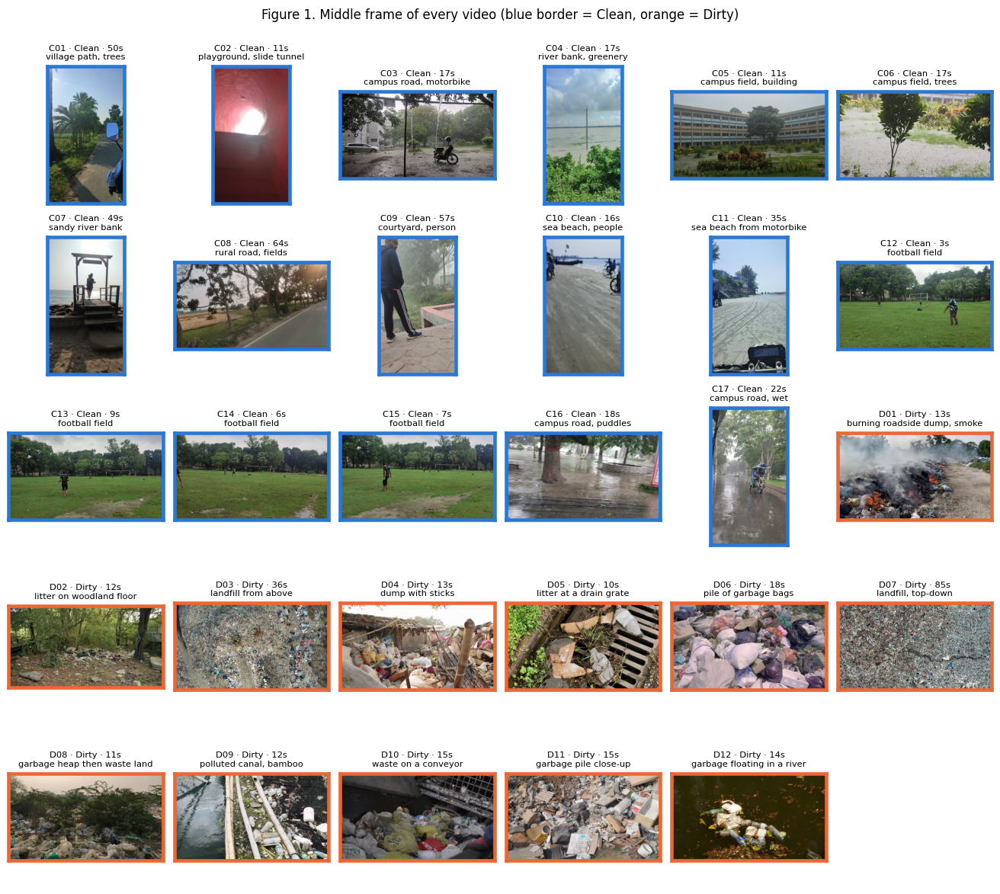

In [7]:
def middle_frame(v, pos=0.5):
    info = json.loads((D.FRAMES / v / "frames.json").read_text())
    f = info["files"][int(pos * (len(info["files"]) - 1))]
    return cv2.cvtColor(cv2.imread(str(D.FRAMES / v / f)), cv2.COLOR_BGR2RGB)

def square(img, s=220):
    h, w = img.shape[:2]; m = min(h, w)
    return cv2.resize(img[(h - m) // 2:(h - m) // 2 + m, (w - m) // 2:(w - m) // 2 + m], (s, s))

fig, axes = plt.subplots(5, 6, figsize=(12, 10.6))
for ax, (_, r) in zip(axes.flat, VIDEOS.iterrows()):
    ax.imshow(middle_frame(r.vid)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(CLASS_COL[r.label]); s.set_linewidth(3)
    ax.set_title(f"{r.vid} · {r['class']} · {r.duration_s:.0f}s\n{r.scene}", fontsize=7.5)
for ax in axes.flat[len(VIDEOS):]:
    ax.axis("off")
fig.suptitle("Figure 1. Middle frame of every video (blue border = Clean, orange = Dirty)", y=1.0)
fig.tight_layout(); savefig(fig, "fig01_dataset_overview")

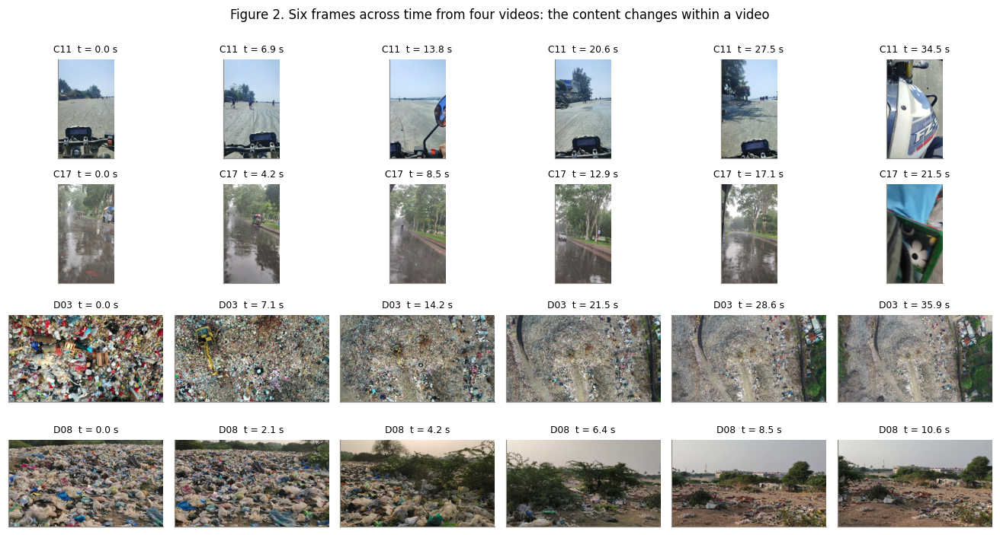

In [8]:
show = ["C11", "C17", "D03", "D08"]
fig, axes = plt.subplots(len(show), 6, figsize=(12, 6.4))
for i, v in enumerate(show):
    frames, times = D.load_frames(v)
    for j, k in enumerate(np.linspace(0, len(frames) - 1, 6).astype(int)):
        ax = axes[i, j]; ax.imshow(frames[k]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{v}  t = {times[k]:.1f} s", fontsize=8)
fig.suptitle("Figure 2. Six frames across time from four videos: the content changes within a video", y=1.0)
fig.tight_layout(); savefig(fig, "fig02_temporal_strips")

### 1.1 How the two classes were captured (shortcut check)

The clean clips were filmed with a phone. The dirty clips are stock footage (Pexels / Vecteezy) from many cameras, often
4K and always landscape. A classifier could separate the classes from capture properties alone, without looking at garbage.
Figure 3 and the table below measure this: a depth-2 decision tree on capture metadata only, evaluated with the same
grouped folds as §5.

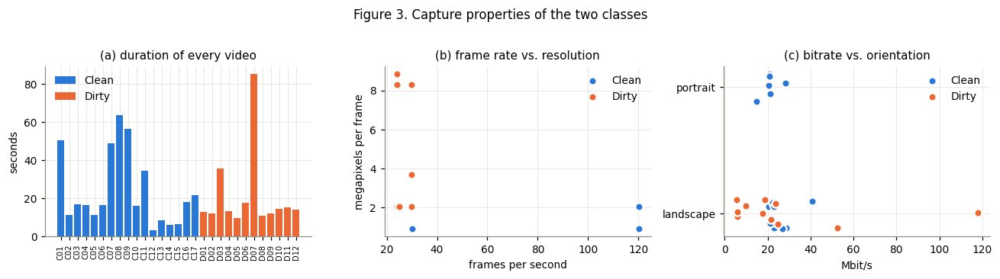

In [9]:
VIDEOS["megapixels"] = VIDEOS.width * VIDEOS.height / 1e6
VIDEOS["bitrate_Mbps"] = VIDEOS.size_MB * 8 / VIDEOS.duration_s
VIDEOS["portrait"] = (VIDEOS.orientation == "portrait").astype(int)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for lab in (0, 1):
    d = VIDEOS[VIDEOS.label == lab]
    axes[0].bar(d.vid, d.duration_s, color=CLASS_COL[lab], label=D.CLASSES[lab])
    axes[1].scatter(d.fps, d.megapixels, s=45, color=CLASS_COL[lab], edgecolor="white", linewidth=1.5, label=D.CLASSES[lab])
    axes[2].scatter(d.bitrate_Mbps, d.portrait + np.random.default_rng(lab).uniform(-0.12, 0.12, len(d)), s=45,
                    color=CLASS_COL[lab], edgecolor="white", linewidth=1.5, label=D.CLASSES[lab])
axes[0].set(title="(a) duration of every video", ylabel="seconds"); axes[0].tick_params(axis="x", rotation=90, labelsize=6.5)
axes[1].set(title="(b) frame rate vs. resolution", xlabel="frames per second", ylabel="megapixels per frame")
axes[2].set(title="(c) bitrate vs. orientation", xlabel="Mbit/s", yticks=[0, 1], yticklabels=["landscape", "portrait"])
for a in axes: a.legend()
fig.suptitle("Figure 3. Capture properties of the two classes", y=1.02)
fig.tight_layout(); savefig(fig, "fig03_capture_properties")

### 1.2 Grouped train / validation / test split

Clips filmed on the same outing look alike, so whole groups go to one side of every split. The held-out sets take only
groups of at most two clips (the four football-field clips of 26 May 2025 always stay in training). Among the candidate
seeds 0--19 the split whose **test set covers the most different lighting and capture conditions** is used; ties go to the
lowest seed. A grouped, class-stratified 5-fold split of all 29 videos is used in §5, §6 and §11 so that every video is
also predicted once by a model that never saw it.

In [10]:
score = []
for s in range(20):
    sp = D.grouped_split(VIDEOS, s); t = VIDEOS[sp == "test"]
    score.append((t.lighting.nunique() + t.capture.nunique(), -s))
SPLIT_SEED = -max(score)[1]
VIDEOS["split"] = D.grouped_split(VIDEOS, SPLIT_SEED)
VIDEOS["fold"] = D.grouped_folds(VIDEOS, k=5, seed=0)
SPLIT = {k: list(VIDEOS.vid[VIDEOS.split == k]) for k in ["train", "val", "test"]}

def cv_split(k, K=5):
    f = dict(zip(VIDEOS.vid, VIDEOS.fold))
    return {"test": [v for v in VIDEOS.vid if f[v] == k], "val": [v for v in VIDEOS.vid if f[v] == (k + 1) % K],
            "train": [v for v in VIDEOS.vid if f[v] not in (k, (k + 1) % K)]}

print("split seed", SPLIT_SEED)
tab = VIDEOS.pivot_table(index="split", columns="class", values="vid", aggfunc="count").loc[["train", "val", "test"]]
tab["seconds"] = VIDEOS.groupby("split").duration_s.sum().round(0)
display(tab)
for k in SPLIT:
    print(f"{k:5s}", ", ".join(f"{v}({VIDEOS.set_index('vid').loc[v, 'lighting']})" for v in SPLIT[k]))
display(VIDEOS.groupby("fold").apply(lambda d: ", ".join(d.vid)).rename("videos per fold").to_frame())
cols = ["vid", "file", "class", "label", "group", "split", "fold", "scene", "lighting", "capture", "source", "duration_s",
        "fps", "width", "height", "orientation", "md5"]
save(VIDEOS[cols].round(3), "dataset"); VIDEOS[cols].round(3).to_csv(ROOT / "annotations" / "dataset.csv", index=False)

split seed 2


class,Clean,Dirty,seconds
split,,,
train,10,7,342.0
val,3,2,129.0
test,4,3,189.0


train C01(sunny), C02(sunny), C03(overcast), C05(sunny), C06(hazy sun), C12(overcast), C13(overcast), C14(overcast), C15(overcast), C16(rain), D01(daylight), D03(daylight), D04(bright), D06(daylight), D07(daylight), D10(indoor), D12(daylight)
val   C09(fog), C10(sunny), C11(sunny), D05(daylight), D09(daylight)
test  C04(cloudy), C07(backlit sun), C08(low evening sun), C17(rain), D02(daylight), D08(hazy), D11(daylight)


,videos per fold
fold,
0,"C01, C02, C09, C17, D04, D08"
1,"C04, C07, C08, D02, D09, D12"
2,"C03, C05, C06, D01, D06"
3,"C10, C11, C16, D05, D07"
4,"C12, C13, C14, C15, D03, D10, D11"


In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import PredefinedSplit, cross_val_predict
ps = PredefinedSplit(VIDEOS.fold.values)
rows = []
for name, feats in [("orientation", ["portrait"]), ("resolution", ["megapixels"]), ("frame rate", ["fps"]),
                    ("bitrate", ["bitrate_Mbps"]), ("all four", ["portrait", "megapixels", "fps", "bitrate_Mbps"])]:
    pred = cross_val_predict(DecisionTreeClassifier(max_depth=2, random_state=0), VIDEOS[feats], VIDEOS.label, cv=ps)
    rows.append({"metadata used": name, "grouped 5-fold video accuracy": (pred == VIDEOS.label).mean()})
display(save(pd.DataFrame(rows).round(3), "shortcut_metadata"))

,metadata used,grouped 5-fold video accuracy
0,orientation,0.690
1,resolution,0.724
2,frame rate,0.897
3,bitrate,0.724
4,all four,0.862


**Observations (dataset).** The folder holds 30 files, but `4445847-uhd_3840_2160_30fps(1).mp4` is a byte-identical copy
(same MD5) and is skipped, which leaves **29 videos: 17 Clean (408 s, 11 outings) and 12 Dirty (253 s, 12 sources)**. The two
classes were captured very differently (Figure 3). The clean clips come from one phone (portrait or landscape, 30 or 120 fps,
at most 1080p). The dirty clips are landscape stock footage at 24--30 fps, often 4K. A depth-2 tree on **frame rate alone
indexes 90 % of the videos correctly** without looking at a single pixel (orientation alone 69 %, all four properties 86 %).
The pipeline removes these cues from the model input: every video is sampled on the same time grid, and every frame is
resized and centre-cropped to the same 224 x 224 square. Colour grading and compression style remain, however, which is
why §9 tests the models on phone photographs of real garbage.

The selected split (seed 2) tests on C04 (cloudy river bank), C07 (back-lit sandy bank), C08 (low evening sun, filmed from
a vehicle), C17 (rain), D02 (litter on a woodland floor), D08 (drone over a garbage heap that ends over waste land) and D11
(garbage pile close-up). Validation uses C09 (fog), C10/C11 (beach outing) and D05, D09.

## 2. Video preprocessing

1. **Fixed sampling rate.** Frames are taken on a fixed time grid (default 2 fps = every 0.5 s; §6 varies it from 0.5 to
   8 fps). A fixed time grid makes 30-fps, 120-fps and 24-fps videos comparable.
2. **Resize and normalise.** Short side to 256 px, centre crop 224 x 224, pixel values scaled to [0, 1] and normalised with
   the ImageNet mean and standard deviation. The square centre crop also removes the portrait / landscape difference of
   §1.1 from the model input.
3. **Pretrained CNN features.** An ImageNet-pretrained ResNet-50 (torchvision `IMAGENET1K_V2`, frozen) turns every frame
   into the 2048-d vector after global average pooling. Features of the horizontally flipped frame are stored as well and
   used as training augmentation.
4. **Sequences.** A video becomes a sequence of feature vectors, one per sampled frame, and is cut into clips of `T`
   frames (default T = 16, i.e. 8 s at 2 fps, 50 % overlap) for the recurrent models.

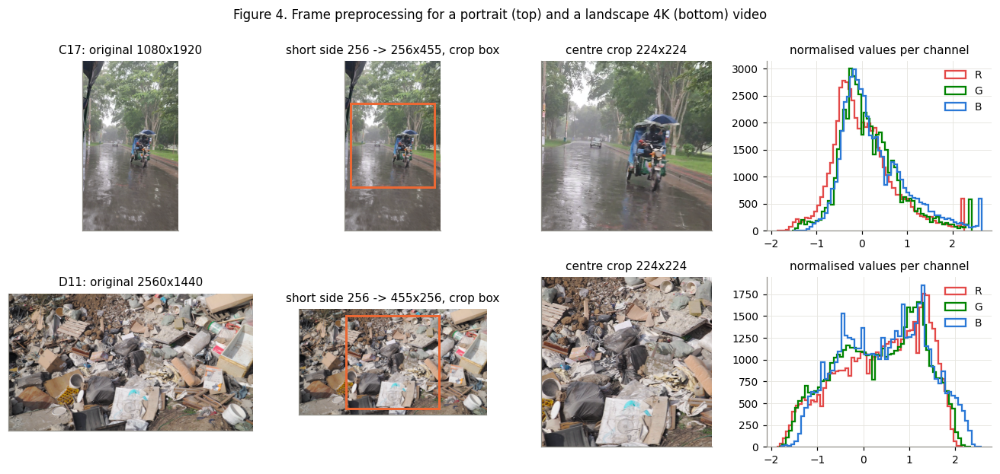

In [12]:
def read_full_frame(file, t):
    c = cv2.VideoCapture(str(D.DATA / file)); c.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    ok, f = c.read(); c.release()
    return cv2.cvtColor(f, cv2.COLOR_BGR2RGB)

ex = [VIDEOS.set_index("vid").loc[v] for v in ["C17", "D11"]]
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1.3, 1, 1, 1.2]})
for i, r in enumerate(ex):
    full = read_full_frame(r.file, r.duration_s / 2)
    small = D.resize_short(full, 256); h, w = small.shape[:2]
    y0, x0 = (h - 224) // 2, (w - 224) // 2
    x = D.preprocess([full])[0].numpy()
    axes[i, 0].imshow(full); axes[i, 0].set_title(f"{r.name}: original {full.shape[1]}x{full.shape[0]}")
    axes[i, 1].imshow(small); axes[i, 1].add_patch(plt.Rectangle((x0, y0), 224, 224, fill=False, ec="#eb6834", lw=2))
    axes[i, 1].set_title(f"short side 256 -> {w}x{h}, crop box")
    axes[i, 2].imshow(small[y0:y0 + 224, x0:x0 + 224]); axes[i, 2].set_title("centre crop 224x224")
    for c, name in enumerate("RGB"):
        axes[i, 3].hist(x[c].ravel(), bins=60, histtype="step", lw=1.5, color=["#e34948", "#008300", "#2a78d6"][c], label=name)
    axes[i, 3].set_title("normalised values per channel"); axes[i, 3].legend()
    for a in axes[i, :3]: a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Figure 4. Frame preprocessing for a portrait (top) and a landscape 4K (bottom) video", y=1.0)
fig.tight_layout(); savefig(fig, "fig04_preprocessing")

In [13]:
t0 = time.time()
for v in VIDEOS.vid:
    D.video_features(v)
print(f"features ready ({time.time() - t0:.1f} s; cached in outputs/features/resnet50)")

# feature-extraction speed of the backbone
net = D.backbone(); xb = torch.randn(64, 3, 224, 224, device="cuda")
with torch.no_grad(), torch.autocast("cuda", torch.bfloat16):
    for _ in range(3): net(xb)
    torch.cuda.synchronize(); t = time.perf_counter()
    for _ in range(10): net(xb)
    torch.cuda.synchronize()
CNN_MS_PER_FRAME = (time.perf_counter() - t) / 640 * 1000
print(f"ResNet-50 feature extraction: {CNN_MS_PER_FRAME:.2f} ms per frame (batch 64, bf16), "
      f"{sum(p.numel() for p in net.parameters()) / 1e6:.1f} M frozen parameters")

features ready (0.0 s; cached in outputs/features/resnet50)


ResNet-50 feature extraction: 0.36 ms per frame (batch 64, bf16), 23.5 M frozen parameters


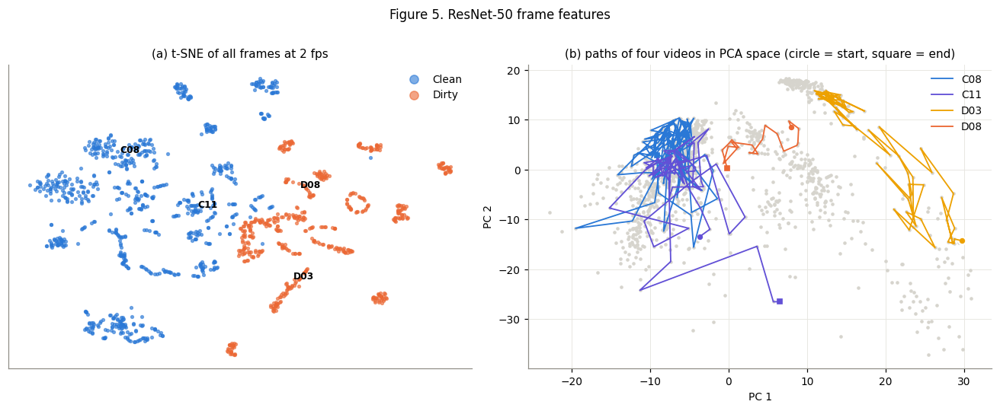

In [14]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
F2, owner = [], []
for v in VIDEOS.vid:
    f = D.video_features(v)["f"][::4].astype(np.float32)      # 2 fps
    F2.append(f); owner += [v] * len(f)
F2, owner = np.concatenate(F2), np.array(owner)
lab = np.array([LABELS[v] for v in owner])
Z = PCA(2, random_state=0).fit_transform((F2 - F2.mean(0)) / (F2.std(0) + 1e-3))
E2 = TSNE(2, perplexity=30, random_state=0, init="pca").fit_transform((F2 - F2.mean(0)) / (F2.std(0) + 1e-3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for l in (0, 1):
    axes[0].scatter(E2[lab == l, 0], E2[lab == l, 1], s=6, color=CLASS_COL[l], alpha=0.6, label=D.CLASSES[l])
for v in ["C08", "C11", "D03", "D08"]:
    m = owner == v
    axes[0].annotate(v, E2[m].mean(0), fontsize=8, weight="bold")
axes[0].set(title="(a) t-SNE of all frames at 2 fps", xticks=[], yticks=[]); axes[0].legend(markerscale=3)
axes[1].scatter(Z[:, 0], Z[:, 1], s=4, color="#d6d4cd")
for v, c in zip(["C08", "C11", "D03", "D08"], ["#2a78d6", "#6250d6", "#eda100", "#eb6834"]):
    m = owner == v
    axes[1].plot(Z[m, 0], Z[m, 1], "-", color=c, lw=1.2, label=v)
    axes[1].scatter(Z[m, 0][0], Z[m, 1][0], marker="o", s=40, color=c, edgecolor="white", linewidth=1.5)
    axes[1].scatter(Z[m, 0][-1], Z[m, 1][-1], marker="s", s=40, color=c, edgecolor="white", linewidth=1.5)
axes[1].set(title="(b) paths of four videos in PCA space (circle = start, square = end)", xlabel="PC 1", ylabel="PC 2")
axes[1].legend()
fig.suptitle("Figure 5. ResNet-50 frame features", y=1.01)
fig.tight_layout(); savefig(fig, "fig05_feature_space")

### 2.1 Low-level frame statistics

Brightness, contrast, saturation, the fraction of green (vegetation) and sky pixels, edge density and motion (mean absolute
difference between consecutive sampled frames) are measured on every frame at 2 fps. They describe the recording
conditions used in §9 and give a non-deep baseline: logistic regression on the mean statistics of a 16-frame clip, with
the same grouped folds.

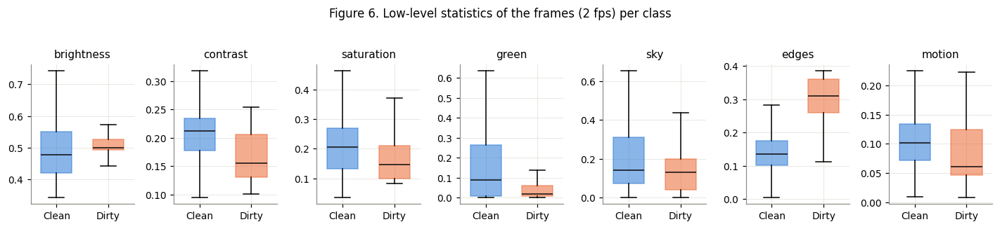

low-level colour / texture / motion baseline (grouped 5-fold): {'clip accuracy': np.float64(0.922), 'video accuracy': np.float64(0.897)}


In [15]:
fs_path = RES / "frame_stats.csv"
if fs_path.exists():
    FS = pd.read_csv(fs_path)
else:
    parts = []
    for v in VIDEOS.vid:
        frames, times = D.load_frames(v)
        s = D.frame_stats(frames[::4]); s["vid"] = v; s["t"] = times[::4]; parts.append(s)
    FS = save(pd.concat(parts, ignore_index=True), "frame_stats")
STATS = ["brightness", "contrast", "saturation", "green", "sky", "edges", "motion"]
VSTATS = FS.groupby("vid")[STATS].mean()
VIDEOS = VIDEOS.drop(columns=[c for c in STATS if c in VIDEOS], errors="ignore").merge(VSTATS, left_on="vid", right_index=True)
fig, axes = plt.subplots(1, len(STATS), figsize=(13, 2.8))
for a, s in zip(axes, STATS):
    data = [FS[FS.vid.map(LABELS) == l][s].dropna() for l in (0, 1)]
    bp = a.boxplot(data, widths=0.6, patch_artist=True, showfliers=False)
    for patch, c in zip(bp["boxes"], CLASS_COL): patch.set(facecolor=c, alpha=0.55, edgecolor=c)
    for med in bp["medians"]: med.set(color="#0b0b0b")
    a.set_xticks([1, 2], D.CLASSES); a.set_title(s)
fig.suptitle("Figure 6. Low-level statistics of the frames (2 fps) per class", y=1.04)
fig.tight_layout(); savefig(fig, "fig06_frame_stats")

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
rows = []
for v in VIDEOS.vid:
    s = FS[FS.vid == v].reset_index(drop=True)
    for k, start in enumerate(range(0, max(1, len(s) - 15), 8)):
        rows.append({"vid": v, **s.iloc[start:start + 16][STATS].mean().fillna(0).to_dict()})
LL = pd.DataFrame(rows); LL["label"] = LL.vid.map(LABELS); LL["fold"] = LL.vid.map(dict(zip(VIDEOS.vid, VIDEOS.fold)))
LL["p"] = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), LL[STATS], LL.label,
                            cv=PredefinedSplit(LL.fold.values), method="predict_proba")[:, 1]
vv = LL.groupby("vid").agg(p=("p", "mean"), label=("label", "first"))
LOWLEVEL = {"clip accuracy": ((LL.p >= 0.5) == LL.label).mean(), "video accuracy": ((vv.p >= 0.5) == vv.label).mean()}
print("low-level colour / texture / motion baseline (grouped 5-fold):", {k: round(v, 3) for k, v in LOWLEVEL.items()})

**Observations (preprocessing and features).** Figure 4 shows how the centre crop turns both a portrait phone frame and a
landscape 4K stock frame into the same 224 x 224 input; after normalisation the three channels are centred near zero. The
frozen ResNet-50 needs 0.36 ms per frame, so one minute of video at 2 fps (120 frames) costs about 0.04 s of GPU time.

In the t-SNE map (Figure 5a) clean and dirty frames fall into separate regions, and most videos form their own tight
clusters: consecutive frames of a video are very similar. Figure 5b follows four videos through feature space. The clean
clips C08 and C11 and the dirty landfill D03 stay in their own regions, whereas **D08 starts on the garbage heap and drifts
towards the clean region** as the drone flies on over waste land. This is the one video whose content really changes over
time, and it becomes the main error case below.

The low-level statistics (Figure 6) already differ between the classes: clean videos contain more green vegetation and sky,
more contrast, more saturated colour and more camera motion, while dirty frames have about twice the edge density
(cluttered texture). Logistic regression on these seven numbers alone reaches **0.922 clip
and 0.897 video accuracy** under grouped 5-fold CV. The task is therefore easy for any deep feature, and differences
between the recurrent models will be small on whole-video labels.

## 3. Video indexing models

All three models read the same standardised 2048-d frame features $x_1,\dots,x_T$ (with dropout 0.5 on the input),
run **one unidirectional recurrent layer with 128 hidden units**, and classify the **last hidden state** $h_T$ with a
linear layer into Clean / Dirty. Only the recurrent cell differs:

* **RNN** --- $h_t = \tanh(W x_t + U h_{t-1} + b)$. One weight block; everything the model knows about the past must
  survive repeated multiplication by $U$ and squashing by tanh.
* **LSTM** --- input, forget and output gates $i_t, f_t, o_t = \sigma(\cdot)$ and a candidate $g_t = \tanh(\cdot)$ control a
  separate **cell state** $c_t = f_t \odot c_{t-1} + i_t \odot g_t$, $h_t = o_t \odot \tanh(c_t)$. The additive update of
  $c_t$ lets information pass many steps without being squashed. Four weight blocks.
* **GRU** --- update gate $z_t$ and reset gate $r_t$; $\tilde h_t = \tanh(W x_t + U(r_t \odot h_{t-1}))$ and
  $h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde h_t$. Gated and additive like the LSTM but without a separate cell
  state. Three weight blocks.

The video's **index** is the label with the higher mean P(dirty) over all its clips (threshold 0.5).

Baselines (same features, same training recipe, no recurrence):
* **single frame** (`MLP-frame`) --- a 2048-128-2 MLP trained on single frames; a clip is scored by averaging its
  per-frame logits;
* **mean pooling** (`MLP-mean`) --- the same MLP applied to the average feature of the clip (temporal pooling that
  ignores frame order).

In [16]:
%%writefile vi_models.py
"""Recurrent video-indexing heads (RNN / LSTM / GRU) and the two non-recurrent baselines, all on the same
2048-d ResNet-50 frame features."""
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

CELLS = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
GATES = {"RNN": 1, "GRU": 3, "LSTM": 4}          # weight blocks per recurrent layer


class Standardise(nn.Module):
    """Fixed per-dimension feature standardisation, statistics from the training videos only."""
    def __init__(self, dim):
        super().__init__()
        self.register_buffer("mu", torch.zeros(dim)); self.register_buffer("sd", torch.ones(dim))

    def fit(self, x):
        self.mu.copy_(x.mean(0)); self.sd.copy_(x.std(0).clamp_min(1e-3))

    def forward(self, x):
        return (x - self.mu) / self.sd


class RecurrentIndexer(nn.Module):
    """frame features -> dropout -> unidirectional recurrent layer(s) -> last hidden state -> Clean / Dirty logits.
    The three variants differ only in the recurrent cell. readout='mean' (ablation) averages the hidden states of all
    time steps instead of using the last one."""
    def __init__(self, cell="GRU", in_dim=2048, hidden=128, layers=1, dropout=0.3, readout="last"):
        super().__init__()
        self.cell, self.readout = cell, readout
        self.norm = Standardise(in_dim)
        self.drop = nn.Dropout(dropout)
        kw = {"nonlinearity": "tanh"} if cell == "RNN" else {}
        self.rnn = CELLS[cell](in_dim, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0.0, **kw)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 2))

    def forward(self, x, lengths):
        x = self.drop(self.norm(x))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        if self.readout == "mean":
            out, L = pad_packed_sequence(out, batch_first=True)
            return self.head(out.sum(1) / L.to(out.device)[:, None])
        h = h[0] if self.cell == "LSTM" else h
        return self.head(h[-1])

    def step_logits(self, x):
        """Logits after every time step (for equal-length sequences): what the model would answer having seen
        only the first t frames."""
        out, _ = self.rnn(self.drop(self.norm(x)))
        if self.readout == "mean":
            out = out.cumsum(1) / torch.arange(1, x.shape[1] + 1, device=x.device)[None, :, None]
        return self.head(out)

    def recurrent_states(self, x):
        out, _ = self.rnn(self.norm(x))
        return out


class FrameMLP(nn.Module):
    """Baseline without recurrence. mode='frame': classify each frame on its own and average the logits
    (single-frame classifier); mode='mean': average the frame features first (order-free temporal pooling)."""
    def __init__(self, mode="frame", in_dim=2048, hidden=128, dropout=0.3):
        super().__init__()
        self.cell, self.mode = f"MLP-{mode}", mode
        self.norm = Standardise(in_dim)
        self.net = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 2))

    def forward(self, x, lengths):
        mask = (torch.arange(x.shape[1], device=x.device)[None] < lengths.to(x.device)[:, None]).float()[..., None]
        x = self.norm(x)
        if self.mode == "mean":
            return self.net((x * mask).sum(1) / mask.sum(1))
        return (self.net(x) * mask).sum(1) / mask.sum(1)

    def step_logits(self, x):
        x = self.norm(x)
        t = torch.arange(1, x.shape[1] + 1, device=x.device)[None, :, None]
        if self.mode == "mean":
            return self.net(x.cumsum(1) / t)
        return self.net(x).cumsum(1) / t


def build(name, **kw):
    if name in CELLS:
        return RecurrentIndexer(name, **kw)
    if name in ("MLP-frame", "MLP-mean"):
        kw.pop("layers", None)
        return FrameMLP(name.split("-")[1], **kw)
    raise ValueError(name)


def n_params(model, trainable=True):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable)


def recurrent_macs(cell, in_dim=2048, hidden=128, layers=1, T=16):
    """Multiply-accumulates of the recurrent part for one sequence of T frames:
    every step computes GATES[cell] blocks of (input x W + h x U)."""
    g = GATES[cell]
    per_step = g * hidden * (in_dim + hidden) + g * hidden * (hidden + hidden) * (layers - 1)
    return per_step * T

Overwriting vi_models.py


In [17]:
import vi_models as M
importlib.reload(M)
rows = []
for name in ALL:
    m = M.build(name)
    rows.append({"model": name, "trainable parameters": M.n_params(m),
                 "recurrent parameters": sum(p.numel() for p in m.rnn.parameters()) if name in CELLS else 0,
                 "weight blocks per step": M.GATES.get(name, "-"),
                 "MACs per 16-frame clip (recurrent part)": M.recurrent_macs(name, T=16) if name in CELLS else 0})
PARAMS = save(pd.DataFrame(rows), "model_parameters")
display(PARAMS)
print(M.build("LSTM"))

,model,trainable parameters,recurrent parameters,weight blocks per step,MACs per 16-frame clip (recurrent part)
0,RNN,279042,278784,1,4456448
1,LSTM,1115394,1115136,4,17825792
2,GRU,836610,836352,3,13369344
3,MLP-frame,262530,0,-,0
4,MLP-mean,262530,0,-,0


RecurrentIndexer(
  (norm): Standardise()
  (drop): Dropout(p=0.3, inplace=False)
  (rnn): LSTM(2048, 128, batch_first=True)
  (head): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=128, out_features=2, bias=True)
  )
)


## 4. Training and evaluation on the held-out test split

**Identical recipe for every model** (`vi_train.py`): AdamW (lr 3e-4, weight decay 0.01), cosine schedule, 30 epochs,
batch 32, cross-entropy with class weights and label smoothing 0.05, gradient clipping at 1.0. Each epoch draws 16 random
clips from every training video (so long videos do not dominate), with a random phase of the sampling grid and a 50 %
chance of the flipped-frame features. The checkpoint with the lowest validation loss is kept; each model is trained with
**5 seeds**. Validation and test use all clips of a video (T = 16 frames at 2 fps, 50 % overlap); clip results and
video results (mean over the clips of the video) are both reported.

In [18]:
%%writefile vi_train.py
"""Clip sampling, the training recipe shared by every model, and clip / video prediction. Runs are resumable:
a finished run is skipped and its saved result returned."""
import json, math, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import vi_data as D
import vi_models as M

RUNS = D.OUT / "runs"
DEFAULT = dict(hidden=128, layers=1, dropout=0.5, fps=2.0, T=16, eval_T=None, epochs=30, clips_per_video=16, batch=32, lr=3e-4,
               weight_decay=1e-2, label_smoothing=0.05, flip_p=0.5, seed=0)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


class Store:
    """Frame features of every video on the GPU: f (N, 2048), ff (flipped frames) and the frame times."""
    def __init__(self, vids, kind="none", subdir="resnet50"):
        self.f, self.ff, self.t = {}, {}, {}
        for v in vids:
            d = D.video_features(v, kind, subdir)
            self.f[v] = torch.from_numpy(d["f"].astype(np.float32)).cuda()
            self.ff[v] = torch.from_numpy(d["ff"].astype(np.float32)).cuda() if "ff" in d else self.f[v]
            self.t[v] = d["t"]

    def n(self, v):
        return len(self.f[v])


def step_of(fps):
    s = D.BASE_FPS / fps
    assert abs(s - round(s)) < 1e-6, "fps must divide the base rate"
    return int(round(s))


def eval_clips(n, fps, T, phase=0, stride=None):
    """Frame indices of the evaluation clips of one video: windows of T sampled frames, 50 % overlap,
    the last window aligned with the end; one shorter clip when the video has fewer than T sampled frames."""
    idx = np.arange(phase, n, step_of(fps))
    if len(idx) <= T:
        return [idx]
    stride = stride or max(1, T // 2)
    starts = list(range(0, len(idx) - T + 1, stride))
    if starts[-1] != len(idx) - T:
        starts.append(len(idx) - T)
    return [idx[s:s + T] for s in starts]


def random_clip(n, fps, T, rng):
    step = step_of(fps)
    idx = np.arange(rng.integers(step), n, step)       # random phase of the sampling grid
    if len(idx) <= T:
        return idx
    s = rng.integers(len(idx) - T + 1)
    return idx[s:s + T]


def pad(seqs):
    L = torch.tensor([len(s) for s in seqs])
    x = torch.zeros(len(seqs), int(L.max()), seqs[0].shape[-1], device=seqs[0].device)
    for i, s in enumerate(seqs):
        x[i, :len(s)] = s
    return x, L


def fit_norm(model, store, vids):
    model.norm.fit(torch.cat([store.f[v] for v in vids]))


def train_model(model, sample_batch, val_loss, epochs, steps_per_epoch, cfg, class_weight=None):
    """Generic loop: AdamW + cosine schedule, best epoch chosen by validation loss."""
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    total = epochs * steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * s / total)))
    best, best_state, hist = (float("inf"), -1), None, []
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        losses, correct, n = [], 0, 0
        for _ in range(steps_per_epoch):
            x, L, y = sample_batch()
            logits = model(x, L)
            loss = F.cross_entropy(logits, y, weight=class_weight, label_smoothing=cfg["label_smoothing"])
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            losses.append(loss.item()); correct += (logits.argmax(-1) == y).sum().item(); n += len(y)
        vl, vacc = val_loss(model)
        hist.append({"epoch": ep + 1, "train_loss": float(np.mean(losses)), "train_acc": correct / n, "val_loss": vl, "val_acc": vacc})
        if vl < best[0] - 1e-6:
            best = (vl, ep + 1)
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return hist, best[1], time.time() - t0


@torch.no_grad()
def predict_clips(model, store, vids, fps, T, phase=0, transform=None, bs=256):
    """P(dirty) of every evaluation clip. transform(x) may reorder / alter the frames of a clip."""
    model.eval()
    rows, seqs = [], []
    for v in vids:
        for k, idx in enumerate(eval_clips(store.n(v), fps, T, phase)):
            x = store.f[v][torch.as_tensor(idx, device="cuda")]
            seqs.append(transform(x) if transform else x)
            rows.append({"vid": v, "clip": k, "t_start": float(store.t[v][idx[0]]), "t_end": float(store.t[v][idx[-1]]), "n": len(idx)})
    p = []
    for i in range(0, len(seqs), bs):
        x, L = pad(seqs[i:i + bs])
        p.append(model(x, L).float().softmax(-1)[:, 1].cpu())
    df = pd.DataFrame(rows)
    df["p_dirty"] = torch.cat(p).numpy() if p else []
    return df


def video_scores(clips):
    """Video index score = mean clip P(dirty); also the fraction of clips called dirty."""
    g = clips.groupby("vid", sort=False)
    return pd.DataFrame({"p_dirty": g.p_dirty.mean(), "frac_dirty_clips": g.p_dirty.apply(lambda p: (p >= 0.5).mean()),
                         "n_clips": g.size()}).reset_index()


def clip_nll(model, store, vids, labels, fps, T):
    c = predict_clips(model, store, vids, fps, T)
    y = c.vid.map(labels).values
    p = np.clip(c.p_dirty.values, 1e-6, 1 - 1e-6)
    c["nll"] = -(y * np.log(p) + (1 - y) * np.log(1 - p))
    c["ok"] = (p >= 0.5) == y
    per_vid = c.groupby("vid")[["nll", "ok"]].mean()          # every video counts equally
    return float(per_vid.nll.mean()), float(per_vid.ok.mean())


def train_run(name, cell, split, labels, store, cfg=None, save_weights=False, extra_eval=None):
    """split: {'train': [...], 'val': [...], 'test': [...]} video ids; labels: {vid: 0/1}.
    extra_eval: {tag: (Store, vids)} evaluated with the best checkpoint (e.g. perturbed copies of the test videos)."""
    cfg = {**DEFAULT, **(cfg or {})}
    eT = cfg["eval_T"] or cfg["T"]          # clip length for validation / test (the frame baseline trains on T=1)
    out = RUNS / name
    if (out / "result.json").exists():
        return load_result(name)
    set_seed(cfg["seed"])
    model = M.build(cell, hidden=cfg["hidden"], layers=cfg["layers"], dropout=cfg["dropout"], **readout_kw(cell, cfg)).cuda()
    fit_norm(model, store, split["train"])
    tr = split["train"]
    ytr = np.array([labels[v] for v in tr])
    w = torch.tensor([len(ytr) / (2 * (ytr == c).sum()) for c in (0, 1)], dtype=torch.float32).cuda()
    rng = np.random.default_rng(cfg["seed"])
    order = []

    def sample_batch():
        nonlocal order
        if len(order) < cfg["batch"]:                       # every training video contributes the same number of clips
            order += list(rng.permutation(np.repeat(np.arange(len(tr)), cfg["clips_per_video"])))
        pick, order = order[:cfg["batch"]], order[cfg["batch"]:]
        seqs = []
        for i in pick:
            v = tr[i]
            idx = torch.as_tensor(random_clip(store.n(v), cfg["fps"], cfg["T"], rng), device="cuda")
            src = store.ff[v] if rng.random() < cfg["flip_p"] else store.f[v]
            seqs.append(src[idx])
        x, L = pad(seqs)
        return x, L, torch.as_tensor(ytr[pick], device="cuda")

    steps = max(1, len(tr) * cfg["clips_per_video"] // cfg["batch"])
    hist, best_ep, t_train = train_model(model, sample_batch, lambda m: clip_nll(m, store, split["val"], labels, cfg["fps"], eT),
                                         cfg["epochs"], steps, cfg, w)
    out.mkdir(parents=True, exist_ok=True)
    clips = predict_clips(model, store, split["test"], cfg["fps"], eT)
    clips["label"] = clips.vid.map(labels)
    clips.to_csv(out / "test_clips.csv", index=False)
    vids = video_scores(clips); vids["label"] = vids.vid.map(labels)
    vids.to_csv(out / "test_videos.csv", index=False)
    for tag, (st, vv) in (extra_eval or {}).items():
        c = predict_clips(model, st, vv, cfg["fps"], eT); c["label"] = c.vid.map(labels)
        c.to_csv(out / f"extra_{tag}.csv", index=False)
    pd.DataFrame(hist).to_csv(out / "history.csv", index=False)
    if save_weights:
        torch.save({"cell": cell, "cfg": cfg, "state": model.state_dict()}, out / "best.pt")
    res = {"name": name, "cell": cell, "cfg": cfg, "best_epoch": best_ep, "train_time_s": t_train,
           "params": M.n_params(model), "split": split}
    (out / "result.json").write_text(json.dumps(res, indent=1))
    return load_result(name)


def readout_kw(cell, cfg):
    """Only recurrent cells take the readout option ('last' hidden state by default, 'mean' in the ablation)."""
    return {"readout": cfg["readout"]} if cell in M.CELLS and cfg.get("readout") else {}


def load_result(name):
    out = RUNS / name
    res = json.loads((out / "result.json").read_text())
    res["clips"] = pd.read_csv(out / "test_clips.csv")
    res["videos"] = pd.read_csv(out / "test_videos.csv")
    res["history"] = pd.read_csv(out / "history.csv")
    res["extra"] = {p.stem[6:]: pd.read_csv(p) for p in out.glob("extra_*.csv")}
    return res


def load_model(name):
    ck = torch.load(RUNS / name / "best.pt", map_location="cuda")
    c = ck["cfg"]
    m = M.build(ck["cell"], hidden=c["hidden"], layers=c["layers"], dropout=c["dropout"], **readout_kw(ck["cell"], c)).cuda()
    m.load_state_dict(ck["state"]); m.eval()
    return m, c

Overwriting vi_train.py


In [19]:
%%writefile vi_eval.py
"""Metrics, speed benchmark, temporal-order tests, timestamp localisation on spliced videos and the long-range
memory probe -- identical for every model."""
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import vi_train as TR


def metrics(y, p, thr=0.5):
    """Dirty = positive class."""
    from sklearn.metrics import roc_auc_score
    y, yhat = np.asarray(y).astype(int), (np.asarray(p) >= thr).astype(int)
    tp, tn = int(((yhat == 1) & (y == 1)).sum()), int(((yhat == 0) & (y == 0)).sum())
    fp, fn = int(((yhat == 1) & (y == 0)).sum()), int(((yhat == 0) & (y == 1)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {"accuracy": (tp + tn) / len(y), "precision": prec, "recall": rec,
            "F1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
            "specificity": tn / (tn + fp) if tn + fp else 0.0,
            "AUC": roc_auc_score(y, p) if len(set(y)) == 2 else np.nan, "TP": tp, "TN": tn, "FP": fp, "FN": fn}


# ------------------------------------------------------------------------------------------------ speed
@torch.no_grad()
def latency(model, T=16, device="cuda", batch=1, runs=200, warmup=20, dim=2048):
    """Mean wall-clock time of one forward pass over a batch of T-frame feature sequences (ms)."""
    model = model.to(device).eval()
    x = torch.randn(batch, T, dim, device=device)
    L = torch.full((batch,), T)
    for _ in range(warmup):
        model(x, L)
    if device == "cuda":
        torch.cuda.synchronize()
    ts = []
    for _ in range(runs):
        t = time.perf_counter(); model(x, L)
        if device == "cuda":
            torch.cuda.synchronize()
        ts.append(time.perf_counter() - t)
    model.to("cuda")
    return 1000 * float(np.median(ts))


# ------------------------------------------------------------------------------------------------ temporal tests
def temporal_transform(kind, seed=0):
    """Changes to the frames of a clip that keep its content but destroy (part of) its order."""
    g = torch.Generator().manual_seed(seed)

    def f(x):
        n = len(x)
        if kind == "shuffle":
            return x[torch.randperm(n, generator=g).to(x.device)]
        if kind == "reverse":
            return x.flip(0)
        if kind == "middle_frame":            # one frame repeated: the clip carries no temporal information
            return x[n // 2].expand(n, -1)
        if kind == "drop_half":               # half the frames removed (= halved sampling rate, same span)
            return x[::2] if n > 1 else x
        return x
    return f


def temporal_saliency(model, x):
    """|d logit(dirty) / d frame_t| for every time step of equal-length clips x (B, T, D), averaged over the batch."""
    model.eval()
    x = x.clone().requires_grad_(True)
    with torch.backends.cudnn.flags(enabled=False):         # cuDNN RNN has no backward in eval mode
        L = torch.full((len(x),), x.shape[1])
        z = model(x, L)
        (z[:, 1] - z[:, 0]).sum().backward()
    return x.grad.norm(dim=-1).mean(0).cpu().numpy()


@torch.no_grad()
def prefix_probs(model, x):
    """P(dirty) after each time step for equal-length clips (B, T, D) -> (B, T)."""
    model.eval()
    return model.step_logits(x).softmax(-1)[..., 1].cpu().numpy()


# ------------------------------------------------------------------------------------------------ localisation
def sampled(store, v, fps, phase=0):
    idx = np.arange(phase, store.n(v), TR.step_of(fps))
    return store.f[v][torch.as_tensor(idx, device="cuda")], store.t[v][idx]


def make_composites(store, clean, dirty, n=40, fps=2.0, seed=0, clean_s=(8, 30), dirty_s=(4, 16)):
    """Spliced test streams  clean | dirty | clean (| dirty | clean)  built from held-out videos, with the true
    dirty intervals known. Every piece is a random contiguous part of one video."""
    rng = np.random.default_rng(seed)
    out = []
    for i in range(n):
        n_dirty = 1 if i % 2 == 0 else 2
        pattern = [0] + [1, 0] * n_dirty
        xs, ys, src = [], [], []
        for lab in pattern:
            v = rng.choice(clean if lab == 0 else dirty)
            f, _ = sampled(store, v, fps)
            want = int(rng.uniform(*(clean_s if lab == 0 else dirty_s)) * fps)
            want = min(want, len(f))
            s = rng.integers(len(f) - want + 1)
            xs.append(f[s:s + want]); ys += [lab] * want; src.append((v, want))
        y = np.array(ys)
        out.append({"x": torch.cat(xs), "y": y, "t": np.arange(len(y)) / fps, "sources": src})
    return out


@torch.no_grad()
def timeline(model, x, W, bs=512):
    """P(dirty) at every sampled frame from a window of W frames centred on it (shortened at the ends)."""
    model.eval()
    n = len(x)
    seqs = [x[max(0, t - W // 2): min(n, t - W // 2 + W)] for t in range(n)]
    seqs = [s if len(s) else x[t:t + 1] for t, s in enumerate(seqs)]
    p = []
    for i in range(0, n, bs):
        xb, L = TR.pad(seqs[i:i + bs])
        p.append(model(xb, L).softmax(-1)[:, 1].cpu())
    return torch.cat(p).numpy()


def segments(mask, t, min_len_s=1.0, merge_gap_s=1.0, dt=0.5):
    """Runs of True in a per-frame mask -> list of (start_s, end_s); short gaps merged, short runs dropped."""
    segs, start = [], None
    for i, m in enumerate(list(mask) + [False]):
        if m and start is None:
            start = i
        if not m and start is not None:
            segs.append([t[start], t[i - 1] + dt]); start = None
    merged = []
    for s in segs:
        if merged and s[0] - merged[-1][1] <= merge_gap_s:
            merged[-1][1] = s[1]
        else:
            merged.append(s)
    return [tuple(s) for s in merged if s[1] - s[0] >= min_len_s]


def _iou(a, b):
    inter = max(0.0, min(a[1], b[1]) - max(a[0], b[0]))
    return inter / (max(a[1], b[1]) - min(a[0], b[0]))


def localisation_scores(p, y, t, dt=0.5, thr=0.5):
    """Frame-level metrics plus event-level matching (IoU >= 0.5) and boundary error of matched events."""
    m = metrics(y, p, thr)
    gt = segments(y.astype(bool), t, min_len_s=0, merge_gap_s=0, dt=dt)
    pr = segments(p >= thr, t, dt=dt)
    used, matched, berr = set(), 0, []
    for g in gt:
        best = max(((i, _iou(g, q)) for i, q in enumerate(pr) if i not in used), key=lambda z: z[1], default=(None, 0))
        if best[1] >= 0.5:
            used.add(best[0]); matched += 1
            q = pr[best[0]]; berr += [abs(q[0] - g[0]), abs(q[1] - g[1])]
    ev_p = matched / len(pr) if pr else 0.0
    ev_r = matched / len(gt) if gt else 0.0
    return {"frame_acc": m["accuracy"], "frame_F1": m["F1"], "event_precision": ev_p, "event_recall": ev_r,
            "event_F1": 2 * ev_p * ev_r / (ev_p + ev_r) if ev_p + ev_r else 0.0,
            "boundary_err_s": float(np.mean(berr)) if berr else np.nan,
            "false_segments": len(pr) - matched, "switches": int(np.abs(np.diff((p >= thr).astype(int))).sum())}


# ------------------------------------------------------------------------------------------------ memory probe
class ProbeSampler:
    """'Does this stream contain a dirty moment?' Background = clean clips of 4-16 frames from random clean videos
    spliced together; one k-frame piece is inserted at position `pos`: from a dirty video (label 1) or from yet
    another clean video (label 0), so a splice alone is no evidence. Solving it needs memory of the inserted
    piece until the last frame."""
    def __init__(self, store, clean, dirty, fps=2.0):
        self.f = {v: sampled(store, v, fps)[0] for v in list(clean) + list(dirty)}
        self.clean, self.dirty = list(clean), list(dirty)

    def piece(self, vids, k, rng):
        v = vids[rng.integers(len(vids))]
        f = self.f[v]
        k = min(k, len(f)); s = rng.integers(len(f) - k + 1)
        return f[s:s + k]

    def one(self, L, k, label, pos, rng):
        bg, n = [], 0
        while n < L - k:
            p = self.piece(self.clean, int(rng.integers(4, 17)), rng); bg.append(p); n += len(p)
        bg = torch.cat(bg)[:L - k]
        ins = self.piece(self.dirty if label else self.clean, k, rng)
        if len(ins) < k:
            ins = ins.repeat(k // len(ins) + 1, 1)[:k]
        return torch.cat([bg[:pos], ins, bg[pos:]])

    def batch(self, B, L, k, rng, pos=None):
        y = rng.integers(0, 2, B)
        ps = rng.integers(0, L - k + 1, B) if pos is None else np.full(B, pos)
        x = torch.stack([self.one(L, k, int(yy), int(p), rng) for yy, p in zip(y, ps)])
        return x, torch.full((B,), L), torch.as_tensor(y, device="cuda")


def probe_run(cell, train_s, val_s, test_s, L, k=2, seed=0, epochs=40, steps=25, B=64, hidden=128, n_test=256, cfg=None,
              readout=None):
    """Trains one cell on the memory probe and returns accuracy as a function of the insert position."""
    import vi_models as M
    cfg = {**TR.DEFAULT, "label_smoothing": 0.0, **(cfg or {})}
    TR.set_seed(seed)
    model = M.build(cell, hidden=hidden, dropout=cfg["dropout"], **({"readout": readout} if readout else {})).cuda()
    model.norm.fit(torch.cat(list(train_s.f.values())))
    rng = np.random.default_rng(seed)
    vrng = np.random.default_rng(10_000 + seed)
    val = [val_s.batch(B, L, k, vrng) for _ in range(4)]

    def val_loss(m):
        m.eval()
        with torch.no_grad():
            ls = [(F.cross_entropy(m(x, l), y).item(), (m(x, l).argmax(-1) == y).float().mean().item()) for x, l, y in val]
        return float(np.mean([a for a, _ in ls])), float(np.mean([b for _, b in ls]))
    hist, best_ep, t = TR.train_model(model, lambda: train_s.batch(B, L, k, rng), val_loss, epochs, steps, cfg)
    model.eval()
    rows, trng = [], np.random.default_rng(20_000 + seed)
    for pos in np.unique(np.linspace(0, L - k, min(9, L - k + 1)).astype(int)):
        with torch.no_grad():
            x, l, y = test_s.batch(n_test, L, k, trng, pos=int(pos))
            pred = model(x, l).argmax(-1)
        yy = y.cpu().numpy(); pp = pred.cpu().numpy()
        rows.append({"cell": cell, "L": L, "seed": seed, "pos": int(pos), "frames_after": int(L - k - pos),
                     "accuracy": float((pp == yy).mean()), "recall": float(pp[yy == 1].mean()),
                     "specificity": float(1 - pp[yy == 0].mean())})
    return pd.DataFrame(rows), pd.DataFrame(hist), best_ep

Overwriting vi_eval.py


In [20]:
import vi_train as TR, vi_eval as E
importlib.reload(TR); importlib.reload(E)
STORE = TR.Store(VIDEOS.vid)
SEEDS = [0, 1, 2, 3, 4]
CFG = {"MLP-frame": {"T": 1, "eval_T": 16}}        # the frame baseline learns from single frames
t0 = time.time()
MAIN = {(c, s): TR.train_run(f"main_{c}_s{s}", c, SPLIT, LABELS, STORE, {**CFG.get(c, {}), "seed": s}, save_weights=True)
        for c in ALL for s in SEEDS}
print(f"{len(MAIN)} runs ({time.time() - t0:.0f} s; cached)")

rows = []
for (c, s), r in MAIN.items():
    rows.append({"model": c, "seed": s, "level": "video", **E.metrics(r["videos"].label, r["videos"].p_dirty)})
    rows.append({"model": c, "seed": s, "level": "clip", **E.metrics(r["clips"].label, r["clips"].p_dirty)})
    rows[-1]["train_time_s"] = rows[-2]["train_time_s"] = r["train_time_s"]
    rows[-1]["best_epoch"] = rows[-2]["best_epoch"] = r["best_epoch"]
MAIN_RUNS = save(pd.DataFrame(rows), "main_runs")
KEYS = ["accuracy", "precision", "recall", "F1", "AUC"]
def summary_table(df, keys=KEYS, by=("model", "level"), order=ALL):
    t = df.groupby(list(by))[keys].agg(lambda x: pm(x)).reset_index()
    t["model"] = pd.Categorical(t.model, [o for o in order if o in set(t.model)]); return t.sort_values(list(by)).reset_index(drop=True)
MAIN_SUMMARY = save(summary_table(MAIN_RUNS), "main_summary")
display(MAIN_SUMMARY)
display(MAIN_RUNS.groupby("model")[["best_epoch", "train_time_s"]].mean().round(1).loc[ALL])

25 runs (0 s; cached)


,model,level,accuracy,precision,recall,F1,AUC
0,RNN,clip,0.964 ± 0.018,1.000 ± 0.000,0.800 ± 0.100,0.886 ± 0.057,0.992 ± 0.006
1,RNN,video,0.886 ± 0.057,1.000 ± 0.000,0.733 ± 0.133,0.840 ± 0.080,1.000 ± 0.000
2,LSTM,clip,0.959 ± 0.009,1.000 ± 0.000,0.775 ± 0.050,0.872 ± 0.030,0.999 ± 0.001
3,LSTM,video,0.857 ± 0.000,1.000 ± 0.000,0.667 ± 0.000,0.800 ± 0.000,1.000 ± 0.000
4,GRU,clip,0.964 ± 0.018,1.000 ± 0.000,0.800 ± 0.100,0.886 ± 0.057,0.994 ± 0.005
5,GRU,video,0.886 ± 0.057,1.000 ± 0.000,0.733 ± 0.133,0.840 ± 0.080,1.000 ± 0.000
6,MLP-frame,clip,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
7,MLP-frame,video,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
8,MLP-mean,clip,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
9,MLP-mean,video,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000


,best_epoch,train_time_s
model,,
RNN,27.4,1.5
LSTM,30.0,1.4
GRU,25.4,1.3
MLP-frame,5.0,1.0
MLP-mean,6.0,1.0


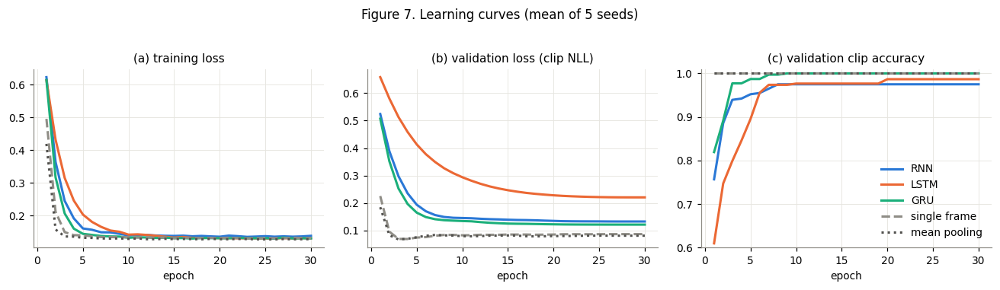

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for c in ALL:
    h = pd.concat([MAIN[(c, s)]["history"].assign(seed=s) for s in SEEDS]).groupby("epoch").mean()
    for a, k in zip(axes, ["train_loss", "val_loss", "val_acc"]):
        a.plot(h.index, h[k], color=COL[c], ls=LS.get(c, "-"), label=NICE[c])
axes[0].set(title="(a) training loss", xlabel="epoch"); axes[1].set(title="(b) validation loss (clip NLL)", xlabel="epoch")
axes[2].set(title="(c) validation clip accuracy", xlabel="epoch", ylim=(0.6, 1.01)); axes[2].legend()
fig.suptitle("Figure 7. Learning curves (mean of 5 seeds)", y=1.03)
fig.tight_layout(); savefig(fig, "fig07_learning_curves")

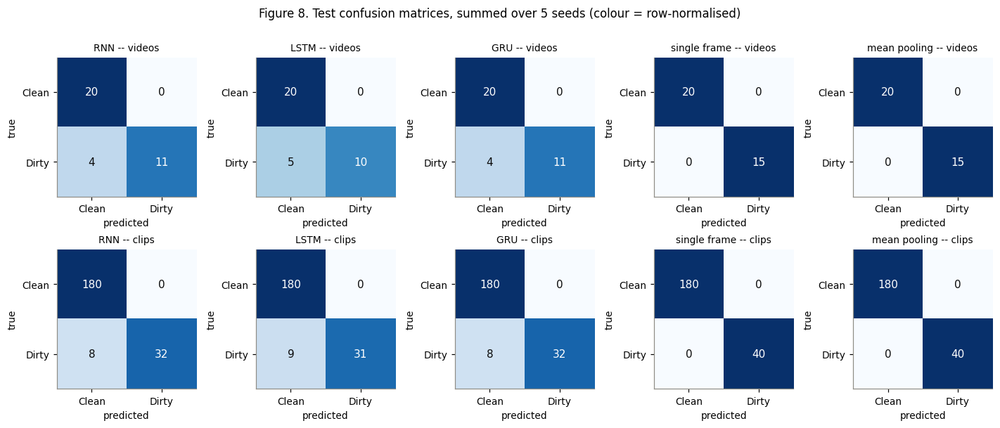

In [22]:
def conf_plot(ax, tp, tn, fp, fn, title):
    m = np.array([[tn, fp], [fn, tp]], float)
    ax.imshow(m / m.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(m[i, j])}", ha="center", va="center", fontsize=10,
                    color="white" if m[i, j] / m[i].sum() > 0.6 else "#0b0b0b")
    ax.set_xticks([0, 1], ["Clean", "Dirty"]); ax.set_yticks([0, 1], ["Clean", "Dirty"]); ax.grid(False)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for i, level in enumerate(["video", "clip"]):
    for j, c in enumerate(ALL):
        d = MAIN_RUNS[(MAIN_RUNS.model == c) & (MAIN_RUNS.level == level)][["TP", "TN", "FP", "FN"]].sum()
        conf_plot(axes[i, j], d.TP, d.TN, d.FP, d.FN, f"{NICE[c]} -- {level}s")
fig.suptitle("Figure 8. Test confusion matrices, summed over 5 seeds (colour = row-normalised)", y=1.01)
fig.tight_layout(); savefig(fig, "fig08_confusion_main")

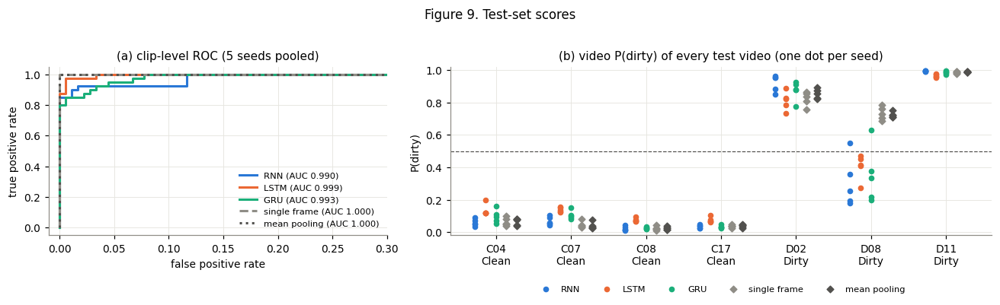

In [23]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
for c in ALL:
    cl = pd.concat([MAIN[(c, s)]["clips"] for s in SEEDS])
    fpr, tpr, _ = roc_curve(cl.label, cl.p_dirty)
    axes[0].plot(fpr, tpr, color=COL[c], ls=LS.get(c, "-"), label=f"{NICE[c]} (AUC {E.metrics(cl.label, cl.p_dirty)['AUC']:.3f})")
axes[0].set(title="(a) clip-level ROC (5 seeds pooled)", xlabel="false positive rate", ylabel="true positive rate", xlim=(-0.01, 0.3))
axes[0].legend(fontsize=7.5)
tv = SPLIT["test"]
for k, c in enumerate(ALL):
    for s in SEEDS:
        v = MAIN[(c, s)]["videos"].set_index("vid").loc[tv]
        axes[1].scatter(np.arange(len(tv)) + (k - 2) * 0.14, v.p_dirty, s=16, color=COL[c], label=NICE[c] if s == 0 else None,
                        marker="o" if c in CELLS else "D")
axes[1].axhline(0.5, color="#52514e", lw=0.8, ls="--")
axes[1].set_xticks(range(len(tv)), [f"{v}\n{D.CLASSES[LABELS[v]]}" for v in tv])
axes[1].set(title="(b) video P(dirty) of every test video (one dot per seed)", ylabel="P(dirty)", ylim=(-0.02, 1.02))
axes[1].legend(fontsize=7.5, ncol=5, loc="center", bbox_to_anchor=(0.5, -0.32))
fig.suptitle("Figure 9. Test-set scores", y=1.02)
fig.tight_layout(); savefig(fig, "fig09_roc_and_video_scores")

**Observations (held-out test split).** Training converges within about 10 epochs for every model (Figure 7). The LSTM is
the slowest, and its validation loss levels off highest (0.22 vs. 0.12--0.13 for the RNN and GRU), so its predictions are
the least confident. On the 7 test videos both baselines are perfect (accuracy, precision,
recall and F1 = 1.000 at clip and video level). The three recurrent models reach a clip accuracy of 0.959--0.964 and a
video accuracy of 0.857 (LSTM) and 0.886 (RNN, GRU). Their **precision is 1.000** in every seed: no clean clip or video was
ever called dirty. **All their mistakes are clips of D08**, which ends over waste land (Figure 9b). There the recurrent
models give P(dirty) of 0.2--0.6, while the two baselines, which weigh every frame equally, give 0.7--0.8. The clip AUC of
every model is ≥ 0.99, so the scores rank the clips almost perfectly; the problem is *where* in the clip the recurrent
models look, which §8 analyses. Because 7 test videos give a coarse estimate (one video = 14 points), §5 repeats the
evaluation on all 29 videos.

## 5. Grouped 5-fold cross-validation over all 29 videos

The test split has only 7 videos, so one mistake moves video accuracy by 14 points. In 5-fold grouped cross-validation every
video is predicted by a model that did not see it (fold *k* = test, fold *k*+1 = validation, rest = training), with 3 seeds
per fold. These out-of-fold predictions are also what the video index in §11 uses.

In [24]:
CV_SEEDS = [0, 1, 2]
t0 = time.time()
CV = {(c, s, k): TR.train_run(f"cv_{c}_f{k}_s{s}", c, cv_split(k), LABELS, STORE, {**CFG.get(c, {}), "seed": s}, save_weights=(s == 0))
      for c in ALL for s in CV_SEEDS for k in range(5)}
print(f"{len(CV)} runs ({time.time() - t0:.0f} s; cached)")
OOF_V = pd.concat([r["videos"].assign(model=c, seed=s, fold=k) for (c, s, k), r in CV.items()], ignore_index=True)
OOF_C = pd.concat([r["clips"].assign(model=c, seed=s, fold=k) for (c, s, k), r in CV.items()], ignore_index=True)
rows = []
for (c, s), d in OOF_V.groupby(["model", "seed"]):
    rows.append({"model": c, "seed": s, "level": "video", **E.metrics(d.label, d.p_dirty)})
for (c, s), d in OOF_C.groupby(["model", "seed"]):
    rows.append({"model": c, "seed": s, "level": "clip", **E.metrics(d.label, d.p_dirty)})
CV_RUNS = save(pd.DataFrame(rows), "cv_runs")
CV_SUMMARY = save(summary_table(CV_RUNS), "cv_summary")
display(CV_SUMMARY)

75 runs (0 s; cached)


,model,level,accuracy,precision,recall,F1,AUC
0,RNN,clip,0.969 ± 0.011,0.988 ± 0.009,0.931 ± 0.028,0.958 ± 0.016,0.988 ± 0.004
1,RNN,video,0.954 ± 0.016,1.000 ± 0.000,0.889 ± 0.039,0.941 ± 0.022,0.975 ± 0.011
2,LSTM,clip,0.952 ± 0.013,1.000 ± 0.000,0.874 ± 0.035,0.932 ± 0.020,0.993 ± 0.003
3,LSTM,video,0.943 ± 0.016,1.000 ± 0.000,0.861 ± 0.039,0.925 ± 0.022,0.982 ± 0.010
4,GRU,clip,0.967 ± 0.005,0.994 ± 0.008,0.920 ± 0.022,0.955 ± 0.008,0.985 ± 0.001
5,GRU,video,0.943 ± 0.016,1.000 ± 0.000,0.861 ± 0.039,0.925 ± 0.022,0.956 ± 0.004
6,MLP-frame,clip,0.969 ± 0.022,1.000 ± 0.000,0.920 ± 0.057,0.957 ± 0.031,1.000 ± 0.000
7,MLP-frame,video,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
8,MLP-mean,clip,0.993 ± 0.000,1.000 ± 0.000,0.983 ± 0.000,0.991 ± 0.000,1.000 ± 0.000
9,MLP-mean,video,0.977 ± 0.016,1.000 ± 0.000,0.944 ± 0.039,0.971 ± 0.020,1.000 ± 0.000


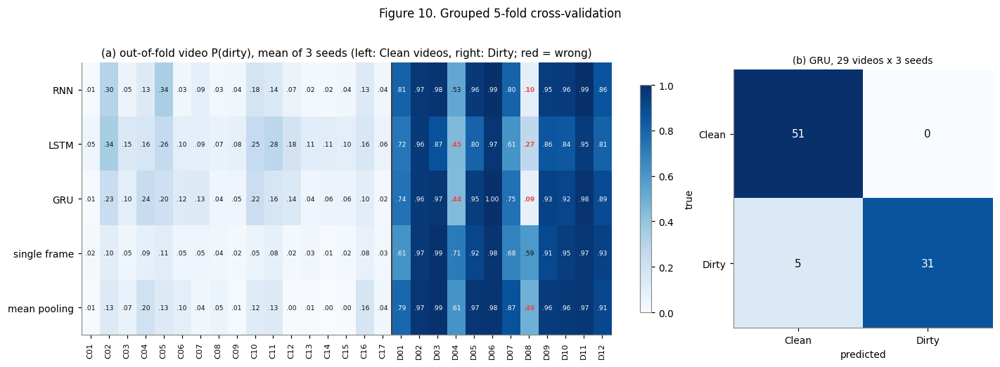

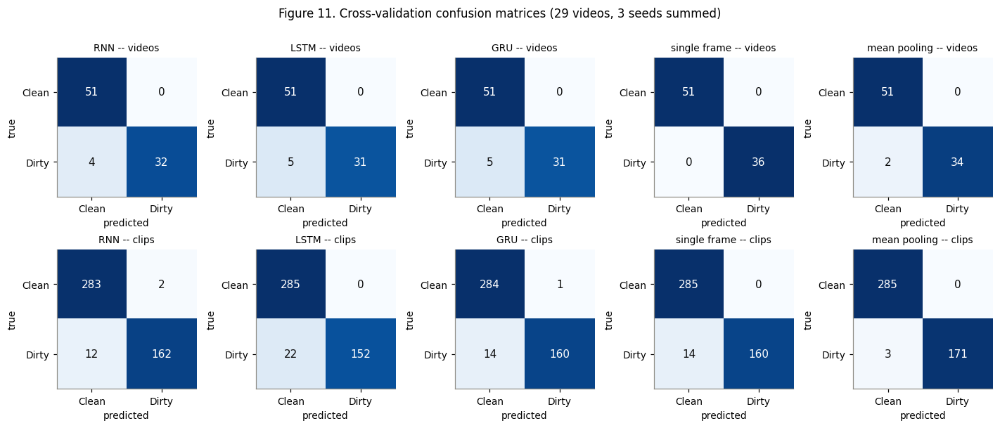

In [25]:
P = OOF_V.groupby(["vid", "model"]).p_dirty.mean().unstack()[ALL]
P = P.loc[VIDEOS.vid]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
im = axes[0].imshow(P.T.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(P)), P.index, rotation=90, fontsize=7.5); axes[0].set_yticks(range(len(ALL)), [NICE[c] for c in ALL])
for i, v in enumerate(P.index):
    for j, c in enumerate(ALL):
        wrong = (P.loc[v, c] >= 0.5) != LABELS[v]
        axes[0].text(i, j, f"{P.loc[v, c]:.2f}".lstrip("0"), ha="center", va="center", fontsize=6,
                     color="#e34948" if wrong else ("white" if P.loc[v, c] > 0.6 else "#0b0b0b"), weight="bold" if wrong else None)
axes[0].axvline(16.5, color="#0b0b0b", lw=1); axes[0].grid(False)
axes[0].set_title("(a) out-of-fold video P(dirty), mean of 3 seeds (left: Clean videos, right: Dirty; red = wrong)")
plt.colorbar(im, ax=axes[0], fraction=0.02)
for j, c in enumerate(ALL):
    d = CV_RUNS[(CV_RUNS.model == c) & (CV_RUNS.level == "video")][["TP", "TN", "FP", "FN"]].sum()
    if c == "GRU":
        conf_plot(axes[1], d.TP, d.TN, d.FP, d.FN, "(b) GRU, 29 videos x 3 seeds")
fig.suptitle("Figure 10. Grouped 5-fold cross-validation", y=1.02)
fig.tight_layout(); savefig(fig, "fig10_cv_video_scores")
fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for i, level in enumerate(["video", "clip"]):
    for j, c in enumerate(ALL):
        d = CV_RUNS[(CV_RUNS.model == c) & (CV_RUNS.level == level)][["TP", "TN", "FP", "FN"]].sum()
        conf_plot(axes[i, j], d.TP, d.TN, d.FP, d.FN, f"{NICE[c]} -- {level}s")
fig.suptitle("Figure 11. Cross-validation confusion matrices (29 videos, 3 seeds summed)", y=1.01)
fig.tight_layout(); savefig(fig, "fig11_confusion_cv")

**Observations (cross-validation).** Over all 29 videos (3 seeds) the picture holds. Video accuracy is 0.954 (RNN), 0.943
(LSTM) and 0.943 (GRU), against 1.000 for the single-frame baseline and 0.977 for mean pooling. Clip accuracy is 0.969,
0.952 and 0.967, against 0.969 and 0.993. Again **no clean video is ever indexed as dirty** (video precision 1.000 for
every model). Figure 10 shows which dirty videos are missed: **D08** by all three recurrent models in every seed, and
**D04** (dump with sticks under a bright sky; scores close to 0.5) by the GRU and LSTM in 2 of 3 seeds and by the RNN in 1.
Among the three cells the RNN is marginally the most accurate and the LSTM the least, but the differences (≤ 0.02) are
within the seed-to-seed spread.

## 6. Sequence length and frame-sampling rate

Each recurrent model is retrained for every combination of sampling rate **fps ∈ {0.5, 1, 2, 4, 8}** and sequence length
**T ∈ {1, 4, 8, 16, 32, 64}** frames with the grouped 5-fold protocol (seed 0, 450 runs). A clip then spans T / fps
seconds (0.125 s to 128 s); a video shorter than the span is used whole. Because the number of clips per video changes with
the configuration, clip accuracy is averaged **per video first** (every video counts once). Video accuracy, clip AUC and
clip log-loss are reported as well.

In [26]:
FPS_GRID, T_GRID = [0.5, 1, 2, 4, 8], [1, 4, 8, 16, 32, 64]
t0 = time.time(); rows = []
for c in CELLS:
    for fps in FPS_GRID:
        for T in T_GRID:
            cl, vd = [], []
            for k in range(5):
                r = TR.train_run(f"grid_{c}_fps{fps}_T{T}_f{k}", c, cv_split(k), LABELS, STORE, {"fps": fps, "T": T})
                cl.append(r["clips"]); vd.append(r["videos"])
            cl, vd = pd.concat(cl), pd.concat(vd)
            p = np.clip(cl.p_dirty, 1e-6, 1 - 1e-6)
            cl["ok"] = (cl.p_dirty >= 0.5) == cl.label
            rows.append({"model": c, "fps": fps, "T": T, "span_s": T / fps,
                         "clip_acc_balanced": cl.groupby("vid").ok.mean().mean(), "clip_AUC": E.metrics(cl.label, cl.p_dirty)["AUC"],
                         "clip_logloss": float(-(cl.label * np.log(p) + (1 - cl.label) * np.log(1 - p)).mean()),
                         "clip_F1": E.metrics(cl.label, cl.p_dirty)["F1"],
                         "video_acc": E.metrics(vd.label, vd.p_dirty)["accuracy"], "clips": len(cl)})
GRID = save(pd.DataFrame(rows), "grid_fps_T")
print(f"grid done ({time.time() - t0:.0f} s; cached)")
display(GRID.pivot_table(index=["model", "fps"], columns="T", values="clip_acc_balanced").round(3))

grid done (1 s; cached)


T             1      4      8      16     32     64
model fps                                          
GRU   0.5  0.969  0.967  0.957  0.948  0.931  0.931
      1.0  0.963  0.975  0.961  0.957  0.948  0.931
      2.0  0.955  0.971  0.969  0.950  0.922  0.948
      4.0  0.956  0.961  0.976  0.966  0.953  0.905
      8.0  0.958  0.967  0.972  0.976  0.963  0.930
LSTM  0.5  0.963  0.954  0.912  0.900  0.897  0.931
      1.0  0.952  0.964  0.949  0.921  0.945  0.948
      2.0  0.952  0.953  0.945  0.943  0.909  0.903
      4.0  0.952  0.961  0.953  0.942  0.929  0.907
      8.0  0.950  0.945  0.950  0.946  0.929  0.931
RNN   0.5  0.987  0.967  0.957  0.948  0.931  0.931
      1.0  0.978  0.971  0.961  0.922  0.948  0.897
      2.0  0.974  0.979  0.967  0.948  0.925  0.839
      4.0  0.972  0.973  0.973  0.970  0.954  0.905
      8.0  0.969  0.972  0.969  0.963  0.956  0.931

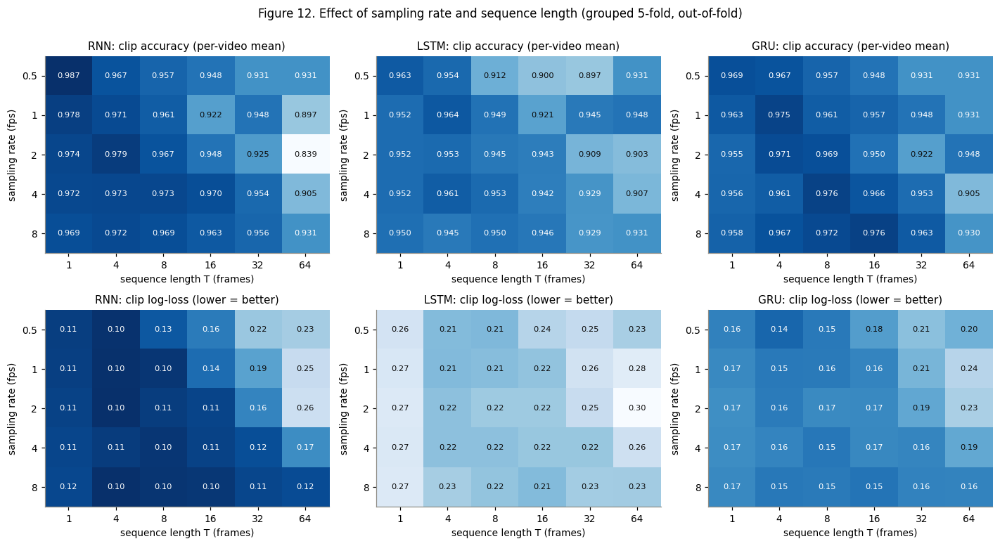

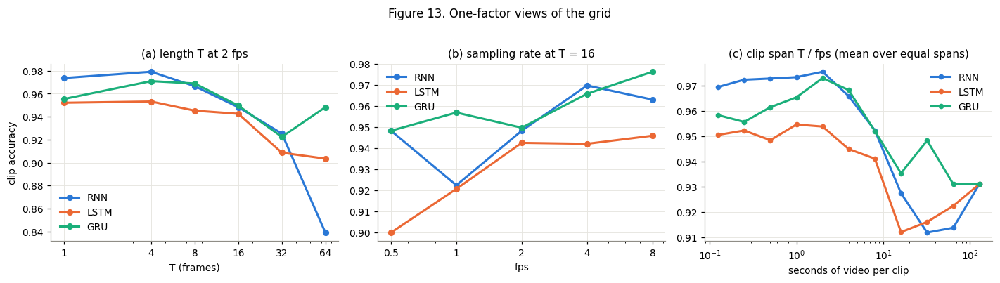

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, c in enumerate(CELLS):
    for i, (key, cmap, fmt) in enumerate([("clip_acc_balanced", "Blues", "{:.3f}"), ("clip_logloss", "Blues_r", "{:.2f}")]):
        g = GRID[GRID.model == c].pivot(index="fps", columns="T", values=key)
        lo, hi = GRID[key].min(), GRID[key].max()
        axes[i, j].imshow(g.values, cmap=cmap, vmin=lo, vmax=hi, aspect="auto")
        for a in range(g.shape[0]):
            for b in range(g.shape[1]):
                val = g.values[a, b]; d = (val - lo) / (hi - lo + 1e-9)
                ink = d if cmap == "Blues" else 1 - d          # how dark the cell is drawn
                axes[i, j].text(b, a, fmt.format(val), ha="center", va="center", fontsize=7.5,
                                color="white" if ink > 0.6 else "#0b0b0b")
        axes[i, j].set_xticks(range(len(T_GRID)), T_GRID); axes[i, j].set_yticks(range(len(FPS_GRID)), FPS_GRID)
        axes[i, j].set(xlabel="sequence length T (frames)", ylabel="sampling rate (fps)",
                       title=f"{c}: " + ("clip accuracy (per-video mean)" if i == 0 else "clip log-loss (lower = better)"))
        axes[i, j].grid(False)
fig.suptitle("Figure 12. Effect of sampling rate and sequence length (grouped 5-fold, out-of-fold)", y=1.0)
fig.tight_layout(); savefig(fig, "fig12_grid_heatmaps")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for c in CELLS:
    g = GRID[GRID.model == c]
    a = g[g.fps == 2].sort_values("T"); axes[0].plot(a["T"], a.clip_acc_balanced, "o-", color=COL[c], label=c, ms=5)
    b = g[g["T"] == 16].sort_values("fps"); axes[1].plot(b.fps, b.clip_acc_balanced, "o-", color=COL[c], label=c, ms=5)
    s = g.groupby("span_s").clip_acc_balanced.mean(); axes[2].plot(s.index, s.values, "o-", color=COL[c], label=c, ms=4)
axes[0].set(xscale="log", title="(a) length T at 2 fps", xlabel="T (frames)", ylabel="clip accuracy"); axes[0].set_xticks(T_GRID, T_GRID)
axes[1].set(xscale="log", title="(b) sampling rate at T = 16", xlabel="fps"); axes[1].set_xticks(FPS_GRID, FPS_GRID)
axes[2].set(xscale="log", title="(c) clip span T / fps (mean over equal spans)", xlabel="seconds of video per clip")
for a in axes: a.legend()
fig.suptitle("Figure 13. One-factor views of the grid", y=1.03)
fig.tight_layout(); savefig(fig, "fig13_grid_lines")

**Observations (sequence length and sampling rate).** Figure 12 and Figure 13 give the same message for all three cells:
**short clips are best, and accuracy falls once a clip spans more than about 8 s.** At T = 1 every cell indexes all 29
videos correctly at every sampling rate. At T = 64 video accuracy drops to 0.83--0.97, and the worst cell of the grid is
the RNN at 2 fps x 64 frames (32 s of video, clip accuracy 0.839). Figure 13c plots accuracy against the clip span T / fps:
the curves stay at about 0.96--0.98 up to spans of 2--4 s and decline beyond 8--16 s.

The **sampling rate matters mostly through the span** it creates. At a fixed T = 16, going from 0.5 fps (32 s span) to
4--8 fps (2--4 s span) raises clip accuracy, for example RNN 0.948 → 0.970 and GRU 0.948 → 0.976. At a fixed short span
the rate makes little difference: a 2-s clip is 4 frames at 2 fps or 16 frames at 8 fps, and both score 0.95--0.98. Long
clips hurt because the camera moves through different content within one clip (D08, D07), and a last-state readout reports
mostly the *end* of the clip. The best settings are RNN 0.5 fps x 1 frame (0.987), GRU 4 fps x 8 frames and 8 fps x 16
frames (0.976), and LSTM 1 fps x 4 frames (0.964). The log-loss maps add a calibration ranking: the RNN is the most
confident (0.10--0.12 at short spans), then the GRU (0.15--0.17), then the LSTM (0.21--0.27), which spreads its
probabilities furthest from 0 and 1.

## 7. Computational complexity and inference speed

Parameters and multiply-accumulates (MACs) are counted for the indexing head (the frozen ResNet-50 is shared by all
models). Latency is the median of 200 forward passes of one 16-frame clip (batch 1) on the GPU (RTX 5070 Ti, cuDNN
kernels) and on the CPU; throughput uses a batch of 256 clips. Figure 14 shows how the cost grows with T.

,model,parameters,MACs per clip (T=16),weights file (MB),GPU latency (ms/clip),CPU latency (ms/clip),GPU throughput (clips/s)
0,RNN,279042,4456512,1.136,0.499,0.265,287624.287
1,LSTM,1115394,17825856,4.481,0.722,0.501,256963.616
2,GRU,836610,13369408,3.366,0.562,0.524,277296.360
3,MLP-frame,262530,4194368,1.070,0.275,0.137,497715.561
4,MLP-mean,262530,262208,1.070,0.232,0.096,645568.012


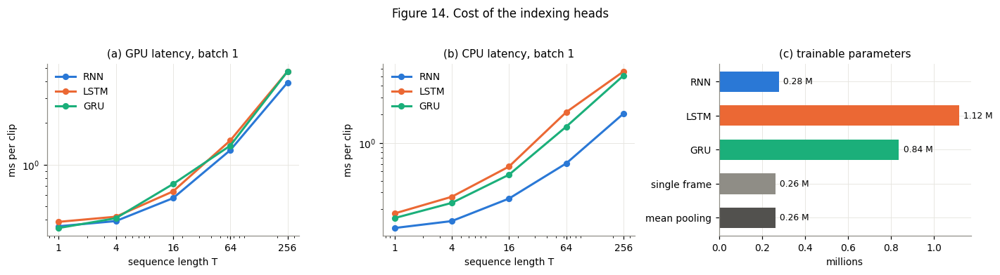

In [28]:
RETIME = False          # timings are measured once and cached (sub-millisecond timings jitter between runs)
rows = []
for c in ALL if RETIME or not (RES / "complexity.csv").exists() else []:
    m, _ = TR.load_model(f"main_{c}_s0")
    rows.append({"model": c, "parameters": M.n_params(m),
                 "MACs per clip (T=16)": (M.recurrent_macs(c, T=16) if c in CELLS else (16 if c == "MLP-frame" else 1) * 2048 * 128) + 16 * 4,
                 "weights file (MB)": (TR.RUNS / f"main_{c}_s0" / "best.pt").stat().st_size / 1e6,
                 "GPU latency (ms/clip)": E.latency(m, 16, "cuda"), "CPU latency (ms/clip)": E.latency(m, 16, "cpu", runs=100),
                 "GPU throughput (clips/s)": 256 / (E.latency(m, 16, "cuda", batch=256, runs=50) / 1000)})
COMPLEXITY = save(pd.DataFrame(rows), "complexity") if rows else pd.read_csv(RES / "complexity.csv")
display(COMPLEXITY.round(3))
LAT = []
for c in CELLS if RETIME or not (RES / "latency_vs_T.csv").exists() else []:
    m, _ = TR.load_model(f"main_{c}_s0")
    for T in [1, 4, 16, 64, 256]:
        LAT.append({"model": c, "T": T, "GPU": E.latency(m, T, "cuda", runs=100), "CPU": E.latency(m, T, "cpu", runs=30)})
LAT = save(pd.DataFrame(LAT), "latency_vs_T") if LAT else pd.read_csv(RES / "latency_vs_T.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for c in CELLS:
    d = LAT[LAT.model == c]
    axes[0].plot(d["T"], d.GPU, "o-", color=COL[c], label=c, ms=5); axes[1].plot(d["T"], d.CPU, "o-", color=COL[c], label=c, ms=5)
for a, t in zip(axes[:2], ["(a) GPU latency, batch 1", "(b) CPU latency, batch 1"]):
    a.set(xscale="log", yscale="log", xlabel="sequence length T", ylabel="ms per clip", title=t); a.set_xticks([1, 4, 16, 64, 256], [1, 4, 16, 64, 256]); a.legend()
cx = COMPLEXITY.set_index("model").loc[ALL]
axes[2].barh([NICE[c] for c in ALL], cx.parameters / 1e6, color=[COL[c] for c in ALL], height=0.6)
for i, v in enumerate(cx.parameters / 1e6): axes[2].text(v + 0.02, i, f"{v:.2f} M", va="center", fontsize=8)
axes[2].set(title="(c) trainable parameters", xlabel="millions"); axes[2].invert_yaxis()
fig.suptitle("Figure 14. Cost of the indexing heads", y=1.03)
fig.tight_layout(); savefig(fig, "fig14_complexity")

**Whole pipeline.** Indexing a new video also needs decoding and the CNN. The table gives the cost for one minute of
1080p video sampled at 2 fps (120 frames, 14 clips).

In [29]:
def time_pipeline():
    r = VIDEOS.set_index("vid").loc["C08"]                    # 64 s, 1080p, 30 fps
    c = cv2.VideoCapture(str(D.DATA / r.file)); times, idx = D.sample_indices(r.n_frames, r.fps, 2.0); want = set(idx.tolist())
    t = time.perf_counter()
    for i in range(int(idx.max()) + 1):
        ok = c.read()[0] if i in want else c.grab()
    c.release()
    decode_s_per_min = (time.perf_counter() - t) / r.duration_s * 60
    n_clips = len(TR.eval_clips(120 * 4, 2.0, 16))
    rows = [{"stage": "decode (OpenCV, sequential)", "seconds per video-minute": decode_s_per_min},
            {"stage": "ResNet-50 features (120 frames)", "seconds per video-minute": CNN_MS_PER_FRAME * 120 / 1000}]
    for cc in ALL:
        rows.append({"stage": f"{NICE[cc]} head ({n_clips} clips, GPU)",
                     "seconds per video-minute": COMPLEXITY.set_index("model").loc[cc, "GPU latency (ms/clip)"] * n_clips / 1000})
    return save(pd.DataFrame(rows), "pipeline_cost")

PIPE = time_pipeline() if RETIME or not (RES / "pipeline_cost.csv").exists() else pd.read_csv(RES / "pipeline_cost.csv")
display(PIPE.round(4))

,stage,seconds per video-minute
0,"decode (OpenCV, sequential)",1.0771
1,ResNet-50 features (120 frames),0.0426
2,"RNN head (14 clips, GPU)",0.0070
3,"LSTM head (14 clips, GPU)",0.0101
4,"GRU head (14 clips, GPU)",0.0079
5,"single frame head (14 clips, GPU)",0.0038
6,"mean pooling head (14 clips, GPU)",0.0032


**Hidden size.** The default (128 units) gives the three cells different parameter counts. Retraining with 32--256 units
(main split, 3 seeds) shows whether accuracy follows parameter count or cell type.

,model,hidden,seed,parameters,clip_acc,clip_logloss,video_acc
0,GRU,32,1.0,199938.0,0.9545,0.2182,0.9048
1,GRU,64,1.0,406018.0,0.9545,0.1058,0.8571
2,GRU,128,1.0,836610.0,0.9545,0.1284,0.8571
3,GRU,256,1.0,1771522.0,0.9545,0.1067,0.8571
4,LSTM,32,1.0,266562.0,0.8864,0.4082,0.8095
5,LSTM,64,1.0,541314.0,0.9697,0.2520,0.9524
6,LSTM,128,1.0,1115394.0,0.9621,0.1507,0.8571
7,LSTM,256,1.0,2361858.0,0.9621,0.1205,0.8571
8,RNN,32,1.0,66690.0,0.9470,0.2241,0.8571
9,RNN,64,1.0,135426.0,0.9470,0.1618,0.8571


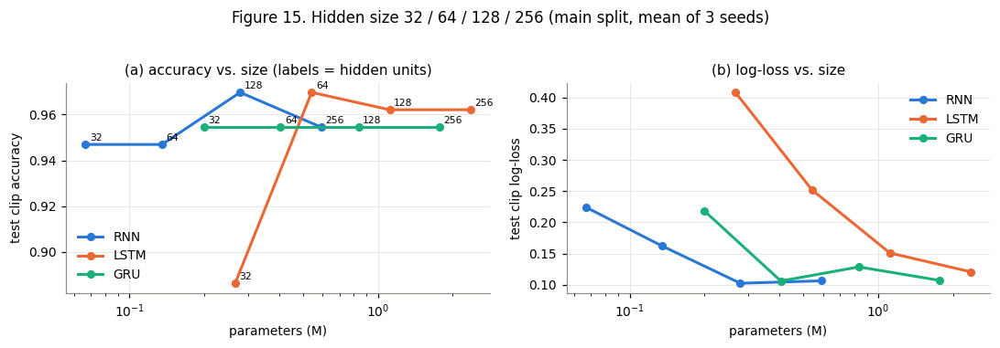

In [30]:
rows = []
for c in CELLS:
    for h in [32, 64, 128, 256]:
        for s in [0, 1, 2]:
            r = MAIN[(c, s)] if h == 128 else TR.train_run(f"hid_{c}_h{h}_s{s}", c, SPLIT, LABELS, STORE, {"hidden": h, "seed": s})
            cl = r["clips"]; p = np.clip(cl.p_dirty, 1e-6, 1 - 1e-6)
            rows.append({"model": c, "hidden": h, "seed": s, "parameters": r["params"], "clip_acc": E.metrics(cl.label, cl.p_dirty)["accuracy"],
                         "clip_logloss": float(-(cl.label * np.log(p) + (1 - cl.label) * np.log(1 - p)).mean()),
                         "video_acc": E.metrics(r["videos"].label, r["videos"].p_dirty)["accuracy"]})
HID = save(pd.DataFrame(rows), "hidden_size")
hs = HID.groupby(["model", "hidden"]).mean(numeric_only=True).reset_index()
display(hs.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for c in CELLS:
    d = hs[hs.model == c]
    axes[0].plot(d.parameters / 1e6, d.clip_acc, "o-", color=COL[c], label=c, ms=5)
    axes[1].plot(d.parameters / 1e6, d.clip_logloss, "o-", color=COL[c], label=c, ms=5)
    for _, q in d.iterrows(): axes[0].annotate(int(q.hidden), (q.parameters / 1e6, q.clip_acc), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[0].set(xscale="log", xlabel="parameters (M)", ylabel="test clip accuracy", title="(a) accuracy vs. size (labels = hidden units)")
axes[1].set(xscale="log", xlabel="parameters (M)", ylabel="test clip log-loss", title="(b) log-loss vs. size")
for a in axes: a.legend()
fig.suptitle("Figure 15. Hidden size 32 / 64 / 128 / 256 (main split, mean of 3 seeds)", y=1.03)
fig.tight_layout(); savefig(fig, "fig15_hidden_size")

**Observations (complexity and speed).** The parameter counts follow the number of weight blocks: the RNN has 0.28 M
trainable parameters, the GRU 0.84 M (3x) and the LSTM 1.12 M (4x); per 16-frame clip they need 4.5 M, 13.4 M and 17.8 M
multiply-accumulates. On the GPU a single clip takes about 0.5--0.7 ms for all three cells (Figure 14a). At this size
the time is dominated by kernel-launch overhead, and the differences between cells are within run-to-run jitter. On the
CPU the RNN is about **twice as fast** as the gated cells: 0.27 ms vs. 0.50 ms (LSTM) and 0.52 ms (GRU) at T = 16, and
2.0 ms vs. 5.6 ms (LSTM) and 5.1 ms (GRU) at T = 256. The cost grows linearly with T, steepest for the LSTM.

In the full indexing pipeline, however, **decoding dominates**: about 1.1 s per minute of 1080p video, against 0.04 s for
the ResNet-50 features and under 0.01 s for any recurrent head. The choice of cell therefore has no practical effect on
indexing speed.

The hidden-size sweep (Figure 15) shows that accuracy does not follow parameter count: every configuration lands at
0.95--0.97 test clip accuracy except the smallest LSTM (32 units, 0.886), and the log-loss improves only up to about 64--128
units. The extra parameters of the gated cells buy nothing on whole-video clean / dirty labels.

## 8. Does temporal information help?

Four complementary tests:

1. **Frames vs. sequences** -- the single-frame and mean-pooling baselines against the recurrent models (§4, §5), and T = 1
   against longer T (§6).
2. **Order tests** -- the trained models score the test clips again after the frames are shuffled, reversed, replaced by
   one repeated middle frame, or halved (every second frame dropped). A model that relies on frame order should change its
   answer when the order is destroyed.
3. **Evidence over time** -- P(correct class) after each of the 16 steps, and the gradient of the decision with respect to
   each frame (which time steps the final decision depends on).
4. **Memory probe** -- a controlled task where order matters by construction (§8.1).

In [31]:
rows = []
for name, runs, keyset in [("test split (5 seeds)", MAIN_RUNS, SEEDS), ("5-fold CV (3 seeds)", CV_RUNS, CV_SEEDS)]:
    for c in ALL:
        for level in ["video", "clip"]:
            d = runs[(runs.model == c) & (runs.level == level)]
            rows.append({"evaluation": name, "model": NICE[c], "level": level, "accuracy": pm(d.accuracy), "F1": pm(d.F1), "AUC": pm(d.AUC)})
# single frames scored on their own (no aggregation at all)
fr = []
for s in SEEDS:
    m, _ = TR.load_model(f"main_MLP-frame_s{s}")
    cl = TR.predict_clips(m, STORE, SPLIT["test"], 2.0, 1); cl["label"] = cl.vid.map(LABELS)
    fr.append(E.metrics(cl.label, cl.p_dirty))
fr = pd.DataFrame(fr)
rows.append({"evaluation": "test split (5 seeds)", "model": "single frame", "level": "individual frame",
             "accuracy": pm(fr.accuracy), "F1": pm(fr.F1), "AUC": pm(fr.AUC)})
FRAME_VS_SEQ = save(pd.DataFrame(rows), "frame_vs_sequence")
display(FRAME_VS_SEQ)

,evaluation,model,level,accuracy,F1,AUC
0,test split (5 seeds),RNN,video,0.886 ± 0.057,0.840 ± 0.080,1.000 ± 0.000
1,test split (5 seeds),RNN,clip,0.964 ± 0.018,0.886 ± 0.057,0.992 ± 0.006
2,test split (5 seeds),LSTM,video,0.857 ± 0.000,0.800 ± 0.000,1.000 ± 0.000
3,test split (5 seeds),LSTM,clip,0.959 ± 0.009,0.872 ± 0.030,0.999 ± 0.001
4,test split (5 seeds),GRU,video,0.886 ± 0.057,0.840 ± 0.080,1.000 ± 0.000
5,test split (5 seeds),GRU,clip,0.964 ± 0.018,0.886 ± 0.057,0.994 ± 0.005
6,test split (5 seeds),single frame,video,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
7,test split (5 seeds),single frame,clip,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
8,test split (5 seeds),mean pooling,video,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
9,test split (5 seeds),mean pooling,clip,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000


clip_acc                                       mean_abs_change_P  \
test      drop_half middle_frame original reverse shuffle         drop_half   
model                                                                         
RNN          0.9818       0.9818   0.9636     1.0  0.9955            0.0310   
LSTM         0.9818       0.9727   0.9591     1.0  0.9909            0.0336   
GRU          0.9864       0.9773   0.9636     1.0  0.9955            0.0269   
MLP-frame    1.0000       0.9773   1.0000     1.0  1.0000            0.0058   
MLP-mean     1.0000       0.9773   1.0000     1.0  1.0000            0.0074   

                                                 
test      middle_frame original reverse shuffle  
model                                            
RNN             0.0525      0.0  0.0615  0.0559  
LSTM            0.0656      0.0  0.0651  0.0470  
GRU             0.0597      0.0  0.0600  0.0485  
MLP-frame       0.0257      0.0  0.0000  0.0000  
MLP-mean        0.0266      0.0  0.0000  0.0000

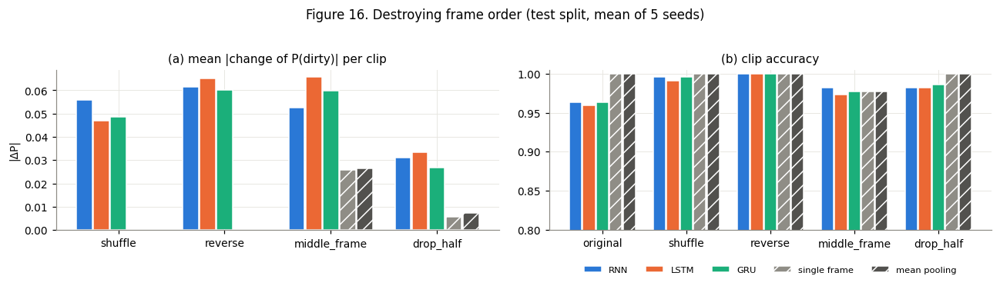

In [32]:
rows = []
for c in ALL:
    for s in SEEDS:
        m, _ = TR.load_model(f"main_{c}_s{s}")
        base = TR.predict_clips(m, STORE, SPLIT["test"], 2.0, 16)
        base["label"] = base.vid.map(LABELS)
        for kind in ["original", "shuffle", "reverse", "middle_frame", "drop_half"]:
            cl = base if kind == "original" else TR.predict_clips(m, STORE, SPLIT["test"], 2.0, 16, transform=E.temporal_transform(kind, s))
            cl["label"] = cl.vid.map(LABELS)
            full = base.n == 16
            rows.append({"model": c, "seed": s, "test": kind, "clip_acc": E.metrics(cl.label, cl.p_dirty)["accuracy"],
                         "mean_abs_change_P": float(np.abs(cl.p_dirty.values - base.p_dirty.values)[full.values].mean())})
ORDER = save(pd.DataFrame(rows), "order_tests")
ot = ORDER.groupby(["model", "test"])[["clip_acc", "mean_abs_change_P"]].mean().unstack()
display(ot.loc[ALL].round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
tests = ["shuffle", "reverse", "middle_frame", "drop_half"]
for k, c in enumerate(ALL):
    axes[0].bar(np.arange(4) + (k - 2) * 0.16, [ot.loc[c, ("mean_abs_change_P", t)] for t in tests], 0.15, color=COL[c], label=NICE[c],
                hatch="//" if c in BASELINES else None, edgecolor="white")
    axes[1].bar(np.arange(5) + (k - 2) * 0.16, [ot.loc[c, ("clip_acc", t)] for t in ["original"] + tests], 0.15, color=COL[c], label=NICE[c],
                hatch="//" if c in BASELINES else None, edgecolor="white")
axes[0].set_xticks(range(4), tests); axes[0].set(title="(a) mean |change of P(dirty)| per clip", ylabel="|ΔP|")
axes[1].set_xticks(range(5), ["original"] + tests); axes[1].set(title="(b) clip accuracy", ylim=(0.8, 1.005))
axes[1].legend(fontsize=7.5, ncol=5, loc="center", bbox_to_anchor=(0.5, -0.25))
fig.suptitle("Figure 16. Destroying frame order (test split, mean of 5 seeds)", y=1.03)
fig.tight_layout(); savefig(fig, "fig16_order_tests")

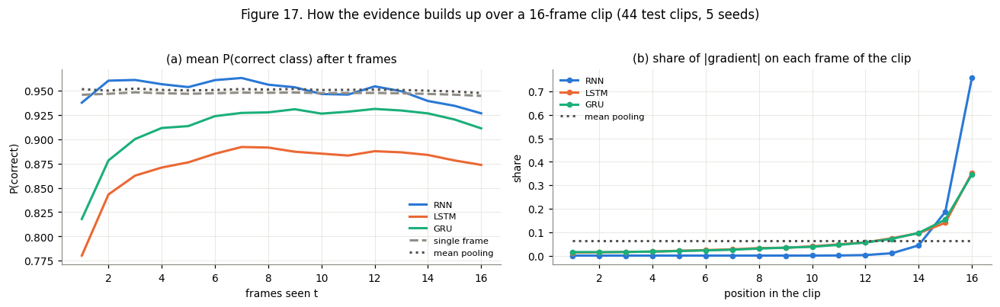

share of the gradient on the last 4 frames: {'RNN': 0.997, 'LSTM': 0.661, 'GRU': 0.667, 'MLP-mean': 0.25}


In [33]:
X, Y = [], []
for v in SPLIT["test"]:
    for idx in TR.eval_clips(STORE.n(v), 2.0, 16):
        if len(idx) == 16:
            X.append(STORE.f[v][torch.as_tensor(idx, device="cuda")]); Y.append(LABELS[v])
X, Y = torch.stack(X), np.array(Y)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
SAL = {}
for c in ALL:
    pc, sal = [], []
    for s in SEEDS:
        m, _ = TR.load_model(f"main_{c}_s{s}")
        p = E.prefix_probs(m, X); pc.append(np.where(Y[:, None] == 1, p, 1 - p).mean(0))
        if c in CELLS or c == "MLP-mean":
            g = E.temporal_saliency(m, X); sal.append(g / g.sum())
    axes[0].plot(range(1, 17), np.mean(pc, 0), color=COL[c], ls=LS.get(c, "-"), label=NICE[c])
    if sal:
        SAL[c] = np.mean(sal, 0)
        axes[1].plot(range(1, 17), SAL[c], "o-" if c in CELLS else ":", color=COL[c], label=NICE[c], ms=4)
axes[0].set(title="(a) mean P(correct class) after t frames", xlabel="frames seen t", ylabel="P(correct)")
axes[1].set(title="(b) share of |gradient| on each frame of the clip", xlabel="position in the clip", ylabel="share")
for a in axes: a.legend(fontsize=7.5)
fig.suptitle(f"Figure 17. How the evidence builds up over a 16-frame clip ({len(X)} test clips, 5 seeds)", y=1.03)
fig.tight_layout(); savefig(fig, "fig17_prefix_and_saliency")
save(pd.DataFrame(SAL, index=range(1, 17)), "temporal_saliency", index=True)
print("share of the gradient on the last 4 frames:", {c: round(float(v[-4:].sum()), 3) for c, v in SAL.items()})

### 8.1 Memory probe: remembering a short dirty moment

The clean-vs-dirty videos above hardly need memory: almost every frame of a dirty video shows garbage. To measure the
*ability to capture temporal information* directly, the probe asks **"did a dirty moment occur anywhere in this stream?"**.
A stream of L frames (2 fps) is spliced from short pieces of clean videos, and one 4-frame piece (2 s) is inserted at a
chosen position: from a dirty video (answer *Dirty*) or from another clean video (answer *Clean*, so a cut by itself is
no clue). The model reads the whole stream and answers at the last frame, so it must carry the evidence for
`frames_after` steps. Streams are built from the training, validation and test videos of the main split respectively;
L ∈ {16, 32, 64, 128}, 3 seeds, lr 1e-3, input dropout 0.1, 60 epochs x 25 batches of 64. The RNN is also trained with 448
units (**RNN-448**, about as many parameters as the LSTM) to separate the effect of gating from model size.

In [34]:
PS = {k: E.ProbeSampler(STORE, [v for v in SPLIT[k] if LABELS[v] == 0], [v for v in SPLIT[k] if LABELS[v] == 1]) for k in SPLIT}
PROBE_L = [16, 32, 64, 128]
PROBE_MODELS = [("RNN", 128, "RNN"), ("LSTM", 128, "LSTM"), ("GRU", 128, "GRU"), ("MLP-mean", 128, "MLP-mean"), ("RNN", 448, "RNN-448")]
path = RES / "probe_runs.csv"
PROBE = pd.read_csv(path) if path.exists() else pd.DataFrame()
t0 = time.time()
for L in PROBE_L:
    for cell, h, label in PROBE_MODELS:
        for s in [0, 1, 2]:
            if len(PROBE) and ((PROBE.L == L) & (PROBE.model == label) & (PROBE.seed == s)).any():
                continue
            res, hist, be = E.probe_run(cell, PS["train"], PS["val"], PS["test"], L, k=4, seed=s, epochs=60, steps=25,
                                        hidden=h, cfg={"lr": 1e-3, "dropout": 0.1})
            res["model"] = label; res["best_epoch"] = be
            PROBE = pd.concat([PROBE, res], ignore_index=True); PROBE.to_csv(path, index=False)
print(f"probe ready ({time.time() - t0:.0f} s; cached)")
pr = PROBE.groupby(["L", "model"]).agg(mean_acc=("accuracy", "mean")).unstack()["mean_acc"]
far = PROBE[PROBE.frames_after == PROBE.groupby("L").frames_after.transform("max")].groupby(["L", "model"]).accuracy.mean().unstack()
end = PROBE[PROBE.frames_after == 0].groupby(["L", "model"]).accuracy.mean().unstack()
PROBE_SUMMARY = pd.concat({"mean over positions": pr, "insert at the start": far, "insert at the end": end}, axis=1).round(3)
save(PROBE_SUMMARY.set_axis([f"{a} | {b}" for a, b in PROBE_SUMMARY.columns], axis=1), "probe_summary", index=True)
display(PROBE_SUMMARY)

probe ready (0 s; cached)


mean over positions                                insert at the start  \
model                 GRU   LSTM MLP-mean    RNN RNN-448                 GRU   
L                                                                              
16                  0.850  0.835    0.722  0.609   0.584               0.781   
32                  0.813  0.734    0.658  0.591   0.566               0.694   
64                  0.811  0.731    0.565  0.542   0.519               0.701   
128                 0.789  0.730    0.514  0.539   0.510               0.661   

                                     insert at the end                         \
model   LSTM MLP-mean    RNN RNN-448               GRU   LSTM MLP-mean    RNN   
L                                                                               
16     0.755    0.745  0.586   0.526             0.932  0.917    0.714  0.715   
32     0.622    0.628  0.546   0.521             0.935  0.880    0.639  0.724   
64     0.622    0.564  0.514   0.520             0.935  0.888    0.561  0.874   
128    0.682    0.499  0.505   0.509             0.935  0.836    0.493  0.801   

               
model RNN-448  
L              
16      0.632  
32      0.777  
64      0.630  
128     0.520

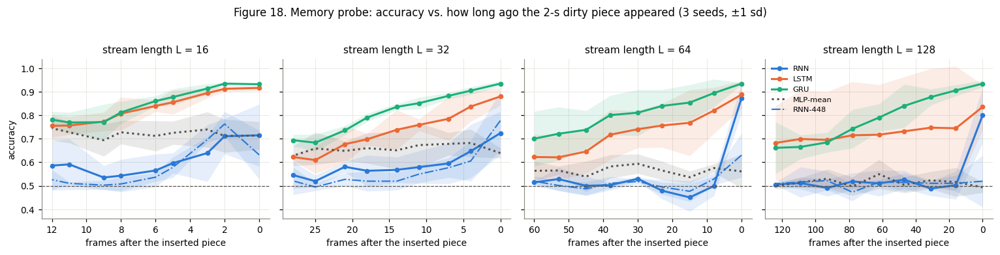

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for a, L in zip(axes, PROBE_L):
    for _, _, label in PROBE_MODELS:
        d = PROBE[(PROBE.L == L) & (PROBE.model == label)].groupby("frames_after").accuracy.agg(["mean", "std"])
        a.plot(d.index, d["mean"], "o-" if label in CELLS else LS.get(label, "-"), color=COL[label], label=label, ms=4,
               lw=2 if label != "RNN-448" else 1.4)
        a.fill_between(d.index, d["mean"] - d["std"], d["mean"] + d["std"], color=COL[label], alpha=0.12, lw=0)
    a.axhline(0.5, color="#52514e", lw=0.8, ls="--"); a.set(title=f"stream length L = {L}", xlabel="frames after the inserted piece")
    a.invert_xaxis()
axes[0].set_ylabel("accuracy"); axes[-1].legend(fontsize=7.5)
fig.suptitle("Figure 18. Memory probe: accuracy vs. how long ago the 2-s dirty piece appeared (3 seeds, ±1 sd)", y=1.03)
fig.tight_layout(); savefig(fig, "fig18_memory_probe")

### 8.2 Readout ablation: last hidden state vs. mean of all hidden states

The models above classify the **last** hidden state, so (Figure 17b) the decision depends mostly on the final frames of a
clip. The ablation keeps each cell and the whole recipe but classifies the **average of the hidden states of all time
steps**. It is trained on the main split (5 seeds) and with 5-fold CV (3 seeds), and also on the memory probe with
L = 64 (3 seeds), where averaging should dilute a short event.

accuracy                        recall  \
readout                          last           mean           last   
eval       level model                                                
5-fold CV  clip  GRU    0.967 ± 0.005  0.965 ± 0.027  0.920 ± 0.022   
                 LSTM   0.952 ± 0.013  0.952 ± 0.011  0.874 ± 0.035   
                 RNN    0.969 ± 0.011  0.980 ± 0.018  0.931 ± 0.028   
           video GRU    0.943 ± 0.016  0.966 ± 0.028  0.861 ± 0.039   
                 LSTM   0.943 ± 0.016  0.989 ± 0.016  0.861 ± 0.039   
                 RNN    0.954 ± 0.016  1.000 ± 0.000  0.889 ± 0.039   
test split clip  GRU    0.964 ± 0.018  0.995 ± 0.009  0.800 ± 0.100   
                 LSTM   0.959 ± 0.009  1.000 ± 0.000  0.775 ± 0.050   
                 RNN    0.964 ± 0.018  1.000 ± 0.000  0.800 ± 0.100   
           video GRU    0.886 ± 0.057  1.000 ± 0.000  0.733 ± 0.133   
                 LSTM   0.857 ± 0.000  1.000 ± 0.000  0.667 ± 0.000   
                 RNN    0.886 ± 0.057  1.000 ± 0.000  0.733 ± 0.133   

                                                  F1                 
readout                          mean           last           mean  
eval       level model                                               
5-fold CV  clip  GRU    0.908 ± 0.072  0.955 ± 0.008  0.950 ± 0.040  
                 LSTM   0.874 ± 0.029  0.932 ± 0.020  0.932 ± 0.017  
                 RNN    0.954 ± 0.041  0.958 ± 0.016  0.973 ± 0.026  
           video GRU    0.917 ± 0.068  0.925 ± 0.022  0.955 ± 0.037  
                 LSTM   0.972 ± 0.039  0.925 ± 0.022  0.986 ± 0.020  
                 RNN    1.000 ± 0.000  0.941 ± 0.022  1.000 ± 0.000  
test split clip  GRU    0.975 ± 0.050  0.886 ± 0.057  0.987 ± 0.027  
                 LSTM   1.000 ± 0.000  0.872 ± 0.030  1.000 ± 0.000  
                 RNN    1.000 ± 0.000  0.886 ± 0.057  1.000 ± 0.000  
           video GRU    1.000 ± 0.000  0.840 ± 0.080  1.000 ± 0.000  
                 LSTM   1.000 ± 0.000  0.800 ± 0.000  1.000 ± 0.000  
                 RNN    1.000 ± 0.000  0.840 ± 0.080  1.000 ± 0.000

,"memory probe L=64, mean accuracy over positions"
model,
GRU,0.811
GRU mean-readout,0.883
LSTM,0.731
LSTM mean-readout,0.900
MLP-mean,0.565
RNN,0.542
RNN mean-readout,0.534
RNN-448,0.519


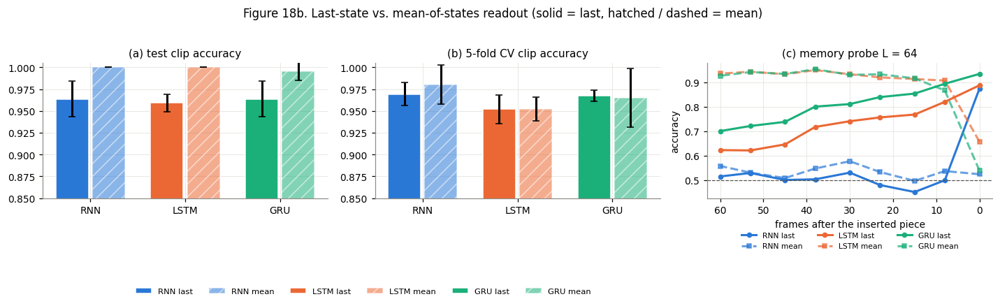

In [36]:
rows = []
for c in CELLS:
    for ro in ["last", "mean"]:
        for s in SEEDS:
            r = MAIN[(c, s)] if ro == "last" else TR.train_run(f"mainmean_{c}_s{s}", c, SPLIT, LABELS, STORE, {"readout": "mean", "seed": s})
            for level, d in [("video", r["videos"]), ("clip", r["clips"])]:
                rows.append({"model": c, "readout": ro, "eval": "test split", "seed": s, "level": level, **E.metrics(d.label, d.p_dirty)})
        for s in CV_SEEDS:
            rs = [CV[(c, s, k)] if ro == "last" else TR.train_run(f"cvmean_{c}_f{k}_s{s}", c, cv_split(k), LABELS, STORE, {"readout": "mean", "seed": s})
                  for k in range(5)]
            for level in ["videos", "clips"]:
                d = pd.concat([r[level] for r in rs])
                rows.append({"model": c, "readout": ro, "eval": "5-fold CV", "seed": s, "level": level[:-1], **E.metrics(d.label, d.p_dirty)})
READOUT = save(pd.DataFrame(rows), "readout_ablation_runs")
ro_tab = READOUT.groupby(["eval", "level", "model", "readout"])[["accuracy", "recall", "F1"]].agg(lambda x: pm(x)).unstack("readout")
display(save(ro_tab, "readout_ablation", index=True))

path = RES / "probe_readout_runs.csv"
PROBE_RO = pd.read_csv(path) if path.exists() else pd.DataFrame()
for c in CELLS:
    for s in [0, 1, 2]:
        if len(PROBE_RO) and ((PROBE_RO.model == f"{c} mean-readout") & (PROBE_RO.seed == s)).any():
            continue
        res, _, be = E.probe_run(c, PS["train"], PS["val"], PS["test"], 64, k=4, seed=s, epochs=60, steps=25,
                                 cfg={"lr": 1e-3, "dropout": 0.1}, readout="mean")
        res["model"] = f"{c} mean-readout"; PROBE_RO = pd.concat([PROBE_RO, res], ignore_index=True); PROBE_RO.to_csv(path, index=False)
pb = pd.concat([PROBE[PROBE.L == 64], PROBE_RO])
display(pb.groupby("model").accuracy.mean().round(3).rename("memory probe L=64, mean accuracy over positions").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for k, c in enumerate(CELLS):
    for j, ro in enumerate(["last", "mean"]):
        for a, ev in zip(axes[:2], ["test split", "5-fold CV"]):
            d = READOUT[(READOUT.model == c) & (READOUT.readout == ro) & (READOUT["eval"] == ev) & (READOUT.level == "clip")]
            a.bar(k * 2.6 + j, d.accuracy.mean(), 0.9, yerr=d.accuracy.std(), color=COL[c], alpha=1 if ro == "last" else 0.55,
                  hatch=None if ro == "last" else "//", edgecolor="white", capsize=3, label=f"{c} {ro}")
    for ro, ls in [("last", "o-"), ("mean", "s--")]:
        d = pb[pb.model == (c if ro == "last" else f"{c} mean-readout")].groupby("frames_after").accuracy.mean()
        axes[2].plot(d.index, d.values, ls, color=COL[c], label=f"{c} {ro}", ms=4, alpha=1 if ro == "last" else 0.7)
for a, t in zip(axes[:2], ["(a) test clip accuracy", "(b) 5-fold CV clip accuracy"]):
    a.set_xticks([0.5, 3.1, 5.7], CELLS); a.set(title=t, ylim=(0.85, 1.005))
fig.legend(*axes[0].get_legend_handles_labels(), ncol=6, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.36, -0.1))
axes[2].invert_xaxis(); axes[2].axhline(0.5, color="#52514e", lw=0.8, ls="--")
axes[2].set(title="(c) memory probe L = 64", xlabel="frames after the inserted piece", ylabel="accuracy"); axes[2].legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.suptitle("Figure 18b. Last-state vs. mean-of-states readout (solid = last, hatched / dashed = mean)", y=1.03)
fig.tight_layout(); savefig(fig, "fig18b_readout_ablation")

**Observations (temporal information).**

* **Frames vs. sequences.** A single frame is already classified correctly 98.0 % of the time, and averaging single-frame
  scores over a clip or video gives 1.000 on the test split and 1.000 video accuracy in CV. None of the recurrent models
  improves on this for whole-video clean / dirty labels: in these recordings the class is visible in almost every frame.
* **Order tests (Figure 16).** Shuffling or reversing the frames of a clip changes the recurrent P(dirty) by only about
  0.05 on average (the baselines are order-free by design), so the models use frame *content* far more than frame *order*.
  Every change of order even *raises* recurrent accuracy: reversing gives 1.000, shuffling 0.991--0.995, the repeated
  middle frame 0.973--0.982 and dropping every second frame 0.982--0.986 (original 0.959--0.964). Each of them moves the
  final waste-land frames of the D08 clips away from the end of the clip, where the recurrent models look most.
* **Where the decision comes from (Figure 17).** The vanilla RNN puts **99.7 % of its gradient on the last 4 frames**
  (76 % on the last frame alone): it effectively classifies the end of the clip. This is the vanishing-gradient behaviour
  of the plain tanh recurrence. The LSTM and GRU spread their attention back over about 8 frames (66 % on the last 4, 35 %
  on the last one), and their P(correct) rises during the first 4--8 frames (GRU 0.82 → 0.93, LSTM 0.78 → 0.89), i.e. they
  accumulate evidence. Mean pooling weights all 16 frames equally (6.25 % each).
* **Memory probe (Figure 18).** When order really matters, the cells separate clearly. Averaged over insert positions,
  accuracy is **GRU 0.85 / 0.81 / 0.81 / 0.79** for L = 16 / 32 / 64 / 128, LSTM 0.84 / 0.73 / 0.73 / 0.73 and RNN
  0.61 / 0.59 / 0.54 / 0.54. The RNN only answers correctly when the dirty piece comes at the very end (0.72--0.87) and is
  at chance a few frames earlier. The **RNN with 448 units (as many parameters as the LSTM) is no better** (0.51 at
  L = 128), so the gates, not the model size, provide the memory. The GRU is best on average; the LSTM forgets more slowly
  (its curve is flatter and, at L = 128, slightly better for the earliest insert: 0.68 vs. 0.66) but is less accurate for
  recent events. Order-free mean pooling dilutes a 2-s event among the other frames and falls to chance (0.51) at L = 128.
* **Readout ablation (Figure 18b).** Averaging the hidden states instead of taking the last one makes all three cells
  perfect on the test split (1.000) and lifts CV video accuracy to 1.000 (RNN), 0.989 (LSTM) and 0.966 (GRU). The D08
  error is therefore caused by the last-state readout, not by the cells. On the memory probe the averaged gated cells
  are excellent when the event happened early (≈ 0.93): once their state has switched to *dirty* it stays there, and many
  such states dominate the average. They fail, however, when the event is at the very end (0.54--0.66), because only a few
  states carry it. The averaged RNN stays at chance (0.53) because its state never stays switched.

In short, temporal modelling is **not needed** to tell clean from dirty videos in this dataset, because single frames
suffice. It **is needed** for event-type questions ("did garbage appear at some point?"), and there the gated cells (GRU,
then LSTM) are far better than the vanilla RNN.

## 9. Robustness to lighting, camera movement and environmental conditions

**Synthetic changes.** Every frame of the 7 test videos is altered in 11 ways before feature extraction, and the main
models (5 seeds each) score the altered clips. Lighting: dark (gamma + exposure drop + sensor noise), over-exposed, low
contrast, warm colour cast, flicker (brightness changes from frame to frame). Camera: shake (random shift / rotation /
zoom plus motion blur per frame), defocus blur. Environment: fog / haze, rain streaks, strong sensor noise, heavy JPEG
compression.

perturbed features ready (0 s; cached)


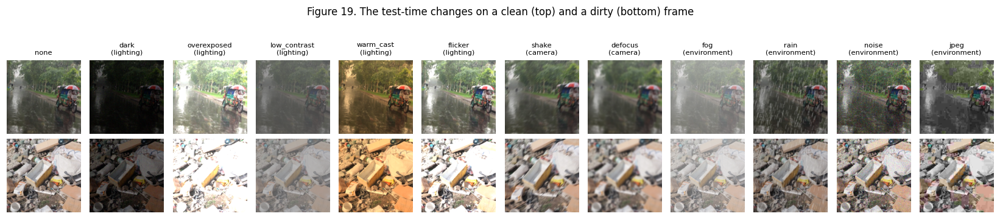

In [37]:
KINDS = [k for ks in D.PERTURBATIONS.values() for k in ks]
CAT = {k: g for g, ks in D.PERTURBATIONS.items() for k in ks}
t0 = time.time()
for k in KINDS:
    for v in SPLIT["test"]:
        D.video_features(v, k)
print(f"perturbed features ready ({time.time() - t0:.0f} s; cached)")
frames, _ = D.load_frames("C17")
frames2, _ = D.load_frames("D11")
fig, axes = plt.subplots(2, len(KINDS) + 1, figsize=(15, 3.2))
for i, fr in enumerate([frames[40:43], frames2[40:43]]):
    for j, k in enumerate(["none"] + KINDS):
        axes[i, j].imshow(square(D.perturb_sequence(fr, k, seed=1)[1], 200)); axes[i, j].axis("off")
        if i == 0: axes[i, j].set_title(k if k == "none" else f"{k}\n({CAT[k]})", fontsize=7.5)
fig.suptitle("Figure 19. The test-time changes on a clean (top) and a dirty (bottom) frame", y=1.04)
fig.tight_layout(); savefig(fig, "fig19_perturbation_examples")

change,none,dark,overexposed,low_contrast,warm_cast,flicker,shake,defocus,fog,rain,noise,jpeg
model,,,,,,,,,,,,
RNN,0.964,0.941,0.950,0.977,0.923,0.959,0.914,0.923,0.968,0.886,0.932,0.918
LSTM,0.959,0.945,0.941,0.982,0.909,0.964,0.914,0.923,0.973,0.905,0.923,0.877
GRU,0.964,0.927,0.950,0.977,0.932,0.964,0.909,0.914,0.964,0.900,0.900,0.895
MLP-frame,1.000,0.918,1.000,1.000,0.955,1.000,0.900,0.891,1.000,0.905,0.932,0.909
MLP-mean,1.000,0.932,1.000,1.000,0.936,0.995,0.900,0.891,1.000,0.900,0.927,0.964


category,camera,environment,lighting,none
model,,,,
RNN,0.918,0.926,0.950,0.964
LSTM,0.918,0.919,0.948,0.959
GRU,0.911,0.915,0.950,0.964
MLP-frame,0.895,0.936,0.975,1.000
MLP-mean,0.895,0.948,0.973,1.000


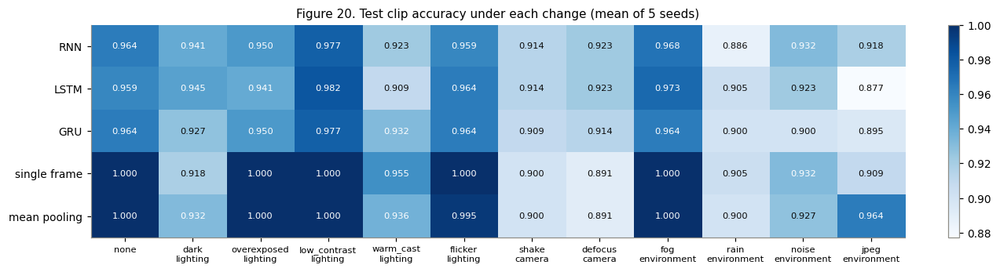

recall                                                       \
change      dark defocus flicker   fog  jpeg low_contrast noise  none   
model                                                                   
RNN         0.68    0.60    0.78  0.82  0.57         0.88  0.62  0.80   
LSTM        0.72    0.70    0.80  0.85  0.45         0.90  0.60  0.78   
GRU         0.60    0.57    0.80  0.82  0.52         0.88  0.45  0.80   
MLP-frame   0.55    0.40    1.00  1.00  0.50         1.00  0.62  1.00   
MLP-mean    0.62    0.40    0.98  1.00  0.80         1.00  0.60  1.00   

                             ... specificity                                 \
change    overexposed  rain  ...     flicker   fog  jpeg low_contrast noise   
model                        ...                                              
RNN              0.72  0.38  ...         1.0  1.00  0.99          1.0  1.00   
LSTM             0.68  0.48  ...         1.0  1.00  0.97          1.0  0.99   
GRU              0.72  0.57  ...         1.0  0.99  0.98          1.0  1.00   
MLP-frame        1.00  0.48  ...         1.0  1.00  1.00          1.0  1.00   
MLP-mean         1.00  0.45  ...         1.0  1.00  1.00          1.0  1.00   

                                                  
change    none overexposed  rain shake warm_cast  
model                                             
RNN        1.0         1.0  1.00   1.0      1.00  
LSTM       1.0         1.0  1.00   1.0      1.00  
GRU        1.0         1.0  0.97   1.0      0.99  
MLP-frame  1.0         1.0  1.00   1.0      1.00  
MLP-mean   1.0         1.0  1.00   1.0      1.00  

[5 rows x 24 columns]

In [38]:
PST = {k: TR.Store(SPLIT["test"], kind=k) for k in KINDS}
rows = []
for c in ALL:
    for s in SEEDS:
        m, _ = TR.load_model(f"main_{c}_s{s}")
        for k in ["none"] + KINDS:
            cl = TR.predict_clips(m, STORE if k == "none" else PST[k], SPLIT["test"], 2.0, 16); cl["label"] = cl.vid.map(LABELS)
            vd = TR.video_scores(cl); vd["label"] = vd.vid.map(LABELS)
            mt = E.metrics(cl.label, cl.p_dirty)
            rows.append({"model": c, "seed": s, "change": k, "category": CAT.get(k, "none"), "clip_acc": mt["accuracy"],
                         "clip_F1": mt["F1"], "recall": mt["recall"], "specificity": mt["specificity"],
                         "video_acc": E.metrics(vd.label, vd.p_dirty)["accuracy"]})
ROB = save(pd.DataFrame(rows), "robustness_synthetic")
rb = ROB.groupby(["model", "change"]).clip_acc.mean().unstack().loc[ALL, ["none"] + KINDS]
display(rb.round(3))
display(ROB.groupby(["model", "category"]).clip_acc.mean().unstack().loc[ALL].round(3))
fig, ax = plt.subplots(figsize=(13, 3.2))
im = ax.imshow(rb.values, cmap="Blues", vmin=max(0.5, rb.values.min()), vmax=1, aspect="auto")
for i in range(rb.shape[0]):
    for j in range(rb.shape[1]):
        ax.text(j, i, f"{rb.values[i, j]:.3f}", ha="center", va="center", fontsize=7.5, color="white" if rb.values[i, j] > 0.93 else "#0b0b0b")
ax.set_xticks(range(rb.shape[1]), [k if k == "none" else f"{k}\n{CAT[k]}" for k in rb.columns], fontsize=7.5)
ax.set_yticks(range(len(ALL)), [NICE[c] for c in ALL]); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.015)
ax.set_title("Figure 20. Test clip accuracy under each change (mean of 5 seeds)")
savefig(fig, "fig20_robustness_heatmap")
rr = ROB.groupby(["model", "change"])[["recall", "specificity"]].mean()
display(rr.unstack().loc[ALL].round(2))

**Natural conditions in the recordings.** The 29 videos already differ in light (sun, overcast, fog, rain, backlight, indoor)
and camera motion (static, pan, walking, vehicle, drone). Out-of-fold clip accuracy (§5) is broken down by these
conditions and plotted against the measured motion and brightness of each video.

RNN   LSTM    GRU  MLP-frame  MLP-mean
class lighting                                                 
Clean backlit sun      1.000  1.000  1.000      1.000       1.0
      cloudy           1.000  1.000  1.000      1.000       1.0
      fog              1.000  1.000  1.000      1.000       1.0
      hazy sun         1.000  1.000  1.000      1.000       1.0
      low evening sun  1.000  1.000  1.000      1.000       1.0
      overcast         1.000  1.000  1.000      1.000       1.0
      rain             1.000  1.000  1.000      1.000       1.0
      sunny            0.933  1.000  0.992      1.000       1.0
Dirty bright           0.667  0.444  0.222      1.000       1.0
      daylight         0.995  0.981  0.998      0.959       1.0
      hazy             0.000  0.000  0.000      0.500       0.5
      indoor           1.000  1.000  1.000      1.000       1.0

RNN   LSTM    GRU  MLP-frame  MLP-mean
class capture                                                
Clean handheld       1.000  1.000  1.000      1.000     1.000
      handheld pan   1.000  1.000  1.000      1.000     1.000
      handheld walk  0.933  1.000  1.000      1.000     1.000
      static         1.000  1.000  1.000      1.000     1.000
      vehicle        1.000  1.000  0.979      1.000     1.000
Dirty drone          0.651  0.608  0.661      0.786     0.833
      slider         1.000  1.000  1.000      1.000     1.000
      slow pan       1.000  1.000  1.000      1.000     1.000
      static         0.944  0.907  0.870      0.963     1.000

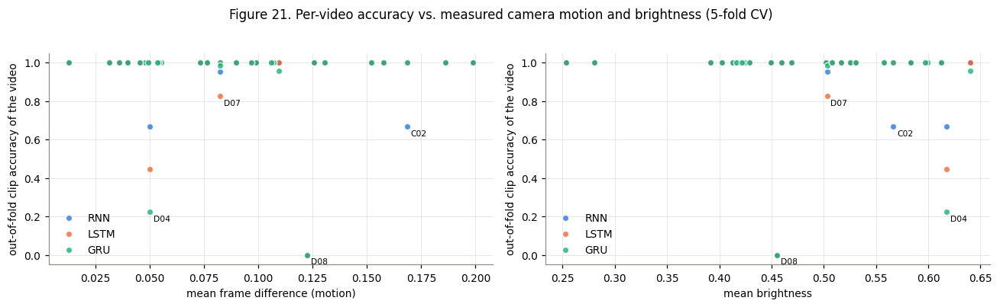

In [39]:
oc = OOF_C.copy(); oc["ok"] = (oc.p_dirty >= 0.5) == oc.label
pv = oc.groupby(["vid", "model"]).ok.mean().unstack()[ALL]
NAT = VIDEOS.set_index("vid")[["class", "lighting", "capture", "brightness", "motion"]].join(pv)
save(NAT.reset_index().round(4), "robustness_natural")
display(NAT.groupby(["class", "lighting"])[ALL].mean().round(3))
display(NAT.groupby(["class", "capture"])[ALL].mean().round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for c in CELLS:
    for a, key in zip(axes, ["motion", "brightness"]):
        a.scatter(NAT[key], NAT[c], s=30, color=COL[c], alpha=0.8, label=c, edgecolor="white", linewidth=1)
for a, key in zip(axes, ["mean frame difference (motion)", "mean brightness"]):
    a.set(xlabel=key, ylabel="out-of-fold clip accuracy of the video"); a.legend()
for v in NAT.index[NAT[CELLS].min(1) < 0.9]:
    axes[0].annotate(v, (NAT.loc[v, "motion"], NAT.loc[v, CELLS].min()), fontsize=7, xytext=(3, -8), textcoords="offset points")
    axes[1].annotate(v, (NAT.loc[v, "brightness"], NAT.loc[v, CELLS].min()), fontsize=7, xytext=(3, -8), textcoords="offset points")
fig.suptitle("Figure 21. Per-video accuracy vs. measured camera motion and brightness (5-fold CV)", y=1.03)
fig.tight_layout(); savefig(fig, "fig21_natural_conditions")

**Different camera and place: phone photographs of real campus garbage.** The dirty training videos are stock footage. To
test whether the models learned *garbage* rather than *stock-footage style*, they are applied to the 256 phone photographs
of Assignment 15 (140 clean, 116 dirty, mostly Rajshahi University campus), never seen in training. Each photo becomes a
16-frame pseudo-video with a smooth simulated camera move (pan and zoom between two random crops).

256 photos -> pseudo-videos (0 s; cached)


,model,level,accuracy,precision,recall,F1,AUC,specificity
0,RNN,photo,0.952 ± 0.009,0.991 ± 0.008,0.902 ± 0.018,0.944 ± 0.011,0.991 ± 0.002,0.993 ± 0.006
1,LSTM,photo,0.953 ± 0.008,0.966 ± 0.015,0.929 ± 0.015,0.947 ± 0.009,0.992 ± 0.003,0.973 ± 0.012
2,GRU,photo,0.961 ± 0.017,0.972 ± 0.019,0.941 ± 0.021,0.956 ± 0.019,0.992 ± 0.003,0.977 ± 0.015
3,MLP-frame,photo,0.977 ± 0.008,0.990 ± 0.020,0.959 ± 0.014,0.974 ± 0.008,0.994 ± 0.004,0.991 ± 0.017
4,MLP-mean,photo,0.964 ± 0.007,0.986 ± 0.016,0.934 ± 0.019,0.959 ± 0.008,0.991 ± 0.004,0.989 ± 0.013


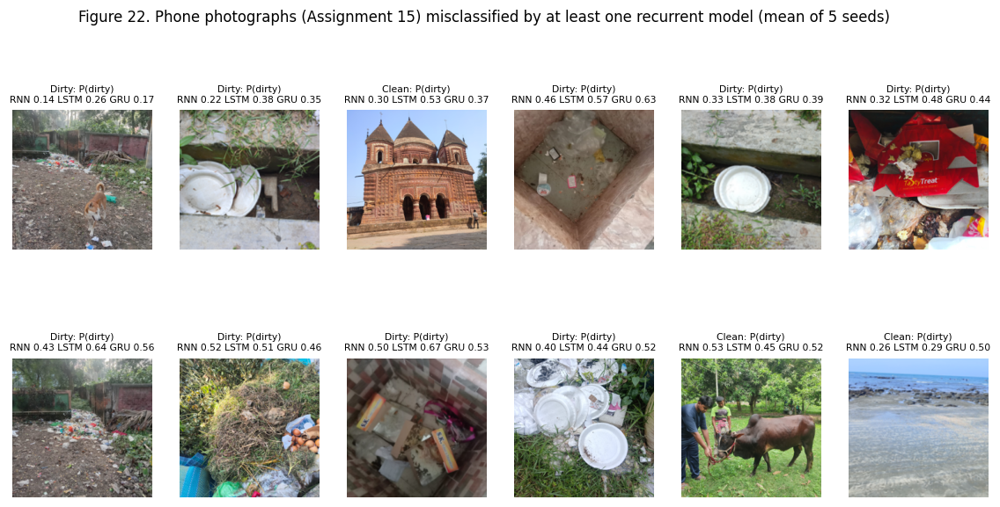

In [40]:
A15 = ROOT.parent / "15" / "data"
EXT = None
if A15.exists():
    files = sorted(A15.glob("clean/*")) + sorted(A15.glob("dirty/*"))
    t0 = time.time()
    XE = torch.stack([torch.from_numpy(D.external_features(f).astype(np.float32)) for f in files]).cuda()
    YE = np.array([0 if f.parent.name == "clean" else 1 for f in files])
    print(f"{len(files)} photos -> pseudo-videos ({time.time() - t0:.0f} s; cached)")
    rows, PE = [], {}
    for c in ALL:
        ps = []
        for s in SEEDS:
            m, _ = TR.load_model(f"main_{c}_s{s}")
            with torch.no_grad():
                p = m(XE, torch.full((len(XE),), 16)).softmax(-1)[:, 1].cpu().numpy()
            ps.append(p); rows.append({"model": c, "seed": s, **E.metrics(YE, p)})
        PE[c] = np.mean(ps, 0)
    EXT = save(pd.DataFrame(rows), "external_photos")
    display(summary_table(EXT.assign(level="photo"), KEYS + ["specificity"]))
    ex = np.array(list(Path(f).name for f in files))
    wrong = np.where(((PE["GRU"] >= 0.5) != YE) | ((PE["LSTM"] >= 0.5) != YE) | ((PE["RNN"] >= 0.5) != YE))[0]
    from PIL import Image, ImageOps
    sel = list(wrong[np.argsort(-np.abs(PE["GRU"][wrong] - 0.5))][:12])
    if sel:
        fig, axes = plt.subplots(2, 6, figsize=(13, 5.8), gridspec_kw={"hspace": 0.35})
        for a, i in zip(axes.flat, sel):
            im = ImageOps.exif_transpose(Image.open(files[i])).convert("RGB"); im.thumbnail((400, 400))
            a.imshow(square(np.asarray(im))); a.axis("off")
            a.set_title(f"{D.CLASSES[YE[i]]}: P(dirty)\nRNN {PE['RNN'][i]:.2f} LSTM {PE['LSTM'][i]:.2f} GRU {PE['GRU'][i]:.2f}", fontsize=7)
        for a in axes.flat[len(sel):]: a.axis("off")
        fig.suptitle("Figure 22. Phone photographs (Assignment 15) misclassified by at least one recurrent model (mean of 5 seeds)", y=1.02)
        savefig(fig, "fig22_external_errors")
else:
    print("Assignment 15 photos not found -- external test skipped")

**Observations (robustness).**

* **Synthetic changes (Figures 19, 20).** Averaged over the 11 changes, recurrent clip accuracy falls from 0.96 to
  0.930--0.936, and the baselines from 1.000 to 0.946--0.950. The damaging changes are those that **destroy fine texture**:
  rain streaks (0.886--0.905), heavy JPEG compression (0.877--0.918), strong noise (0.900--0.932), camera shake with motion
  blur (0.909--0.914) and defocus (0.914--0.923). Darkness costs a little (0.927--0.945), while flicker, fog, low contrast
  and over-exposure hardly matter. Specificity stays ≥ 0.97 under every change; the losses are **missed dirty clips** (recall
  under rain drops to 0.38--0.57). Blurred or noisy litter starts to look like a plain surface, so the models answer
  *Clean*. No cell is consistently the most robust: the LSTM is best under darkness, fog and rain, the RNN under JPEG and
  noise, and all three are within 0.006 of each other on average. Recurrence does not protect against per-frame shake or
  flicker either: the order-free baselines are about as robust (shake 0.900, flicker 0.995--1.000).
* **Natural conditions (Figure 21).** Every clean video in fog (C09), rain (C16, C17), back-light (C07), low evening sun
  (C08) or filmed from a moving vehicle (C08, C11) is indexed correctly, with clip accuracy 0.96--1.00. The only weak clean
  video is C02 (inside a red slide tunnel, RNN 0.67). Per-video accuracy shows no trend with the measured camera motion or
  brightness. With 29 videos, and conditions that partly coincide with the class, this is indicative only.
* **Different camera and place.** On 256 phone photographs of the Rajshahi University campus, never seen in training,
  accuracy is 0.952 (RNN), 0.953 (LSTM) and **0.961 (GRU)**, with AUC 0.99 for all models (single frame 0.977, mean
  pooling 0.964). The models therefore recognise garbage, not only the style of stock footage. Figure 22 shows what they
  miss: sparse or small litter (a few plates in a drain, scattered items along a wall) and tight close-ups. The false
  alarms are a brick temple and a cow on grass.

## 10. Misclassified videos and clips

All test clips that were misclassified in any seed (main split) and every video with out-of-fold errors (CV) are listed.
Figure 23 shows frames of the most-missed videos together with the clip-by-clip P(dirty) of each model.

In [41]:
err = []
for (c, s), r in MAIN.items():
    cl = r["clips"]; w = cl[(cl.p_dirty >= 0.5) != cl.label]
    for _, q in w.iterrows():
        err.append({"model": c, "seed": s, "vid": q.vid, "clip": q.clip, "t_start": q.t_start, "t_end": q.t_end, "p_dirty": q.p_dirty})
ERR = pd.DataFrame(err)
if len(ERR):
    display(ERR.groupby(["vid", "model"]).size().unstack(fill_value=0).reindex(columns=ALL, fill_value=0)
            .rename_axis(None, axis=1).assign(clips_in_video=lambda d: [int((MAIN[("GRU", 0)]["clips"].vid == v).sum()) for v in d.index]))
save(ERR, "main_misclassified_clips")
cv_err = oc.groupby(["vid", "model"]).ok.apply(lambda o: 1 - o.mean()).unstack()[ALL]
cv_vid = OOF_V.assign(wrong=(OOF_V.p_dirty >= 0.5) != OOF_V.label).groupby(["vid", "model"]).wrong.sum().unstack()[ALL]
tab = cv_err[cv_err.max(1) > 0].round(3).join(cv_vid.add_suffix(" wrong-seeds"), how="left")
tab = VIDEOS.set_index("vid")[["class", "scene", "lighting", "capture"]].join(tab, how="inner").sort_values("GRU", ascending=False)
display(save(tab.reset_index(), "cv_error_videos"))

,RNN,LSTM,GRU,MLP-frame,MLP-mean,clips_in_video
vid,,,,,,
D08,8,9,8,0,0,2


,vid,class,scene,lighting,capture,RNN,LSTM,GRU,MLP-frame,MLP-mean,RNN wrong-seeds,LSTM wrong-seeds,GRU wrong-seeds,MLP-frame wrong-seeds,MLP-mean wrong-seeds
0,D08,Dirty,garbage heap then waste land,hazy,drone,1.000,1.000,1.000,0.500,0.5,3,3,3,0,2
1,D04,Dirty,dump with sticks,bright,static,0.333,0.556,0.778,0.000,0.0,1,2,2,0,0
2,C11,Clean,sea beach from motorbike,sunny,vehicle,0.000,0.000,0.042,0.000,0.0,0,0,0,0,0
3,D07,Dirty,"landfill, top-down",daylight,drone,0.048,0.175,0.016,0.143,0.0,0,0,0,0,0
4,C02,Clean,"playground, slide tunnel",sunny,handheld walk,0.333,0.000,0.000,0.000,0.0,0,0,0,0,0
5,D01,Dirty,"burning roadside dump, smoke",daylight,static,0.000,0.000,0.000,0.222,0.0,0,0,0,0,0


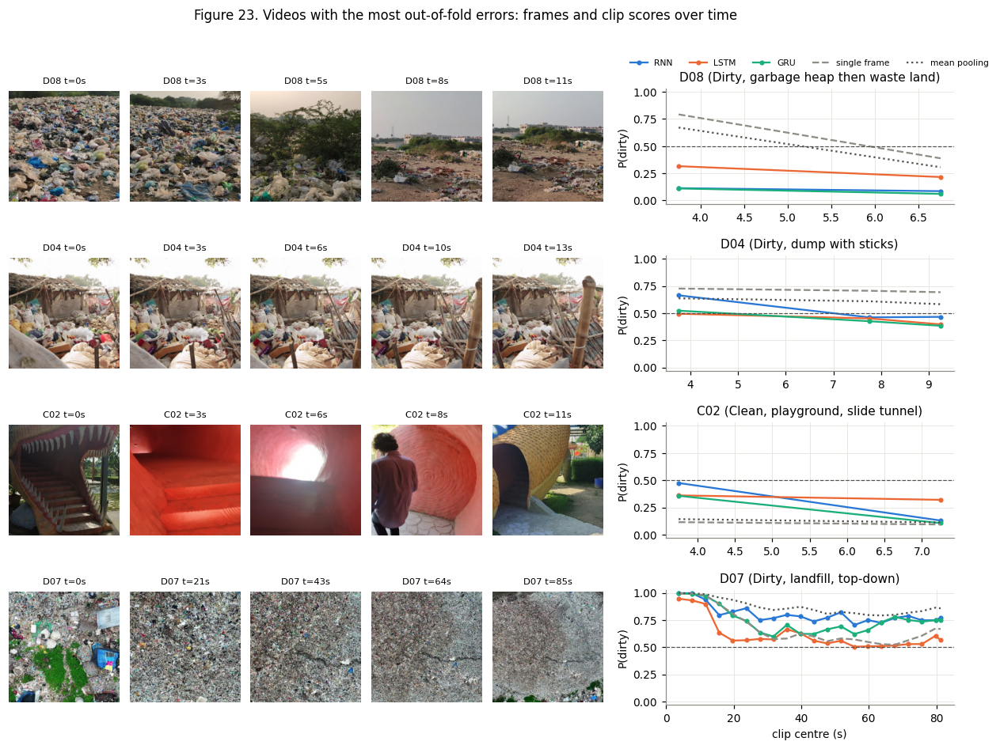

In [42]:
worst = cv_err[CELLS].mean(1).sort_values(ascending=False).index[:4].tolist()
fig = plt.figure(figsize=(14, 2.3 * len(worst)))
gs = fig.add_gridspec(len(worst), 7, width_ratios=[1] * 5 + [0.38, 2.6], wspace=0.08, hspace=0.45)
for i, v in enumerate(worst):
    frames, times = D.load_frames(v)
    for j, k in enumerate(np.linspace(0, len(frames) - 1, 5).astype(int)):
        a = fig.add_subplot(gs[i, j]); a.imshow(square(frames[k], 200)); a.axis("off"); a.set_title(f"{v} t={times[k]:.0f}s", fontsize=7.5)
    a = fig.add_subplot(gs[i, 6])
    for c in ALL:
        d = OOF_C[(OOF_C.vid == v) & (OOF_C.model == c)].groupby("clip")[["t_start", "t_end", "p_dirty"]].mean()
        a.plot((d.t_start + d.t_end) / 2, d.p_dirty, "o-" if c in CELLS else LS[c], color=COL[c], label=NICE[c], ms=3, lw=1.5)
    a.axhline(0.5, color="#52514e", lw=0.8, ls="--")
    a.set(ylim=(-0.03, 1.03), ylabel="P(dirty)", title=f"{v} ({VIDEOS.set_index('vid').loc[v, 'class']}, {VIDEOS.set_index('vid').loc[v, 'scene']})")
    if i == len(worst) - 1: a.set_xlabel("clip centre (s)")
    if i == 0: a.legend(fontsize=7, ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.12))
fig.suptitle("Figure 23. Videos with the most out-of-fold errors: frames and clip scores over time", y=0.98)
savefig(fig, "fig23_error_videos")

**Observations (error analysis).** All misclassified test clips of the main split belong to **D08**. Across the
cross-validation (Figure 23) four videos account for almost all errors:

* **D08** (drone over a garbage heap that turns into waste land after about 5 s). The first clip already ends on bushes,
  so the last-state readout sees mostly waste land and scores 0.1--0.3. The baselines, which weigh every frame equally,
  score 0.7--0.8 on the first clip. This is a temporal-aggregation error, fixed by the mean readout (§8.2).
* **D04** (dump with sticks under a bright, over-exposed sky). The scores of every model hover around 0.4--0.7; the large
  bright sky and the bamboo poles resemble the clean outdoor scenes.
* **D07** (85-s top-down drone shot of a landfill). After the first 15 s the frame is a uniform grey texture that looks
  like gravel, and the scores sink towards 0.5 (LSTM clips 0.83 correct). The video is still indexed *Dirty* by all models.
* **C02** (inside a red slide tunnel). This unusual close-up scene pushes the RNN close to 0.5 on one clip.

None of the errors is caused by lighting or camera motion as such. They come from content that changes within a video
(D08), from a scene that looks like the other class (D04, D07), or from an unusual scene (C02).

## 11. Video indexing and retrieval

**Two levels of indexing.**
* *Video index* -- each video gets **Clean** or **Dirty** from the mean clip score (§3). For the database every video is
  indexed by the cross-validation model that did **not** train on it (seed 0 of §5).
* *Timestamp index* -- *when* a dirty place is visible. A second set of models with the same three cells is trained on
  short windows (T = 4 frames = 2 s at 2 fps, otherwise the same recipe). Sliding the window over the video one frame
  (0.5 s) at a time gives a P(dirty) curve; runs above 0.5 lasting at least 1 s (gaps under 1 s merged) become the dirty
  segments stored with the video.

None of the 29 recordings switches between a clean and a dirty place, so timestamps are evaluated on **40 spliced test
streams**: clean | dirty | clean (| dirty | clean) pieces cut from the held-out test videos (clean pieces 8--30 s, dirty
pieces 4--16 s), with the true dirty intervals known. Frame-level F1, event-level F1 (a predicted segment matches a true
one when IoU ≥ 0.5), mean boundary error of matched events and the number of false segments are reported. The
single-frame baseline (window of 1) and the 16-frame video models used as a sliding window are compared with the 2-s
window models.

In [43]:
WIN = {(c, s): TR.train_run(f"win_{c}_s{s}", c, SPLIT, LABELS, STORE, {"T": 4, "seed": s}, save_weights=True) for c in CELLS for s in SEEDS}
COMP = E.make_composites(STORE, [v for v in SPLIT["test"] if LABELS[v] == 0], [v for v in SPLIT["test"] if LABELS[v] == 1], n=40, seed=0)
print(f"{len(COMP)} spliced streams, {sum(len(c['y']) for c in COMP) / 2 / 60:.1f} min in total, "
      f"{np.mean([c['y'].mean() for c in COMP]):.2f} of the time dirty")
rows = []
VARIANTS = [(f"{c} 2-s window", f"win_{c}_s", 4, c) for c in CELLS] + [(f"{c} 8-s window (video model)", f"main_{c}_s", 16, c) for c in CELLS] \
           + [("single frame", "main_MLP-frame_s", 1, "MLP-frame")]
TL_EX = {}
for name, prefix, W, c in VARIANTS:
    for s in SEEDS:
        m, _ = TR.load_model(f"{prefix}{s}")
        for i, comp in enumerate(COMP):
            p = E.timeline(m, comp["x"], W)
            rows.append({"variant": name, "model": c, "W": W, "seed": s, "stream": i, **E.localisation_scores(p, comp["y"], comp["t"])})
            if s == 0 and i < 2: TL_EX[(name, i)] = p
LOC = save(pd.DataFrame(rows), "localisation_runs")
LOC_SUM = LOC.groupby("variant", sort=False)[["frame_acc", "frame_F1", "event_precision", "event_recall", "event_F1", "boundary_err_s",
                                              "false_segments", "switches"]].mean()
display(save(LOC_SUM.round(3), "localisation_summary", index=True))

40 spliced streams, 39.7 min in total, 0.23 of the time dirty


,frame_acc,frame_F1,event_precision,event_recall,event_F1,boundary_err_s,false_segments,switches
variant,,,,,,,,
RNN 2-s window,0.961,0.906,0.930,0.965,0.943,0.735,0.165,3.600
LSTM 2-s window,0.961,0.900,0.970,0.958,0.962,0.682,0.035,3.060
GRU 2-s window,0.962,0.905,0.961,0.960,0.958,0.637,0.065,3.275
RNN 8-s window (video model),0.814,0.557,0.317,0.318,0.317,3.497,1.085,3.700
LSTM 8-s window (video model),0.835,0.582,0.489,0.478,0.481,2.883,0.810,3.370
GRU 8-s window (video model),0.827,0.575,0.450,0.442,0.445,3.069,0.910,3.520
single frame,0.979,0.945,0.952,0.962,0.953,0.370,0.090,3.360


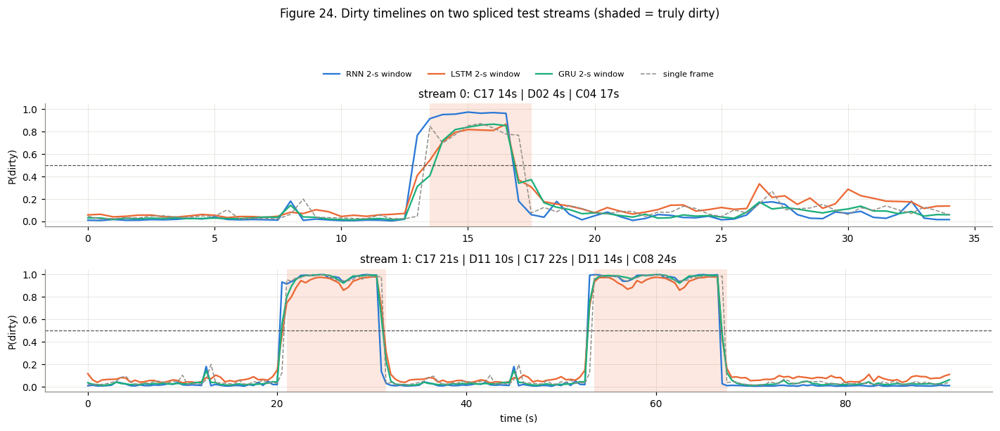

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(13, 5.2), sharey=True)
for i, a in enumerate(axes):
    comp = COMP[i]
    for (s0, e0) in E.segments(comp["y"].astype(bool), comp["t"], 0, 0):
        a.axvspan(s0, e0, color="#eb6834", alpha=0.15, lw=0)
    for name, prefix, W, c in VARIANTS:
        if "8-s" in name: continue
        a.plot(comp["t"], TL_EX[(name, i)], color=COL[c], ls=LS.get(c, "-"), lw=1.5 if c in CELLS else 1, label=name)
    a.axhline(0.5, color="#52514e", lw=0.8, ls="--")
    a.set(ylabel="P(dirty)", title=f"stream {i}: " + " | ".join(f"{v} {n / 2:.0f}s" for v, n in comp["sources"]))
axes[-1].set_xlabel("time (s)"); axes[0].legend(fontsize=7.5, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.15))
fig.suptitle("Figure 24. Dirty timelines on two spliced test streams (shaded = truly dirty)", y=1.06)
fig.tight_layout(); savefig(fig, "fig24_localisation_examples")

### 11.1 Building the index

Every video is stored with its out-of-fold P(dirty) and index label from each of the three models, its dirty segments
from the out-of-fold window model, a thumbnail and a browser-playable preview. The index lives in `outputs/index/`.

In [45]:
IDX = ROOT / "outputs" / "index"; (IDX / "thumbs").mkdir(parents=True, exist_ok=True)
CVWIN = {(c, k): TR.train_run(f"cvwin_{c}_f{k}_s0", c, cv_split(k), LABELS, STORE, {"T": 4, "seed": 0}, save_weights=True)
         for c in CELLS for k in range(5)}
fold = dict(zip(VIDEOS.vid, VIDEOS.fold))
index = VIDEOS[["vid", "name", "file", "class", "scene", "lighting", "capture", "duration_s", "split", "fold"]].rename(columns={"class": "true_class"}).copy()
TIMELINES = {c: {} for c in CELLS}
for c in CELLS:
    pv, lab, segs = [], [], []
    for v in index.vid:
        r = CV[(c, 0, fold[v])]["videos"].set_index("vid").loc[v]
        pv.append(float(r.p_dirty)); lab.append(D.CLASSES[int(r.p_dirty >= 0.5)])
        m, _ = TR.load_model(f"cvwin_{c}_f{fold[v]}_s0")
        x, t = E.sampled(STORE, v, 2.0)
        p = E.timeline(m, x, 4)
        TIMELINES[c][v] = {"t": [round(float(a), 2) for a in t], "p": [round(float(a), 4) for a in p]}
        segs.append(json.dumps([[round(float(a), 1), round(float(b), 1)] for a, b in E.segments(p >= 0.5, t)]))
    index[f"p_dirty_{c}"], index[f"index_{c}"], index[f"segments_{c}"] = pv, lab, segs
for v in index.vid:
    cv2.imwrite(str(IDX / "thumbs" / f"{v}.jpg"), cv2.cvtColor(square(middle_frame(v), 240), cv2.COLOR_RGB2BGR))
index.to_csv(IDX / "video_index.csv", index=False)
(IDX / "timelines.json").write_text(json.dumps(TIMELINES))
display(index[["vid", "true_class", "duration_s"] + [f"{k}_{c}" for c in CELLS for k in ("index", "p_dirty")] + ["segments_GRU"]].round(3))

,vid,true_class,duration_s,index_RNN,p_dirty_RNN,index_LSTM,p_dirty_LSTM,index_GRU,p_dirty_GRU,segments_GRU
0,C01,Clean,50.498,Clean,0.008,Clean,0.037,Clean,0.010,[]
1,C02,Clean,11.300,Clean,0.372,Clean,0.333,Clean,0.214,[]
2,C03,Clean,17.030,Clean,0.114,Clean,0.125,Clean,0.145,[]
3,C04,Clean,16.667,Clean,0.141,Clean,0.241,Clean,0.292,[]
4,C05,Clean,11.167,Clean,0.291,Clean,0.157,Clean,0.138,[]
5,C06,Clean,16.598,Clean,0.030,Clean,0.101,Clean,0.081,[]
6,C07,Clean,48.798,Clean,0.126,Clean,0.086,Clean,0.128,[]
7,C08,Clean,63.854,Clean,0.013,Clean,0.076,Clean,0.044,[]
8,C09,Clean,56.697,Clean,0.045,Clean,0.062,Clean,0.053,[]
9,C10,Clean,16.264,Clean,0.117,Clean,0.242,Clean,0.170,"[[12.0, 14.0]]"


### 11.2 Search and retrieval

`app.py` holds the retrieval logic (`VideoIndex.search`) and a small Gradio interface: choose **Clean**, **Dirty** or
**All** and an indexing model, optionally a minimum confidence and a text filter; the matching videos appear as thumbnails
and a table; picking one plays it next to its dirty timeline and the list of dirty timestamps. A second tab indexes a newly
uploaded video with the main-split models. Run `python app.py` to open it in the browser.

In [46]:
%%writefile app.py
"""Clean / Dirty video index: search, retrieve and play videos by their index label, see when dirty places appear,
and index a new video.  Run:  python app.py   (needs outputs/index from code.ipynb, section 11)."""
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import vi_data as D
import vi_train as TR
import vi_eval as E

ROOT = Path(__file__).resolve().parent
IDX = ROOT / "outputs" / "index"
MODELS = ["GRU", "LSTM", "RNN"]
FPS, T, W = 2.0, 16, 4                     # video model: 16 frames at 2 fps; timestamp model: 2-s windows


class VideoIndex:
    def __init__(self):
        self.df = pd.read_csv(IDX / "video_index.csv")
        self.timelines = json.loads((IDX / "timelines.json").read_text())
        self._models = {}

    # ------------------------------------------------------------------ search
    def search(self, category="Dirty", model="GRU", min_conf=0.5, query=""):
        """Videos whose index (by `model`) equals `category` ('All' = every video), most confident first."""
        df = self.df.copy()
        df["confidence"] = np.where(df[f"index_{model}"] == "Dirty", df[f"p_dirty_{model}"], 1 - df[f"p_dirty_{model}"])
        if category != "All":
            df = df[df[f"index_{model}"] == category]
        df = df[df.confidence >= min_conf]
        if query:
            df = df[df.name.str.contains(query, case=False) | df.scene.str.contains(query, case=False)]
        return df.sort_values("confidence", ascending=False)

    def segments(self, vid, model):
        return json.loads(self.df.set_index("vid").loc[vid, f"segments_{model}"])

    # ------------------------------------------------------------------ new videos
    def models(self, cell):
        if cell not in self._models:
            self._models[cell] = (TR.load_model(f"main_{cell}_s0")[0], TR.load_model(f"win_{cell}_s0")[0])
        return self._models[cell]

    @torch.no_grad()
    def index_video(self, path, cell="GRU"):
        """Decodes a new video at 2 fps, extracts ResNet-50 features and returns (P(dirty), label, times, timeline, segments)."""
        import cv2
        c = cv2.VideoCapture(str(path))
        fps = c.get(cv2.CAP_PROP_FPS) or 30.0
        n = int(c.get(cv2.CAP_PROP_FRAME_COUNT))
        times, idx = D.sample_indices(n, fps, FPS)
        want, frames = set(idx.tolist()), []
        for i in range(int(idx.max()) + 1):
            ok, fr = c.read() if i in want else (c.grab(), None)
            if not ok:
                break
            if fr is not None:
                frames.append(cv2.cvtColor(D.resize_short(fr), cv2.COLOR_BGR2RGB))
        c.release()
        x = torch.from_numpy(D.frame_features(frames)).cuda()
        vid_model, win_model = self.models(cell)
        clips = [x[s] for s in TR.eval_clips(len(x), D.BASE_FPS, T)]   # x is already at 2 fps -> step 1
        xb, L = TR.pad(clips)
        p = float(vid_model(xb, L).softmax(-1)[:, 1].mean())
        tl = E.timeline(win_model, x, W)
        t = times[:len(x)]
        return p, D.CLASSES[int(p >= 0.5)], t, tl, E.segments(tl >= 0.5, t)


def timeline_figure(t, p, segs, title):
    fig, ax = plt.subplots(figsize=(8, 2.2))
    ax.fill_between(t, p, step="mid", alpha=0.35, color="#c0392b")
    ax.plot(t, p, color="#c0392b", lw=1.2, drawstyle="steps-mid")
    for s, e in segs:
        ax.axvspan(s, e, color="#c0392b", alpha=0.12)
    ax.axhline(0.5, color="k", lw=0.6, ls="--")
    ax.set(ylim=(0, 1), xlabel="time (s)", ylabel="P(dirty)", title=title)
    fig.tight_layout()
    return fig


def fmt_segments(segs):
    return ", ".join(f"{int(s // 60)}:{s % 60:04.1f}–{int(e // 60)}:{e % 60:04.1f}" for s, e in segs) or "none"


def build_app():
    import gradio as gr
    index = VideoIndex()
    thumbs = ROOT / "outputs" / "index" / "thumbs"

    def do_search(category, model, min_conf, query):
        df = index.search(category, model, min_conf, query)
        gal = [(str(thumbs / f"{v}.jpg"), f"{v} · {lab} ({c:.2f})") for v, lab, c in zip(df.vid, df[f"index_{model}"], df.confidence)]
        table = df[["vid", "name", "scene", "duration_s", f"index_{model}", "confidence", "true_class"]].round(3)
        return gal, table, gr.update(choices=list(df.vid), value=df.vid.iloc[0] if len(df) else None)

    def do_show(vid, model):
        if not vid:
            return None, None, ""
        r = index.df.set_index("vid").loc[vid]
        tl = index.timelines[model][vid]
        segs = index.segments(vid, model)
        fig = timeline_figure(np.array(tl["t"]), np.array(tl["p"]), segs, f"{vid}: index = {r[f'index_{model}']}")
        info = (f"**{r['name']}**  \nindex ({model}): **{r[f'index_{model}']}**, P(dirty) = {r[f'p_dirty_{model}']:.3f}  \n"
                f"dirty segments: {fmt_segments(segs)}  \nground truth: {r['true_class']}")
        return str(ROOT / "outputs" / "previews" / f"{vid}.mp4"), fig, info

    def do_index(path, model):
        if not path:
            return None, ""
        p, lab, t, tl, segs = index.index_video(path, model)
        return timeline_figure(t, tl, segs, f"new video: {lab} (P(dirty) = {p:.2f})"), f"index: **{lab}**  \ndirty segments: {fmt_segments(segs)}"

    with gr.Blocks(title="Clean / Dirty video index") as demo:
        gr.Markdown("## Clean / Dirty video index\nSearch the indexed videos by label, play one, and see when dirty places appear.")
        with gr.Tab("Search"):
            with gr.Row():
                cat = gr.Radio(["Dirty", "Clean", "All"], value="Dirty", label="category")
                mdl = gr.Radio(MODELS, value="GRU", label="indexing model")
                conf = gr.Slider(0.5, 1.0, 0.5, step=0.05, label="min. confidence")
                q = gr.Textbox(label="text filter (file name / scene)")
            btn = gr.Button("Search", variant="primary")
            gal = gr.Gallery(columns=6, height=260, label="results")
            tab = gr.Dataframe(label="results", interactive=False)
            pick = gr.Dropdown(label="open video", choices=[])
            with gr.Row():
                vid = gr.Video(label="video", height=320)
                with gr.Column():
                    plot = gr.Plot(label="dirty timeline")
                    info = gr.Markdown()
            btn.click(do_search, [cat, mdl, conf, q], [gal, tab, pick])
            pick.change(do_show, [pick, mdl], [vid, plot, info])
        with gr.Tab("Index a new video"):
            up = gr.Video(label="upload a video")
            mdl2 = gr.Radio(MODELS, value="GRU", label="indexing model")
            go = gr.Button("Index", variant="primary")
            plot2, info2 = gr.Plot(), gr.Markdown()
            go.click(do_index, [up, mdl2], [plot2, info2])
    return demo


if __name__ == "__main__":
    plt.switch_backend("Agg")
    build_app().launch(allowed_paths=[str(ROOT / "outputs")])

Overwriting app.py


In [47]:
import app as APP
importlib.reload(APP)
VI = APP.VideoIndex()
rows = []
for c in CELLS:
    for cat_ in ["Dirty", "Clean"]:
        hits = VI.search(cat_, c)
        rel = (VIDEOS["class"] == cat_).sum(); tp = (hits.true_class == cat_).sum()
        rows.append({"model": c, "query": cat_, "retrieved": len(hits), "relevant in database": rel, "correct": tp,
                     "precision": tp / max(1, len(hits)), "recall": tp / rel})
RETR = save(pd.DataFrame(rows), "retrieval_quality")
display(RETR.round(3))
print("search('Dirty', model='GRU') ->")
display(VI.search("Dirty", "GRU")[["vid", "name", "confidence", "true_class", "segments_GRU"]].round(3).head(15))

,model,query,retrieved,relevant in database,correct,precision,recall
0,RNN,Dirty,11,12,11,1.000,0.917
1,RNN,Clean,18,17,17,0.944,1.000
2,LSTM,Dirty,11,12,11,1.000,0.917
3,LSTM,Clean,18,17,17,0.944,1.000
4,GRU,Dirty,11,12,11,1.000,0.917
5,GRU,Clean,18,17,17,0.944,1.000


search('Dirty', model='GRU') ->


,vid,name,confidence,true_class,segments_GRU
22,D06,4279368-hd_1920_1080_30fps.mp4,0.994,Dirty,"[[0.0, 18.0]]"
27,D11,vecteezy_pollution-concept-garbage-pile-in-tra...,0.988,Dirty,"[[0.0, 15.5]]"
19,D03,3186589-uhd_3840_2160_30fps.mp4,0.978,Dirty,"[[0.0, 36.0]]"
21,D05,3999624-uhd_3840_2160_24fps.mp4,0.977,Dirty,"[[0.0, 9.5]]"
18,D02,2952132-uhd_4096_2160_24fps.mp4,0.959,Dirty,"[[0.0, 12.5]]"
25,D09,4855723-hd_1920_1080_25fps.mp4,0.903,Dirty,"[[0.0, 12.5]]"
26,D10,vecteezy_plastic-trash-waste-moving-on-a-conve...,0.901,Dirty,"[[0.0, 15.0]]"
28,D12,vecteezy_river-garbage-pollution_2015570.mov,0.877,Dirty,"[[0.0, 14.5]]"
17,D01,12487565_1920_1080_30fps.mp4,0.759,Dirty,"[[0.0, 12.0]]"
23,D07,4445847-uhd_3840_2160_30fps.mp4,0.755,Dirty,"[[0.0, 85.5]]"


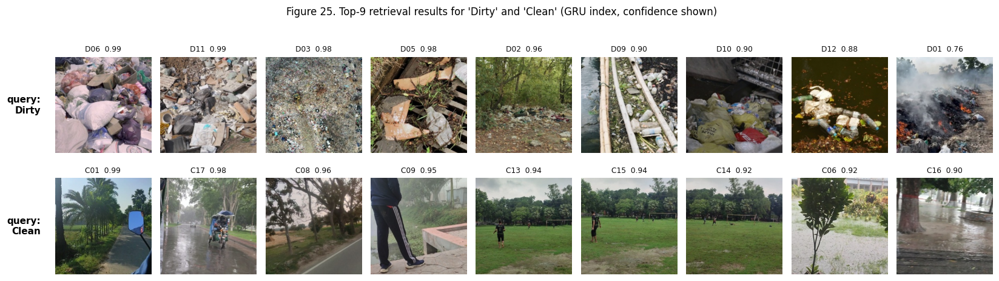

In [48]:
fig, axes = plt.subplots(2, 9, figsize=(15, 4.3))
for i, cat_ in enumerate(["Dirty", "Clean"]):
    hits = VI.search(cat_, "GRU").head(9)
    for a in axes[i]: a.axis("off")
    for a, (_, h) in zip(axes[i], hits.iterrows()):
        a.imshow(cv2.cvtColor(cv2.imread(str(IDX / "thumbs" / f"{h.vid}.jpg")), cv2.COLOR_BGR2RGB))
        ok = h.true_class == cat_
        a.set_title(f"{h.vid}  {h.confidence:.2f}" + ("" if ok else "  ✗"), fontsize=8, color="#0b0b0b" if ok else "#e34948")
    axes[i, 0].text(-0.15, 0.5, f"query:\n{cat_}", transform=axes[i, 0].transAxes, ha="right", va="center", fontsize=10, weight="bold")
fig.suptitle("Figure 25. Top-9 retrieval results for 'Dirty' and 'Clean' (GRU index, confidence shown)", y=1.02)
fig.tight_layout(); savefig(fig, "fig25_retrieval")

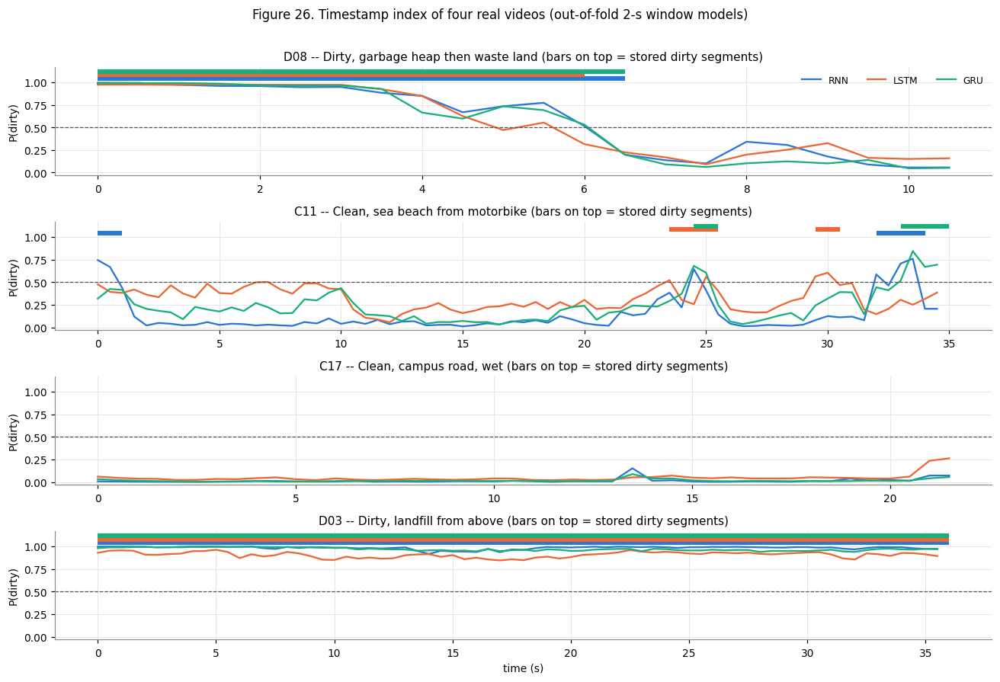

In [49]:
show = ["D08", "C11", "C17", "D03"]
fig, axes = plt.subplots(len(show), 1, figsize=(12, 2.0 * len(show)), sharey=True)
for a, v in zip(axes, show):
    for c in CELLS:
        tl = TIMELINES[c][v]; a.plot(tl["t"], tl["p"], color=COL[c], label=c, lw=1.5)
        for s0, e0 in json.loads(index.set_index("vid").loc[v, f"segments_{c}"]):
            a.plot([s0, e0], [1.04 + 0.04 * CELLS.index(c)] * 2, color=COL[c], lw=4, solid_capstyle="butt")
    a.axhline(0.5, color="#52514e", lw=0.8, ls="--")
    r = index.set_index("vid").loc[v]
    a.set(ylim=(-0.03, 1.17), ylabel="P(dirty)", title=f"{v} -- {r.true_class}, {r.scene} (bars on top = stored dirty segments)")
axes[0].legend(ncol=3, fontsize=8); axes[-1].set_xlabel("time (s)")
fig.suptitle("Figure 26. Timestamp index of four real videos (out-of-fold 2-s window models)", y=1.01)
fig.tight_layout(); savefig(fig, "fig26_real_timelines")

**Indexing a new video end-to-end** (decode at 2 fps → ResNet-50 → main-split GRU), as the interface does for an upload,
and a check that the interface builds. Set `LAUNCH_APP = True` to open it from here.

In [50]:
v = "C17"; t0 = time.time()
p, lab, t, tl, segs = VI.index_video(D.DATA / VIDEOS.set_index("vid").loc[v, "file"], "GRU")
print(f"{v}: index = {lab}, P(dirty) = {p:.3f}, dirty segments: {APP.fmt_segments(segs)}  ({time.time() - t0:.1f} s for a "
      f"{VIDEOS.set_index('vid').loc[v, 'duration_s']:.0f}-s video)")
demo = APP.build_app()
print("Gradio interface built:", type(demo).__name__)
LAUNCH_APP = False
if LAUNCH_APP:
    demo.launch(allowed_paths=[str(ROOT / "outputs")])

C17: index = Clean, P(dirty) = 0.022, dirty segments: none  (0.7 s for a 22-s video)


Gradio interface built: Blocks


**Observations (indexing and retrieval).**

* **Timestamps on spliced streams.** The 2-s window models find the dirty intervals well: event F1 is 0.943 (RNN),
  **0.962 (LSTM)** and 0.958 (GRU), frame F1 about 0.90, and the boundary error 0.64--0.74 s. The LSTM produces the fewest
  false segments (0.04 per stream vs. 0.17 for the RNN). The single-frame classifier is as good (event F1 0.953, frame F1
  0.945) and has the sharpest boundaries (0.37 s), because a 2-s window smears a cut over about 1 s. Using the 8-s video
  models as sliding windows fails (event F1 0.32--0.48, boundary error about 3 s). **Whole-video indexing and timestamp
  indexing therefore need different models**: long clips to decide what a video is, short windows to decide when garbage is
  visible. Figure 24 shows that the RNN jumps fastest at a cut (it follows the newest frame), while the LSTM and GRU respond
  slightly more smoothly.
* **Index and retrieval.** Indexed by the out-of-fold models, 28 of the 29 videos receive their true label. The only
  miss, D08, is indexed *Clean* by all three models. A *Dirty* query therefore returns 11 videos with **precision 1.000
  and recall 0.917**, and a *Clean* query returns 18 with precision 0.944 and recall 1.000 (Figure 25). The timestamp index
  rescues D08: its stored dirty segment is **0:00--0:06.5** for all three models (Figure 26), matching the garbage heap.
  A practical rule for a real system is to index a video as *Dirty* when it contains a dirty segment of at least 1 s.
  The beach video C11 gets a few short false dirty segments near its end (sand and rocks seen from a motorbike). Indexing
  a new 22-s video end-to-end (decoding, features, GRU, timeline) takes 0.6 s.

## 12. Comparative performance table

In [51]:
def mean_of(df, model, key, **flt):
    d = df[df.model == model]
    for k, v in flt.items(): d = d[d[k] == v]
    return d[key].mean()

rows = []
cx = COMPLEXITY.set_index("model")
for c in ALL:
    r = {"model": NICE[c],
         "params (M)": cx.loc[c, "parameters"] / 1e6, "MACs/clip (M)": cx.loc[c, "MACs per clip (T=16)"] / 1e6,
         "GPU ms/clip": cx.loc[c, "GPU latency (ms/clip)"], "CPU ms/clip": cx.loc[c, "CPU latency (ms/clip)"],
         "test video acc": mean_of(MAIN_RUNS, c, "accuracy", level="video"), "test clip acc": mean_of(MAIN_RUNS, c, "accuracy", level="clip"),
         "test clip F1": mean_of(MAIN_RUNS, c, "F1", level="clip"), "test clip AUC": mean_of(MAIN_RUNS, c, "AUC", level="clip"),
         "CV video acc": mean_of(CV_RUNS, c, "accuracy", level="video"), "CV clip acc": mean_of(CV_RUNS, c, "accuracy", level="clip"),
         "CV clip F1": mean_of(CV_RUNS, c, "F1", level="clip"),
         "perturbed clip acc": ROB[(ROB.model == c) & (ROB.change != "none")].clip_acc.mean(),
         "worst perturbation": ROB[(ROB.model == c) & (ROB.change != "none")].groupby("change").clip_acc.mean().min(),
         "phone photo acc": EXT[EXT.model == c].accuracy.mean() if EXT is not None else np.nan}
    lbl = "MLP-mean" if c == "MLP-mean" else c
    r["memory probe L=128"] = PROBE[(PROBE.model == lbl) & (PROBE.L == 128)].accuracy.mean() if lbl in set(PROBE.model) else np.nan
    loc = LOC[(LOC.model == c) & (LOC.W.isin([4, 1]))]
    r["timestamp event F1"] = loc.event_F1.mean() if len(loc) else np.nan
    rows.append(r)
COMPARE = save(pd.DataFrame(rows), "comparative_table")
display(COMPARE.set_index("model").T.round(4))

model,RNN,LSTM,GRU,single frame,mean pooling
params (M),0.2790,1.1154,0.8366,0.2625,0.2625
MACs/clip (M),4.4565,17.8259,13.3694,4.1944,0.2622
GPU ms/clip,0.4986,0.7224,0.5618,0.2749,0.2315
CPU ms/clip,0.2654,0.5010,0.5238,0.1367,0.0961
test video acc,0.8857,0.8571,0.8857,1.0000,1.0000
test clip acc,0.9636,0.9591,0.9636,1.0000,1.0000
test clip F1,0.8857,0.8724,0.8857,1.0000,1.0000
test clip AUC,0.9917,0.9993,0.9944,1.0000,1.0000
CV video acc,0.9540,0.9425,0.9425,1.0000,0.9770
CV clip acc,0.9695,0.9521,0.9673,0.9695,0.9935


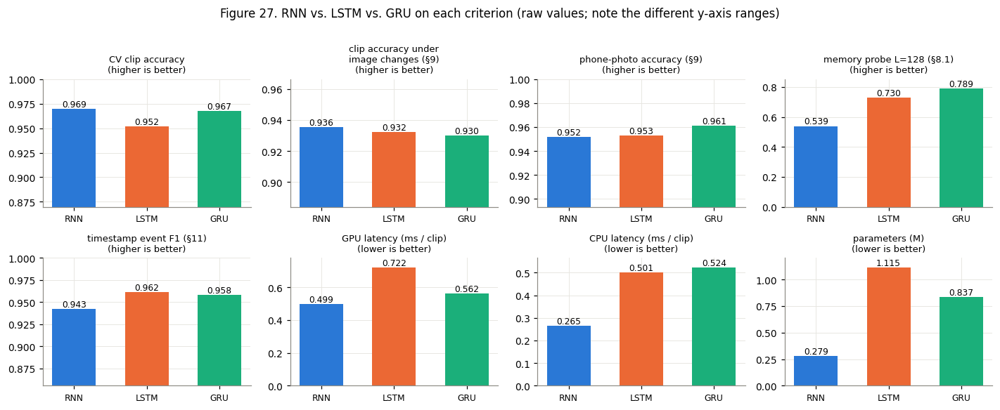

In [52]:
crit = [("CV clip accuracy", "CV clip acc", "higher"), ("clip accuracy under\nimage changes (§9)", "perturbed clip acc", "higher"),
        ("phone-photo accuracy (§9)", "phone photo acc", "higher"), ("memory probe L=128 (§8.1)", "memory probe L=128", "higher"),
        ("timestamp event F1 (§11)", "timestamp event F1", "higher"), ("GPU latency (ms / clip)", "GPU ms/clip", "lower"),
        ("CPU latency (ms / clip)", "CPU ms/clip", "lower"), ("parameters (M)", "params (M)", "lower")]
cm = COMPARE.set_index("model").loc[[NICE[c] for c in CELLS]]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2))
for a, (title, col, better) in zip(axes.flat, crit):
    vals = cm[col].values
    a.bar(CELLS, vals, color=[COL[c] for c in CELLS], width=0.6)
    for i, v in enumerate(vals):
        a.text(i, v, f"{v:.3f}" if v < 10 else f"{v:.0f}", ha="center", va="bottom", fontsize=8)
    lo = 0 if better == "lower" or col.startswith("memory") else max(0, vals.min() - 3 * (vals.max() - vals.min() + 0.01))
    a.set_ylim(lo, vals.max() * 1.08 if lo == 0 else min(1.0, vals.max() + 0.6 * (vals.max() - lo)))
    a.set_title(f"{title}\n({better} is better)", fontsize=8.5); a.tick_params(axis="x", labelsize=8)
fig.suptitle("Figure 27. RNN vs. LSTM vs. GRU on each criterion (raw values; note the different y-axis ranges)", y=1.01)
fig.tight_layout(); savefig(fig, "fig27_criteria")

### Conclusions

| criterion | RNN | LSTM | GRU | evidence |
|---|---|---|---|---|
| whole-video classification | **0.954** | 0.943 | 0.943 | CV video accuracy; all within seed noise, all below single frames (1.000) |
| temporal memory | 0.54 | 0.73 | **0.79** | memory probe, L = 128; RNN only sees the last 2--3 frames |
| robustness (synthetic) | 0.936 | 0.932 | 0.930 | mean clip accuracy over 11 changes; no consistent winner |
| new camera / place | 0.952 | 0.953 | **0.961** | Assignment 15 phone photos |
| timestamps | 0.943 | **0.962** | 0.958 | event F1 on spliced streams |
| parameters | **0.28 M** | 1.12 M | 0.84 M | |
| CPU latency, 16-frame clip | **0.27 ms** | 0.50 ms | 0.52 ms | GPU: 0.5--0.7 ms for all; decoding (1.1 s / min) dominates the pipeline |

* **Which architecture gives the best balance? The GRU.** Its classification accuracy matches the RNN within noise. It has
  the best temporal memory, the best accuracy on the unseen phone photos and almost the LSTM's timestamp quality, while
  using 25 % fewer parameters and multiply-accumulates than the LSTM. The cost advantage of the RNN (4x fewer parameters,
  2x faster on the CPU) is irrelevant in practice, because the recurrent head takes under 1 % of the indexing time. Its
  inability to keep information for more than a few frames is a real weakness for indexing. The LSTM brings no advantage
  over the GRU here except slightly fewer false timestamp segments; it is the largest model and the least confident.
* **Temporal information did not improve whole-video clean / dirty classification.** Single frames averaged over a video
  were perfect, and short clips (2--4 s) beat long ones. Temporal modelling matters for detecting *events* within long
  videos. The best video indexer is therefore a gated cell (GRU) with an averaging readout or short windows, combined with a
  timestamp index for when garbage appears.

**Limitations.** (1) Only 29 videos, and the test split has 7, so single videos move the metrics by several points; the
5-fold CV and multiple seeds reduce but do not remove this. (2) All dirty videos are stock footage and all clean videos come
from one phone, so class and source coincide: capture metadata alone indexes 86--90 % of the videos and colour statistics
90 %. The phone-photo test (§9) shows that the models also recognise real garbage, but new dirty videos filmed with the same
phone are the most important next step. (3) No recording switches between clean and dirty places, so timestamps were
evaluated on spliced streams with hard cuts, which are easier than gradual camera pans. (4) The image changes of §9 are
synthetic. (5) The CNN backbone is frozen and ImageNet-pretrained; fine-tuning it, or using a stronger image model, might
change the ranking of the heads only little, since the heads differ mainly in how they combine frames over time.

### Deliverables

In [53]:
deliv = [("1. collected and labelled video dataset", "data/clean, data/garbage; annotations/dataset.csv (label, group, split, fold, conditions)"),
         ("2. source code of the RNN, LSTM and GRU models", "vi_models.py (models), vi_train.py, vi_eval.py, vi_data.py, this notebook"),
         ("3. trained models and evaluation results", "outputs/runs/<run>/best.pt + test predictions; outputs/results/*.csv"),
         ("4. comparative performance table", "outputs/results/comparative_table.csv (§12)"),
         ("5. video indexing and retrieval system", "outputs/index/ (index, timelines, thumbnails), outputs/previews/, app.py"),
         ("6. figures for the report", f"outputs/figures/ ({len(list(FIG.glob('*.png')))} figures)")]
display(pd.DataFrame(deliv, columns=["deliverable", "where"]))
n_runs = len([p for p in TR.RUNS.iterdir() if (p / "result.json").exists()])
print(f"{n_runs} training runs cached, {len([p for p in TR.RUNS.glob('*/best.pt')])} weight files, "
      f"{len(list(RES.glob('*.csv')))} result tables")

,deliverable,where
0,1. collected and labelled video dataset,"data/clean, data/garbage; annotations/dataset...."
1,"2. source code of the RNN, LSTM and GRU models","vi_models.py (models), vi_train.py, vi_eval.py..."
2,3. trained models and evaluation results,outputs/runs/<run>/best.pt + test predictions;...
3,4. comparative performance table,outputs/results/comparative_table.csv (§12)
4,5. video indexing and retrieval system,"outputs/index/ (index, timelines, thumbnails),..."
5,6. figures for the report,outputs/figures/ (28 figures)


667 training runs cached, 80 weight files, 31 result tables
